<a href="https://colab.research.google.com/github/dhriti046/mic_prediction/blob/main/drive_linked_MIC_prediction_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Strain-Specific MIC Prediction of Antimicrobial Peptides Using Protein Language Models

Minimum inhibitory concentration (MIC) is one of the most important quantitative measurements of antimicrobial peptide activity because it directly captures the concentration required to inhibit microbial growth. DBAASP contains experimentally measured antimicrobial activities together with target species, experimental conditions, peptide sequences, and structural information, making it suitable for constructing strain-specific MIC prediction models.  This project will develop a reproducible pipeline to systematically collect MIC measurements from DBAASP, normalize heterogeneous activity units and experimental annotations, and construct a strain-aware dataset for quantitative MIC prediction. A pretrained protein language model such as ESM-2 will be fine-tuned with a regression head to predict log-transformed MIC values for individual bacterial strains, while sequence-identity-controlled evaluation will be used to assess whether the model generalizes beyond highly similar peptides. Recent work has already demonstrated the feasibility of BERT-based transfer learning for peptide MIC prediction against E. coli and S. aureus, providing a direct baseline for this project.

**Data Availability**

- DBAASP Data & API: [DBAASP](https://dbaasp.org/home) provides experimentally measured peptide activity against specific target species and currently exposes REST API functionality for peptide retrieval and search. The API supports peptide-card retrieval, target-species filtering, activity-measure filtering, and ranking searches, providing a programmatic alternative to manually downloading individual records.
- MIC Dataset Construction: Crawl/API-extract DBAASP peptide records and collect sequence, peptide ID, target species/strain, activity measure, MIC value, MIC unit, experimental conditions, reference, and associated metadata. Multiple measurements for the same peptide–strain combination will be retained initially rather than prematurely averaging experimentally distinct observations.
- Evaluation Baselines: Use conventional sequence descriptors with Random Forest/XGBoost as classical baselines and ESM-2 embeddings with a regression head as the primary modern protein-language-model baseline. A BERT/Transformer-based MIC predictor reported on DBAASP-derived E. coli and S. aureus datasets will provide an external methodological reference.

**Project Implementation Phases**

Phase 1: DBAASP MIC Data Collection & Dataset Construction

1. Develop a Python API/crawling pipeline to systematically retrieve DBAASP peptide records and extract all available antimicrobial activity measurements, prioritizing MIC entries and preserving peptide–target–measurement relationships. DBAASP currently supports target-species searches and activity ranking, while its API provides programmatic peptide retrieval.
2. Construct a normalized table containing peptide ID, sequence, target species/strain, MIC value, unit, activity-measure type, experimental conditions, reference, and peptide modifications, while retaining the original DBAASP values for traceability.
3. Normalize MIC measurements to a common unit and transform quantitative values using $\text{pMIC}=-\log_{10}(\text{MIC})$ after appropriate unit conversion, while separately flagging censored measurements such as $>$ or $<$ values rather than treating them as exact concentrations.
4. Remove unusable sequences, duplicate records, incompatible amino-acid representations, and measurements lacking sufficient target or activity information, then construct strain-specific datasets with sufficient observations for model training and evaluation.

Phase 2: Sequence Representation & MIC Prediction Baselines

1. Establish classical sequence baselines using AAC, DPC, physicochemical descriptors, and combined AAC+DPC representations followed by Random Forest and XGBoost regression.
2. Generate fixed-length peptide representations using a pretrained ESM-2 protein language model and compare mean-pooled residue embeddings against conventional sequence descriptors.
3. Fine-tune a lightweight Transformer/MLP regression head on frozen ESM-2 embeddings to predict continuous $\text{pMIC}$ values for individual microbial strains.
4. Evaluate models using MAE, RMSE, $R^2$, Pearson correlation, and Spearman correlation, with separate measurements for each major bacterial strain and an overall pooled evaluation.

Phase 3: Strain-Aware State-of-the-Art Model Development

1. Extend the ESM-2 model with a strain-conditioning representation by encoding the target bacterial strain as an additional learned embedding alongside the peptide representation.
2. Implement the prediction function as $ \hat{y}=f(z_{\text{peptide}},z_{\text{strain}})$, allowing the same peptide encoder to model differences in antimicrobial activity across different microbial targets.
3. Compare the strain-conditioned model against peptide-only ESM-2, classical machine-learning models, and a conventional Transformer MIC predictor using identical peptide-level splits and evaluation metrics.
4. Perform sequence-identity-controlled experiments, including a low-homology test set, to determine whether the model can predict MIC for previously unseen peptide sequences rather than relying primarily on closely related peptides.

Phase 4: Model Evaluation, Error Analysis & MIC Resource Generation

1. Perform cross-strain evaluation by training on multiple bacterial targets and testing on held-out strains where sufficient measurements are available, while separately reporting results for common and data-scarce strains.
2. Analyze prediction errors across MIC ranges, peptide lengths, sequence similarity, bacterial species, experimental conditions, and measurement uncertainty to identify the limitations of the learned model.
3. Compare predicted versus experimental MIC distributions and generate calibration, residual, correlation, and strain-specific performance plots to identify systematic prediction biases.
4. Release the resulting normalized peptide–strain–MIC dataset and reproducible extraction/modeling pipeline, subject to DBAASP’s data-use terms, together with the trained ESM-2-based MIC predictor and a benchmark comparing classical, sequence-language-model, and strain-conditioned approaches.

# Phase 1 — DBAASP Data Collection and Dataset Construction

Collect peptide records and activity measurements, preserve their source fields, then validate sequences, MIC values, units, and targets before defining model-ready records.

### 1.1 — MOUNT GOOGLE DRIVE

This step prepares or saves the data needed by the following steps.



In [1]:
import json
import time
import requests
from pathlib import Path
from google.colab import drive

# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount('/content/drive')

print("Google Drive successfully mounted.")

# ============================================================
# 2. DEFINE GOOGLE DRIVE DIRECTORIES
# ============================================================

DRIVE_DIR = Path("/content/drive/MyDrive/dbaasp_backup")

DRIVE_PAGES_DIR = DRIVE_DIR
DRIVE_DETAILS_DIR = DRIVE_DIR / "peptide_details"
DRIVE_PROCESSED_DIR = DRIVE_DIR / "processed"

# Create directories if they do not exist
DRIVE_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_DETAILS_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("\nGoogle Drive paths configured:")
print("Pages:", DRIVE_PAGES_DIR)
print("Details:", DRIVE_DETAILS_DIR)
print("Processed:", DRIVE_PROCESSED_DIR)

# ============================================================
# 3. CHECK EXISTING FILES IN GOOGLE DRIVE
# ============================================================

pages_count = len(list(DRIVE_PAGES_DIR.glob("offset_*.json")))
details_count = len(list(DRIVE_DETAILS_DIR.glob("*.json")))
processed_count = len(list(DRIVE_PROCESSED_DIR.iterdir()))

print("\nExisting files in Google Drive:")
print(f"Offset page JSON files: {pages_count}")
print(f"Peptide detail JSON files: {details_count}")
print(f"Processed files: {processed_count}")

# ============================================================
# 4. DBAASP API CONFIGURATION
# ============================================================

BASE_URL = "https://dbaasp.org/peptides"
PAGE_SIZE = 100

session = requests.Session()

session.headers.update({
    "Accept": "application/json",
    "User-Agent": "Mozilla/5.0"
})

# ============================================================
# 5. FETCH PEPTIDE DATA FROM API
# ============================================================

def fetch_page(offset):

    response = session.get(
        BASE_URL,
        params={
            "limit": PAGE_SIZE,
            "offset": offset
        },
        timeout=60
    )

    response.raise_for_status()

    result = response.json()

    if not isinstance(result, dict):
        raise ValueError("API response is not a JSON object.")

    if "data" not in result or "totalCount" not in result:
        raise ValueError(
            f"Unexpected API response: {list(result.keys())}"
        )

    if not isinstance(result["data"], list):
        raise ValueError("'data' is not a list.")

    return result


# ============================================================
# 6. DOWNLOAD AND SAVE DATA DIRECTLY TO GOOGLE DRIVE
# ============================================================

def main():

    first_page = fetch_page(0)

    total = int(first_page["totalCount"])

    print("\nTotal records reported by API:", total)

    if total == 0:
        print("API returned zero records.")
        return

    processed = 0
    downloaded = 0
    skipped = 0

    for offset in range(0, total, PAGE_SIZE):

        output_file = DRIVE_PAGES_DIR / f"offset_{offset}.json"

        # Check whether a valid page already exists in Drive
        if output_file.exists():

            try:
                with output_file.open(encoding="utf-8") as f:
                    cached = json.load(f)

                if (
                    cached.get("offset") == offset
                    and isinstance(cached.get("data"), list)
                    and len(cached["data"]) > 0
                ):

                    processed += len(cached["data"])
                    skipped += 1

                    print(f"Using cached page: offset {offset}")
                    continue

            except (json.JSONDecodeError, OSError):
                print(f"Invalid cached file. Redownloading: {output_file.name}")

        # Fetch missing or invalid pages
        result = (
            first_page
            if offset == 0
            else fetch_page(offset)
        )

        records = result["data"]

        if not records:
            print(f"No records at offset {offset}. Stopping.")
            break

        result["offset"] = offset

        # Save directly to Google Drive using a temporary file
        temp_file = output_file.with_suffix(".tmp")

        try:

            with temp_file.open("w", encoding="utf-8") as f:
                json.dump(result, f, ensure_ascii=False)

            temp_file.replace(output_file)

        finally:

            if temp_file.exists():
                temp_file.unlink()

        processed += len(records)
        downloaded += 1

        print(f"Downloaded {processed}/{total} records")

        time.sleep(0.25)

    print("\n========== DOWNLOAD SUMMARY ==========")
    print("Total API records:", total)
    print("New pages downloaded:", downloaded)
    print("Existing pages reused:", skipped)
    print(
        "Total JSON page files:",
        len(list(DRIVE_PAGES_DIR.glob("offset_*.json")))
    )
    print("=======================================")


# ============================================================
# 7. START DATA COLLECTION
# ============================================================

main()

# ============================================================
# 8. VERIFY DOWNLOADED DATA IN GOOGLE DRIVE
# ============================================================

drive_files = sorted(DRIVE_PAGES_DIR.glob("offset_*.json"))

print("\n========== DATA VERIFICATION ==========")

print("Google Drive JSON files:", len(drive_files))

if drive_files:

    sample_file = drive_files[0]

    with sample_file.open(encoding="utf-8") as f:
        sample = json.load(f)

    print("Sample file:", sample_file.name)
    print("Offset:", sample.get("offset"))
    print("Records in sample:", len(sample.get("data", [])))

    print("\nSample peptide record:")

    if sample.get("data"):
        print(json.dumps(
            sample["data"][0],
            indent=4,
            ensure_ascii=False
        ))

else:

    print("No peptide pages found. Check API response.")

print("\nDBAASP data collection and verification completed.")
print("All page JSON files are stored directly in Google Drive.")

Mounted at /content/drive
Google Drive successfully mounted.

Google Drive paths configured:
Pages: /content/drive/MyDrive/dbaasp_backup
Details: /content/drive/MyDrive/dbaasp_backup/peptide_details
Processed: /content/drive/MyDrive/dbaasp_backup/processed

Existing files in Google Drive:
Offset page JSON files: 256
Peptide detail JSON files: 25542
Processed files: 24

Total records reported by API: 25542
Using cached page: offset 0
Using cached page: offset 100
Using cached page: offset 200
Using cached page: offset 300
Using cached page: offset 400
Using cached page: offset 500
Using cached page: offset 600
Using cached page: offset 700
Using cached page: offset 800
Using cached page: offset 900
Using cached page: offset 1000
Using cached page: offset 1100
Using cached page: offset 1200
Using cached page: offset 1300
Using cached page: offset 1400
Using cached page: offset 1500
Using cached page: offset 1600
Using cached page: offset 1700
Using cached page: offset 1800
Using cached p

## Data collection

Download DBAASP listing pages to Drive with atomic page saves.

### Inspect one peptide activity record

Confirm the shape of the API response before the full activity extraction.

### 1.2 — Print peptide details in both cases

This step performs the next step in the project workflow.



In [2]:
import requests
import json
from pathlib import Path

DRIVE_DETAILS_DIR = Path(
    "/content/drive/MyDrive/dbaasp_backup/peptide_details"
)
DRIVE_DETAILS_DIR.mkdir(parents=True, exist_ok=True)

peptide_id = 1
output_file = DRIVE_DETAILS_DIR / f"{peptide_id}.json"

if output_file.exists():
    print(f"Peptide {peptide_id} already exists. Loading from Drive...")

    with output_file.open("r", encoding="utf-8") as f:
        peptide = json.load(f)

else:
    print(f"Fetching peptide {peptide_id} from DBAASP API...")

    response = requests.get(
        f"https://dbaasp.org/peptides/{peptide_id}",
        headers={"Accept": "application/json"},
        timeout=45
    )
    response.raise_for_status()

    peptide = response.json()

    with output_file.open("w", encoding="utf-8") as f:
        json.dump(peptide, f, ensure_ascii=False, indent=2)

    print(f"Peptide {peptide_id} saved to Google Drive.")

# Print peptide details in both cases
print("\n========== PEPTIDE DETAILS ==========")
print("Peptide ID:", peptide.get("id"))
print("Sequence:", peptide.get("sequence"))
print("Top-level keys:", list(peptide.keys()))

activities = peptide.get("targetActivities", [])

print("\nTarget activity records:", len(activities))

if activities:
    print("\nFirst activity record:")
    print(json.dumps(activities[0], indent=2, ensure_ascii=False)[:3000])

print("\nComplete peptide JSON:")
print(json.dumps(peptide, indent=2, ensure_ascii=False)[:5000])

Peptide 1 already exists. Loading from Drive...

========== PEPTIDE DETAILS ==========
Peptide ID: 1
Sequence: 
Top-level keys: ['CTerminus', 'NTerminus', 'antibiofilmActivities', 'articles', 'cTerminus', 'complexity', 'coordinationBonds', 'dbaaspId', 'hemoliticCytotoxicActivities', 'id', 'interchainBonds', 'intrachainBonds', 'majorName', 'monomers', 'nTerminus', 'name', 'noteReference', 'opms', 'pdbs', 'physicoChemicalProperties', 'pubChem', 'sequence', 'sequenceLength', 'smiles', 'sourceGenes', 'structureModel', 'synergies', 'synthesisType', 'targetActivities', 'targetGroups', 'targetObjects', 'uniprots', 'unusualAminoAcids', 'url']

Target activity records: 26

First activity record:
{
  "activity": 0.26129,
  "activityMeasureGroup": {
    "name": "MIC"
  },
  "activityMeasureValue": "MIC",
  "cfu": "",
  "cfuGroup": null,
  "concentration": "14.5",
  "id": 20652,
  "ionicStrength": "",
  "medium": {
    "description": "Tryptone Soya Broth",
    "name": "TSB"
  },
  "note": "",
  "p

### Extract activities for all peptides

Fetch peptide details with retry handling and save activity rows and progress state.

### 1.3 — GOOGLE DRIVE PATHS

This step performs the next step in the project workflow.



In [3]:
import json
import time
import threading
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# =====================================================
# 1. GOOGLE DRIVE PATHS
# =====================================================

DRIVE_DIR = Path("/content/drive/MyDrive/dbaasp_backup")

INPUT_DIR = DRIVE_DIR
DETAILS_DIR = DRIVE_DIR / "peptide_details"
OUTPUT_DIR = DRIVE_DIR / "processed"

for path in [DRIVE_DIR, DETAILS_DIR, OUTPUT_DIR]:
    path.mkdir(parents=True, exist_ok=True)

BASE_URL = "https://dbaasp.org/peptides"

MAX_WORKERS = 5
SAVE_EVERY = 100

thread_local = threading.local()

retry = Retry(
    total=4,
    backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"],
)

# =====================================================
# 2. REQUEST SESSION
# =====================================================

def get_session():
    if not hasattr(thread_local, "session"):
        session = requests.Session()
        session.mount(
            "https://",
            HTTPAdapter(max_retries=retry)
        )
        session.headers.update({
            "Accept": "application/json",
            "User-Agent": "Mozilla/5.0"
        })
        thread_local.session = session

    return thread_local.session


# =====================================================
# 3. COLLECT PEPTIDE IDS FROM DRIVE
# =====================================================

def get_peptide_ids():
    ids = set()

    for file in sorted(INPUT_DIR.glob("offset_*.json")):
        with file.open(encoding="utf-8") as f:
            page = json.load(f)

        for item in page.get("data", []):
            if item.get("id") is not None:
                ids.add(item["id"])

    return sorted(ids, key=str)


# =====================================================
# 4. FETCH OR LOAD PEPTIDE DETAILS
# =====================================================

def fetch_peptide(pid):
    path = DETAILS_DIR / f"{pid}.json"

    # Reuse existing details without making an API request.
    if path.exists():
        try:
            with path.open(encoding="utf-8") as f:
                data = json.load(f)

            if isinstance(data, dict) and data.get("id") is not None:
                return data

        except (json.JSONDecodeError, OSError):
            pass

    response = get_session().get(
        f"{BASE_URL}/{pid}",
        timeout=60
    )
    response.raise_for_status()

    data = response.json()

    if not isinstance(data, dict) or data.get("id") is None:
        raise ValueError(f"Unexpected response for peptide {pid}")

    # Write atomically to Google Drive.
    temp = path.with_suffix(".tmp")

    try:
        with temp.open("w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False)

        temp.replace(path)

    finally:
        if temp.exists():
            temp.unlink()

    return data


# =====================================================
# 5. EXTRACT ACTIVITY MEASUREMENTS
# =====================================================

def extract_activities(peptide):
    rows = []

    for item in peptide.get("targetActivities") or []:
        target = item.get("targetSpecies") or {}
        measure = item.get("activityMeasureGroup") or {}
        unit = item.get("unit") or {}
        medium = item.get("medium") or {}

        rows.append({
            "peptide_id": item.get("peptideId", peptide.get("id")),
            "peptide_name": peptide.get("name"),
            "sequence": peptide.get("sequence"),
            "measurement_id": item.get("id"),
            "target_species": target.get("name"),
            "activity_measure": measure.get("name"),
            "activity_measure_value": item.get("activityMeasureValue"),
            "activity": item.get("activity"),
            "concentration": item.get("concentration"),
            "unit": unit.get("name"),
            "medium": medium.get("name"),
            "cfu": item.get("cfu"),
            "cfu_group": (item.get("cfuGroup") or {}).get("name"),
            "ph": item.get("ph"),
            "ionic_strength": item.get("ionicStrength"),
            "salt_type": item.get("saltType"),
            "note": item.get("note"),
            "reference": item.get("reference"),
        })

    return rows


# =====================================================
# 6. MAIN PIPELINE
# =====================================================

def main():
    peptide_ids = get_peptide_ids()

    if not peptide_ids:
        raise RuntimeError(
            "No peptide IDs found. Check offset_*.json files in Drive."
        )

    print("Unique peptides:", len(peptide_ids))

    partial = OUTPUT_DIR / "activity_measurements_partial.csv"
    failures_file = OUTPUT_DIR / "failed_peptide_ids.csv"
    state_file = OUTPUT_DIR / "processed_peptide_ids.json"

    # Restore progress directly from Drive.
    processed_ids = set()

    if state_file.exists():
        try:
            processed_ids = set(json.loads(state_file.read_text()))
        except (json.JSONDecodeError, OSError):
            pass

    # Also recover IDs represented in the partial CSV.
    if partial.exists():
        try:
            old = pd.read_csv(partial, usecols=["peptide_id"])
            processed_ids.update(
                old["peptide_id"].dropna().astype(str)
            )
        except (ValueError, pd.errors.EmptyDataError):
            pass

    # Load previous failures.
    failures = []

    if failures_file.exists():
        try:
            failures = pd.read_csv(failures_file).to_dict("records")
        except (ValueError, pd.errors.EmptyDataError):
            pass

    # Do not treat failed IDs as completed.
    failed_ids = {str(x["peptide_id"]) for x in failures}
    failures = [
        x for x in failures
        if str(x["peptide_id"]) not in processed_ids
    ]

    remaining = [
        pid for pid in peptide_ids
        if str(pid) not in processed_ids
    ]

    print("Already processed:", len(processed_ids))
    print("Remaining:", len(remaining))

    processed_now = set()
    new_rows = []
    completed_count = 0
    start = time.time()

    def save_progress():
        nonlocal new_rows

        # Append new rows to Drive CSV.
        if new_rows:
            batch = pd.DataFrame(new_rows)

            batch.to_csv(
                partial,
                mode="a",
                header=not partial.exists(),
                index=False
            )

            new_rows = []

        processed_ids.update(processed_now)

        state_file.write_text(
            json.dumps(sorted(processed_ids))
        )

        pd.DataFrame(
            failures,
            columns=["peptide_id", "error"]
        ).to_csv(failures_file, index=False)

    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
        futures = {
            pool.submit(fetch_peptide, pid): pid
            for pid in remaining
        }

        for future in as_completed(futures):
            pid = futures[future]

            try:
                peptide = future.result()
                rows = extract_activities(peptide)

                new_rows.extend(rows)
                processed_now.add(str(pid))

            except Exception as e:
                failures.append({
                    "peptide_id": pid,
                    "error": str(e)
                })

            completed_count += 1

            if completed_count % SAVE_EVERY == 0:
                save_progress()

                print(
                    f"Attempted: {completed_count}/{len(remaining)} | "
                    f"Completed: {len(processed_now)} | "
                    f"Failed: {len(failures)} | "
                    f"Elapsed: {(time.time() - start)/60:.1f} min"
                )

    # Save final progress.
    save_progress()

    # Create final dataset from partial CSV.
    if partial.exists():
        df = pd.read_csv(partial)
    else:
        df = pd.DataFrame(columns=[
            "peptide_id", "peptide_name", "sequence", "measurement_id",
            "target_species", "activity_measure", "activity_measure_value",
            "activity", "concentration", "unit", "medium", "cfu",
            "cfu_group", "ph", "ionic_strength", "salt_type", "note",
            "reference"
        ])

    final_file = OUTPUT_DIR / "activity_measurements.csv"
    df.to_csv(final_file, index=False)

    print("\nExtraction finished.")
    print("Activity measurement rows:", len(df))
    print("Peptides with activity records:", df["peptide_id"].nunique())
    print("Failed peptide requests:", len(failures))
    print("Processed dataset:", final_file)
    print("Failure log:", failures_file)
    print("Progress state:", state_file)


main()

Unique peptides: 25542
Already processed: 25542
Remaining: 0


/tmp/ipykernel_530/2347206504.py:292: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(partial)



Extraction finished.
Activity measurement rows: 197338
Peptides with activity records: 24919
Failed peptide requests: 0
Processed dataset: /content/drive/MyDrive/dbaasp_backup/processed/activity_measurements.csv
Failure log: /content/drive/MyDrive/dbaasp_backup/processed/failed_peptide_ids.csv
Progress state: /content/drive/MyDrive/dbaasp_backup/processed/processed_peptide_ids.json


### 1.4 — Direct Google Drive paths

This step performs the next step in the project workflow.



In [4]:
from pathlib import Path
import json
import pandas as pd

# Direct Google Drive paths
DRIVE_DIR = Path("/content/drive/MyDrive/dbaasp_backup")

DRIVE_DETAILS_DIR = DRIVE_DIR / "peptide_details"
DRIVE_PROCESSED_DIR = DRIVE_DIR / "processed"

# Create directories if they don't exist
DRIVE_DETAILS_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# 1. Check peptide detail files
detail_files = list(DRIVE_DETAILS_DIR.glob("*.json"))

print(f"Peptide detail JSON files in Drive: {len(detail_files)}")

# 2. Check processed files
processed_files = list(DRIVE_PROCESSED_DIR.iterdir())

print(f"Processed files in Drive: {len(processed_files)}")

for file in sorted(processed_files):
    print("-", file.name)

# 3. Load processing progress if available
STATE_FILE = DRIVE_PROCESSED_DIR / "processed_peptide_ids.json"

if STATE_FILE.exists():
    with STATE_FILE.open(encoding="utf-8") as f:
        processed_ids = set(json.load(f))

    print(f"\nAlready processed peptide IDs: {len(processed_ids)}")
else:
    processed_ids = set()
    print("\nNo previous progress state found.")

Peptide detail JSON files in Drive: 25542
Processed files in Drive: 24
- activity_measurements.csv
- activity_measurements_partial.csv
- failed_peptide_ids.csv
- genus_record_counts.csv
- mic_dataset_canonical_only.csv
- mic_dataset_cleaned.csv
- mic_dataset_consolidated.csv
- mic_dataset_converted.csv
- mic_dataset_eskapee_clustered_split.csv
- mic_dataset_missing_removed.csv
- mic_dataset_sequence_filtered.csv
- mic_dataset_target_annotated.csv
- mic_dataset_test.csv
- mic_dataset_train.csv
- mic_phase1_complete.csv
- mic_phase1_eskapee_all.csv
- mic_phase1_eskapee_model_ready.csv
- mic_phase1_master_raw.csv
- mic_phase1_model_ready_exact.csv
- mic_phase1_normalized.csv
- processed_peptide_ids.json
- reports
- strain_specific_datasets
- target_observation_summary.csv

Already processed peptide IDs: 25542


## Build the normalized master table and target annotations

Keep exact, interval, and censored measurements distinguishable. Calculate pMIC only where a point estimate is justified, annotate targets, and export analysis/model subsets.

### 1.5 — FAST MASTER DATASET RECONSTRUCTION FROM GOOGLE DRIVE

This step prepares the dataset or features for the next stage of the workflow.



In [5]:

# CELL 39: FAST MASTER DATASET RECONSTRUCTION FROM GOOGLE DRIVE

import json
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/dbaasp_backup")
OUTPUT_DIR = ROOT / "processed"

ACTIVITY_FILE = OUTPUT_DIR / "activity_measurements.csv"

# 1. Load existing extracted measurements
mic = pd.read_csv(
    ACTIVITY_FILE,
    dtype={"peptide_id": "string"},
    low_memory=False
)

print("Loaded activity records:", len(mic))

# 2. Retain MIC measurements without dropping metadata
mic = mic[
    mic["activity_measure"].astype(str).str.strip().str.upper()
    == "MIC"
].copy()

# Preserve original sequence case
mic["sequence_raw"] = (
    mic["sequence"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.replace(r"\s+", "", regex=True)
)

# 3. Extract available peptide metadata from offset pages
metadata_records = []

page_files = sorted(ROOT.glob("offset_*.json"))

print("Offset files found:", len(page_files))

for file in page_files:

    with open(file, encoding="utf-8") as f:
        page = json.load(f)

    for peptide in page.get("data", []):

        pid = peptide.get("id")

        if pid is None:
            continue

        metadata_records.append({
            "peptide_id": str(pid),
            "complexity_api": peptide.get("complexity"),
            "sequence_length_api": peptide.get("sequenceLength"),
            "api_modifications_json": json.dumps({
                key: peptide.get(key)
                for key in [
                    "NTerminus",
                    "CTerminus",
                    "nTerminus",
                    "cTerminus",
                    "unusualAminoAcids",
                    "intrachainBonds",
                    "interchainBonds",
                    "coordinationBonds"
                ]
                if key in peptide
            }, ensure_ascii=False)
        })

metadata_df = pd.DataFrame(metadata_records)

metadata_df = metadata_df.drop_duplicates(
    subset="peptide_id",
    keep="last"
)

# 4. Merge metadata without losing activity records
mic = mic.merge(
    metadata_df,
    on="peptide_id",
    how="left",
    validate="many_to_one"
)

# 5. Remove only exact duplicate rows
before = len(mic)
mic = mic.drop_duplicates().copy()

print("Exact duplicate rows removed:", before - len(mic))

# 6. Audit measurement identifiers
print(
    "Repeated measurement IDs:",
    mic["measurement_id"].duplicated(keep=False).sum()
)

# 7. Save master dataset
MASTER_FILE = OUTPUT_DIR / "mic_phase1_master_raw.csv"

mic.to_csv(MASTER_FILE, index=False)

print("\nMASTER DATASET SUMMARY")
print("----------------------")
print("MIC records:", len(mic))
print("Unique peptides:", mic["peptide_id"].nunique())
print("Unique targets:", mic["target_species"].nunique())
print("Missing sequences:", (mic["sequence_raw"] == "").sum())
print("Metadata matched:", mic["complexity_api"].notna().sum())

print("\nPreserved measurement fields:")
print(mic.columns.tolist())

print("\nSaved:", MASTER_FILE)


Loaded activity records: 197338
Offset files found: 256
Exact duplicate rows removed: 0
Repeated measurement IDs: 0

MASTER DATASET SUMMARY
----------------------
MIC records: 142169
Unique peptides: 20255
Unique targets: 6198
Missing sequences: 3124
Metadata matched: 142169

Preserved measurement fields:
['peptide_id', 'peptide_name', 'sequence', 'measurement_id', 'target_species', 'activity_measure', 'activity_measure_value', 'activity', 'concentration', 'unit', 'medium', 'cfu', 'cfu_group', 'ph', 'ionic_strength', 'salt_type', 'note', 'reference', 'sequence_raw', 'complexity_api', 'sequence_length_api', 'api_modifications_json']

Saved: /content/drive/MyDrive/dbaasp_backup/processed/mic_phase1_master_raw.csv


Sequence validation and MIC normalization

Important methodological distinction: For censored values, this code retains the measurement and its bound without inventing an exact pMIC. For ranges, it preserves both bounds and calculates a geometric-mean point estimate for exploratory use.


Mass-based conversion is only attempted using the sequence-derived molecular weight for unmodified canonical monomers. Modified peptides and multimers are retained but flagged as requiring a reliable molecular weight.

### 1.6 — SEQUENCE VALIDATION AND MIC NORMALIZATION

This step prepares the dataset or features for the next stage of the workflow.



In [6]:

#  SEQUENCE VALIDATION AND MIC NORMALIZATION

import numpy as np
import pandas as pd
import re
import json
import math
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/dbaasp_backup")
OUTPUT_DIR = ROOT / "processed"
REPORT_DIR = OUTPUT_DIR / "reports"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    OUTPUT_DIR / "mic_phase1_master_raw.csv",
    dtype={"peptide_id": "string"},
    low_memory=False
)

CANONICAL_AA = set("ACDEFGHIKLMNPQRSTVWY")

# --------------------------------------------------
# A. SEQUENCE VALIDATION
# --------------------------------------------------

def classify_sequence(seq):

    if pd.isna(seq) or not str(seq).strip():
        return "Missing"

    seq = str(seq).strip()

    if re.fullmatch(r"[ACDEFGHIKLMNPQRSTVWY]+", seq):
        return "Canonical_L"

    if re.fullmatch(r"[ACDEFGHIKLMNPQRSTVWYacdefghiklmnpqrstvwy]+", seq):
        return "Contains_D_amino_acid_notation"

    return "Noncanonical_or_modified"

df["sequence_status"] = df["sequence_raw"].apply(
    classify_sequence
)

df["contains_lowercase"] = df["sequence_raw"].apply(
    lambda x: any(c.islower() for c in str(x))
)

df["actual_sequence_length"] = df["sequence_raw"].str.len()

df["sequence_length_mismatch"] = (
    pd.to_numeric(df["sequence_length_api"], errors="coerce")
    != df["actual_sequence_length"]
)

print("SEQUENCE VALIDATION")
print(df["sequence_status"].value_counts(dropna=False))

# --------------------------------------------------
# B. CONCENTRATION PARSING
# --------------------------------------------------

NUMBER = r"(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?"

def parse_mic(value):

    if pd.isna(value):
        return pd.Series({
            "mic_relation": "missing",
            "mic_low_original": np.nan,
            "mic_high_original": np.nan,
            "mic_point_original": np.nan
        })

    s = str(value).strip()
    s = s.replace("−", "-").replace("–", "-").replace("—", "-")
    s = s.replace(",", ".")

    # Censored measurements
    censored = re.fullmatch(
        rf"(<=|>=|≤|≥|<|>)\s*({NUMBER})",
        s
    )

    if censored:

        operator, number = censored.groups()
        number = float(number)

        if number <= 0:
            relation = "invalid"
        elif operator in ("<", "≤"):
            relation = "left_censored"
        else:
            relation = "right_censored"

        return pd.Series({
            "mic_relation": relation,
            "mic_low_original": (
                number if relation == "right_censored" else np.nan
            ),
            "mic_high_original": (
                number if relation == "left_censored" else np.nan
            ),
            "mic_point_original": np.nan
        })

    # Range-based measurements
    interval = re.fullmatch(
        rf"\s*({NUMBER})\s*(?:-|to)\s*({NUMBER})\s*",
        s,
        flags=re.IGNORECASE
    )

    if interval:

        low, high = map(float, interval.groups())

        if low <= 0 or high <= 0 or low > high:
            relation = "invalid"
            point = np.nan
        else:
            relation = "range"
            point = math.sqrt(low * high)

        return pd.Series({
            "mic_relation": relation,
            "mic_low_original": low,
            "mic_high_original": high,
            "mic_point_original": point
        })

    # Exact numerical measurements
    if re.fullmatch(NUMBER, s):

        number = float(s)

        if number > 0:
            return pd.Series({
                "mic_relation": "exact",
                "mic_low_original": number,
                "mic_high_original": number,
                "mic_point_original": number
            })

    return pd.Series({
        "mic_relation": "invalid",
        "mic_low_original": np.nan,
        "mic_high_original": np.nan,
        "mic_point_original": np.nan
    })

parsed = df["concentration"].apply(parse_mic)

df = pd.concat([df, parsed], axis=1)

print("\nMIC MEASUREMENT TYPES")
print(df["mic_relation"].value_counts(dropna=False))

# --------------------------------------------------
# C. UNIT NORMALIZATION
# --------------------------------------------------

def normalize_unit(unit):

    if pd.isna(unit):
        return None

    u = str(unit).strip().lower()

    u = (
        u.replace("μ", "u")
         .replace("µ", "u")
         .replace(" ", "")
    )

    aliases = {
        "m": "m",
        "mol/l": "m",
        "mol/liter": "m",

        "mm": "mm",
        "mmol/l": "mm",

        "um": "um",
        "micromolar": "um",

        "nm": "nm",
        "nmol/l": "nm",

        "pm": "pm",
        "pmol/l": "pm",

        "ug/ml": "ug/ml",
        "mcg/ml": "ug/ml",
        "mg/l": "ug/ml",

        "mg/ml": "mg/ml",
        "ng/ml": "ng/ml"
    }

    return aliases.get(u)

df["normalized_unit"] = df["unit"].apply(normalize_unit)

MOLAR_FACTORS = {
    "m": 1e6,
    "mm": 1e3,
    "um": 1,
    "nm": 1e-3,
    "pm": 1e-6
}

# --------------------------------------------------
# D. ESTIMATE UNMODIFIED PEPTIDE MOLECULAR WEIGHT
# --------------------------------------------------

RESIDUE_MASS = {
    "A": 71.0788, "R": 156.1875, "N": 114.1038,
    "D": 115.0886, "C": 103.1388, "E": 129.1155,
    "Q": 128.1307, "G": 57.0519, "H": 137.1411,
    "I": 113.1594, "L": 113.1594, "K": 128.1741,
    "M": 131.1926, "F": 147.1766, "P": 97.1167,
    "S": 87.0782, "T": 101.1051, "W": 186.2132,
    "Y": 163.1760, "V": 99.1326
}

def calculate_mw(seq):

    if not isinstance(seq, str) or not seq:
        return np.nan

    if any(aa not in RESIDUE_MASS for aa in seq):
        return np.nan

    return sum(RESIDUE_MASS[aa] for aa in seq) + 18.01528

def has_structural_modifications(row):

    mods_column = (
        "api_modifications_json"
        if "api_modifications_json" in row.index
        else "modifications_json"
        if "modifications_json" in row.index
        else None
    )
    if mods_column is None:
        return True  # Unknown modification status: do not infer a safe MW.

    try:
        mods = json.loads(row[mods_column])
    except Exception:
        return True

    if not isinstance(mods, dict):
        return True

    return any(
        value not in (None, "", [], {})
        for value in mods.values()
    )

df["has_structural_modifications"] = df.apply(
    has_structural_modifications,
    axis=1
)

df["molecular_weight_estimate"] = np.nan

# Handle complexity column consistently
if "complexity_api" in df.columns:
    complexity_col = "complexity_api"
elif "complexity" in df.columns:
    complexity_col = "complexity"
else:
    complexity_col = None

if complexity_col is None:
    df["molecular_weight_estimate"] = np.nan
    safe_mw = pd.Series(False, index=df.index)
else:
    safe_mw = (
        (df["sequence_status"] == "Canonical_L")
        & (~df["has_structural_modifications"])
        & (df[complexity_col].astype(str).str.lower() == "monomer")
    )

df["molecular_weight_estimate"] = np.nan

df.loc[safe_mw, "molecular_weight_estimate"] = (
    df.loc[safe_mw, "sequence_raw"].apply(calculate_mw)
)
# --------------------------------------------------
# E. CONVERT CONCENTRATION BOUNDS TO MICROMOLAR
# --------------------------------------------------

def convert_value(value, unit, mw):

    if pd.isna(value) or value <= 0 or unit is None:
        return np.nan

    if unit in MOLAR_FACTORS:
        return value * MOLAR_FACTORS[unit]

    if unit in ("ug/ml", "mg/ml", "ng/ml"):

        if pd.isna(mw) or mw <= 0:
            return np.nan

        factor = {
            "ug/ml": 1.0,
            "mg/ml": 1000.0,
            "ng/ml": 0.001
        }[unit]

        return value * factor * 1000.0 / mw

    return np.nan

for source_col, output_col in [
    ("mic_low_original", "MIC_uM_low"),
    ("mic_high_original", "MIC_uM_high"),
    ("mic_point_original", "MIC_uM_point")
]:

    df[output_col] = df.apply(
        lambda r: convert_value(
            r[source_col],
            r["normalized_unit"],
            r["molecular_weight_estimate"]
        ),
        axis=1
    )

# --------------------------------------------------
# F. CALCULATE pMIC WITHOUT MISLABELING CENSORED DATA
# --------------------------------------------------

def pmic(value):
    if pd.isna(value) or value <= 0:
        return np.nan
    return 6 - np.log10(value)

# For exact values, both bounds are identical.
# For ranges, geometric mean is retained as a point estimate.
# For censored measurements, no exact point estimate is assigned.

df["pMIC_point"] = np.where(
    df["mic_relation"].isin(["exact", "range"]),
    df["MIC_uM_point"].apply(pmic),
    np.nan
)

# pMIC reverses the MIC interval because of the negative logarithm.
df["pMIC_low"] = df["MIC_uM_high"].apply(pmic)
df["pMIC_high"] = df["MIC_uM_low"].apply(pmic)

# Explicitly document censoring direction
df["pMIC_relation"] = df["mic_relation"].map({
    "exact": "exact",
    "range": "interval",
    "left_censored": "right_censored",
    "right_censored": "left_censored"
})

# Conversion reliability
df["conversion_status"] = np.select(
    [
        df["MIC_uM_point"].notna(),
        df["mic_relation"].isin(
            ["left_censored", "right_censored"]
        ) & (
            df["MIC_uM_low"].notna()
            | df["MIC_uM_high"].notna()
        )
    ],
    [
        "converted",
        "bound_converted_no_exact_value"
    ],
    default="unconverted"
)

# Save the normalized dataset
OUTPUT_FILE = OUTPUT_DIR / "mic_phase1_normalized.csv"

df.to_csv(OUTPUT_FILE, index=False)

print("\nFINAL NORMALIZATION SUMMARY")
print("---------------------------")
print("Records:", len(df))
print("\nSequence types:")
print(df["sequence_status"].value_counts())

print("\nMIC types:")
print(df["mic_relation"].value_counts())

print("\nConversion status:")
print(df["conversion_status"].value_counts())

print("\nSaved:", OUTPUT_FILE)

SEQUENCE VALIDATION
sequence_status
Canonical_L                       100998
Noncanonical_or_modified           27789
Contains_D_amino_acid_notation     10258
Missing                             3124
Name: count, dtype: int64

MIC MEASUREMENT TYPES
mic_relation
exact             100244
right_censored     29990
range               7531
invalid             3757
left_censored        628
missing               19
Name: count, dtype: int64

FINAL NORMALIZATION SUMMARY
---------------------------
Records: 142169

Sequence types:
sequence_status
Canonical_L                       100998
Noncanonical_or_modified           27789
Contains_D_amino_acid_notation     10258
Missing                             3124
Name: count, dtype: int64

MIC types:
mic_relation
exact             100244
right_censored     29990
range               7531
invalid             3757
left_censored        628
missing               19
Name: count, dtype: int64

Conversion status:
conversion_status
converted                  

Target annotation and strain-specific datasets

### 1.7 — TARGET ANNOTATION AND STRAIN-SPECIFIC DATASETS

This cell labels bacterial targets (including ESKAPEE groups), extracts candidate species and strain names, flags records eligible for exact-MIC modeling, summarizes data per target, and saves full, model-ready, per-target, and ESKAPEE datasets. It doesn’t train a model.



In [7]:

# CELL 41: TARGET ANNOTATION AND STRAIN-SPECIFIC DATASETS

import re
import json
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/dbaasp_backup")
OUTPUT_DIR = ROOT / "processed"

STRAIN_DIR = OUTPUT_DIR / "strain_specific_datasets"
STRAIN_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    OUTPUT_DIR / "mic_phase1_normalized.csv",
    dtype={"peptide_id": "string"},
    low_memory=False
)

# --------------------------------------------------
# A. ESKAPEE IDENTIFICATION
# --------------------------------------------------

ESKAPEE_PATTERNS = {
    "Enterococcus faecium":
        r"enterococcus\s+faecium|\be\.?\s*faecium\b",

    "Staphylococcus aureus":
        r"staphylococcus\s+aureus|\bs\.?\s*aureus\b",

    "Klebsiella pneumoniae":
        r"klebsiella\s+pneumoniae|\bk\.?\s*pneumoniae\b",

    "Acinetobacter baumannii":
        r"acinetobacter\s+baumannii|\ba\.?\s*baumannii\b",

    "Pseudomonas aeruginosa":
        r"pseudomonas\s+aeruginosa|\bp\.?\s*aeruginosa\b",

    "Escherichia coli":
        r"escherichia\s+coli|\be\.?\s*coli\b",

    "Enterobacter species":
        r"\benterobacter\b"
}

def identify_eskape(target):

    if pd.isna(target):
        return None

    target = str(target).strip().lower()

    for group, pattern in ESKAPEE_PATTERNS.items():

        if re.search(pattern, target):
            return group

    return None

df["standardized_bacteria"] = (
    df["target_species"].apply(identify_eskape)
)

# --------------------------------------------------
# B. SPECIES AND STRAIN CANDIDATES
# --------------------------------------------------

KNOWN_SPECIES = {
    "e. coli": "Escherichia coli",
    "e.coli": "Escherichia coli",
    "escherichia coli": "Escherichia coli",
    "s. aureus": "Staphylococcus aureus",
    "staphylococcus aureus": "Staphylococcus aureus",
    "p. aeruginosa": "Pseudomonas aeruginosa",
    "pseudomonas aeruginosa": "Pseudomonas aeruginosa",
    "k. pneumoniae": "Klebsiella pneumoniae",
    "klebsiella pneumoniae": "Klebsiella pneumoniae",
    "a. baumannii": "Acinetobacter baumannii",
    "acinetobacter baumannii": "Acinetobacter baumannii",
    "e. faecium": "Enterococcus faecium",
    "enterococcus faecium": "Enterococcus faecium"
}

def parse_target(target):

    if pd.isna(target) or not str(target).strip():
        return pd.Series({
            "species_name_candidate": None,
            "strain_name_candidate": None,
            "target_level_candidate": "unknown"
        })

    original = re.sub(r"\s+", " ", str(target).strip())
    lower = original.lower()

    species = None
    suffix = None

    # Match known species names and abbreviations
    for name in sorted(KNOWN_SPECIES, key=len, reverse=True):

        if lower == name or lower.startswith(name + " "):

            species = KNOWN_SPECIES[name]
            suffix = original[len(name):].strip(" ,;:-")
            break

    # Generic binomial extraction
    if species is None:

        match = re.match(
            r"^([A-Za-z][A-Za-z.-]*)\s+([A-Za-z][A-Za-z.-]*)(.*)$",
            original
        )

        if match:

            genus, epithet, remaining = match.groups()

            species = f"{genus} {epithet}"

            if epithet.lower() in {"sp", "sp.", "spp", "spp.", "species"}:
                species = f"{genus} species"

            suffix = remaining.strip(" ,;:-")

        else:
            species = original
            suffix = None

    # A suffix is only a candidate for further strain/subspecies review.
    target_level = (
        "strain_or_subspecies_candidate"
        if suffix else "species_level_or_unspecified"
    )

    return pd.Series({
        "species_name_candidate": species,
        "strain_name_candidate": suffix if suffix else None,
        "target_level_candidate": target_level
    })

target_details = df["target_species"].apply(parse_target)

df[target_details.columns] = target_details

# Stable public schema requested in impro.md; candidate columns remain for audit.
df["target_original"] = df["target_species"].fillna("Unknown").astype(str)
df["species_name"] = df["species_name_candidate"]
df["strain_name"] = df["strain_name_candidate"]
df["target_level"] = df["target_level_candidate"].map({
    "strain_or_subspecies_candidate": "strain",
    "species_level_or_unspecified": "species",
    "unknown": "unknown"
}).fillna("unknown")
GRAM_TYPE = {
    "Enterococcus faecium": "Gram-positive",
    "Staphylococcus aureus": "Gram-positive",
    "Klebsiella pneumoniae": "Gram-negative",
    "Acinetobacter baumannii": "Gram-negative",
    "Pseudomonas aeruginosa": "Gram-negative",
    "Enterobacter species": "Gram-negative",
    "Escherichia coli": "Gram-negative"
}
df["bacteria_type"] = df["standardized_bacteria"].map(GRAM_TYPE)

# --------------------------------------------------
# C. CREATE MODEL-ELIGIBILITY FLAGS
# --------------------------------------------------

df["target_available"] = (
    df["target_species"].notna()
    & (df["target_species"].astype(str).str.strip() != "")
)

df["sequence_usable"] = (
    df["sequence_status"] == "Canonical_L"
)

df["exact_mic_available"] = (
    df["mic_relation"] == "exact"
)

df["mic_conversion_available"] = (
    df["conversion_status"] == "converted"
)

df["model_eligible_exact"] = (
    df["target_available"]
    & df["sequence_usable"]
    & df["exact_mic_available"]
    & df["mic_conversion_available"]
    & df["pMIC_point"].notna()
)

print("MODEL ELIGIBILITY")
print("-----------------")

print("Total records:", len(df))
print("Records with targets:", df["target_available"].sum())
print("Usable canonical L sequences:", df["sequence_usable"].sum())
print("Exact MIC measurements:", df["exact_mic_available"].sum())
print("Records eligible for exact-value modelling:",
      df["model_eligible_exact"].sum())

# --------------------------------------------------
# D. TARGET-WISE DATASET SUMMARY
# --------------------------------------------------

target_summary = (
    df.groupby("target_species", dropna=False)
    .agg(
        total_measurements=("peptide_id", "size"),
        unique_peptides=("peptide_id", "nunique"),
        unique_sequences=("sequence_raw", "nunique"),
        exact_MIC_records=("exact_mic_available", "sum"),
        censored_records=(
            "mic_relation",
            lambda x: x.isin([
                "left_censored", "right_censored"
            ]).sum()
        ),
        usable_exact_records=("model_eligible_exact", "sum")
    )
    .reset_index()
    .sort_values("usable_exact_records", ascending=False)
)

# Operational screening threshold; configurable.
MIN_RECORDS_PER_TARGET = 20

target_summary["sufficient_data_candidate"] = (
    target_summary["usable_exact_records"]
    >= MIN_RECORDS_PER_TARGET
)

summary_path = OUTPUT_DIR / "target_observation_summary.csv"

target_summary.to_csv(summary_path, index=False)

print("\nTARGET SUMMARY")
display(target_summary.head(20))

# --------------------------------------------------
# E. SAVE INDIVIDUAL TARGET DATASETS
# --------------------------------------------------

eligible = df[df["model_eligible_exact"]].copy()

saved_count = 0

for target, group in eligible.groupby("target_species"):

    if len(group) < MIN_RECORDS_PER_TARGET:
        continue

    slug = re.sub(
        r"[^a-zA-Z0-9]+",
        "_",
        str(target)
    ).strip("_").lower()

    output_file = STRAIN_DIR / f"{slug}.csv"

    group.to_csv(output_file, index=False)

    saved_count += 1

# --------------------------------------------------
# F. SAVE ESKAPEE DATASET
# --------------------------------------------------

eskapee_df = df[
    df["standardized_bacteria"].notna()
].copy()

eskapee_ready = eskapee_df[
    eskapee_df["model_eligible_exact"]
].copy()

eskapee_df.to_csv(
    OUTPUT_DIR / "mic_phase1_eskapee_all.csv",
    index=False
)

eskapee_ready.to_csv(
    OUTPUT_DIR / "mic_phase1_eskapee_model_ready.csv",
    index=False
)

# --------------------------------------------------
# G. SAVE FINAL OUTPUTS
# --------------------------------------------------

df.to_csv(
    OUTPUT_DIR / "mic_phase1_complete.csv",
    index=False
)

eligible.to_csv(
    OUTPUT_DIR / "mic_phase1_model_ready_exact.csv",
    index=False
)

print("\nPHASE 1 TARGET DATASETS")
print("-----------------------")
print("Total target entries:", len(target_summary))
print("Targets with at least",
      MIN_RECORDS_PER_TARGET,
      "usable records:", saved_count)

print("ESKAPEE MIC records:", len(eskapee_df))
print("ESKAPEE model-ready records:", len(eskapee_ready))

print("\nSaved outputs:")
print(OUTPUT_DIR / "mic_phase1_complete.csv")
print(OUTPUT_DIR / "mic_phase1_model_ready_exact.csv")
print(summary_path)
print(STRAIN_DIR)

MODEL ELIGIBILITY
-----------------
Total records: 142169
Records with targets: 142169
Usable canonical L sequences: 100998
Exact MIC measurements: 100244
Records eligible for exact-value modelling: 54367

TARGET SUMMARY


,target_species,total_measurements,unique_peptides,unique_sequences,exact_MIC_records,censored_records,usable_exact_records,sufficient_data_candidate
2166,Escherichia coli ATCC 25922,9391,7398,6086,7081,1677,3998,True
5006,Staphylococcus aureus ATCC 25923,5263,4484,3809,4018,1043,2165,True
4062,Pseudomonas aeruginosa ATCC 27853,5203,4592,3822,3835,1190,1813,True
5012,Staphylococcus aureus ATCC 29213,3559,2929,2367,2433,884,1308,True
4872,Staphylococcus aureus,2790,2547,2240,1752,567,876,True
2081,Escherichia coli,2058,1918,1747,1249,466,800,True
4272,Pseudomonas aeruginosa PAO1,2111,1941,1708,1370,669,751,True
74,Acinetobacter baumannii ATCC 19606,2187,2076,1725,1619,499,741,True
5455,Staphylococcus epidermidis ATCC 12228,1488,1457,1294,1175,272,698,True
1840,Enterococcus faecalis ATCC 29212,1802,1706,1397,1289,446,643,True



PHASE 1 TARGET DATASETS
-----------------------
Total target entries: 6198
Targets with at least 20 usable records: 411
ESKAPEE MIC records: 85361
ESKAPEE model-ready records: 32799

Saved outputs:
/content/drive/MyDrive/dbaasp_backup/processed/mic_phase1_complete.csv
/content/drive/MyDrive/dbaasp_backup/processed/mic_phase1_model_ready_exact.csv
/content/drive/MyDrive/dbaasp_backup/processed/target_observation_summary.csv
/content/drive/MyDrive/dbaasp_backup/processed/strain_specific_datasets


### 1.8 — ESKAPEE distribution requested in impro.md: distinct sequences per group and coverage per sequence

This step prepares the dataset or features for the next stage of the workflow.



In [8]:
# ESKAPEE distribution requested in impro.md: distinct sequences per group and coverage per sequence.
eskapee_rows = df[df["standardized_bacteria"].notna()].copy()
per_group = (eskapee_rows.groupby("standardized_bacteria")["sequence_raw"]
             .nunique().sort_values(ascending=False))
per_sequence = eskapee_rows.groupby("sequence_raw")["standardized_bacteria"].nunique()
print("Unique sequences tested per ESKAPEE group:")
display(per_group.rename("unique_sequences").to_frame())
print("Number of ESKAPEE groups per sequence:")
display(per_sequence.value_counts().sort_index().rename("sequence_count").to_frame())
print("Sequences tested against all seven groups:", int((per_sequence == 7).sum()))

Unique sequences tested per ESKAPEE group:


,unique_sequences
standardized_bacteria,
Escherichia coli,13018
Staphylococcus aureus,12521
Pseudomonas aeruginosa,9260
Klebsiella pneumoniae,4062
Acinetobacter baumannii,3535
Enterococcus faecium,1438
Enterobacter species,711


Number of ESKAPEE groups per sequence:


,sequence_count
standardized_bacteria,
1,2983
2,3686
3,4133
4,2175
5,1460
6,796
7,145


Sequences tested against all seven groups: 145


### 1.9 — Initialize phase1 from df or disk

This step performs the next step in the project workflow.



In [9]:
import json
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/dbaasp_backup")
OUTPUT_DIR = ROOT / "processed"

# Initialize phase1 from df or disk
if "phase1" not in locals():
    if "df" in locals():
        phase1 = df.copy()
    else:
        phase1 = pd.read_csv(
            OUTPUT_DIR / "mic_phase1_complete.csv",
            dtype={"peptide_id": "string"},
            low_memory=False
        )

# Ensure required target column mappings exist
if "target_original" not in phase1.columns:
    phase1["target_original"] = phase1.get("target_species", "")

if "target_species_standardized" not in phase1.columns:
    phase1["target_species_standardized"] = phase1.get("standardized_bacteria", phase1.get("target_species", ""))

# Parse modification metadata
def parse_modifications(value):
    if pd.isna(value):
        return {}
    try:
        return json.loads(value) if isinstance(value, str) else value
    except (json.JSONDecodeError, TypeError):
        return {}

parsed_mods = phase1["api_modifications_json"].apply(
    parse_modifications
)

# Count non-null values for each modification field
modification_fields = {}

for item in parsed_mods:
    if isinstance(item, dict):
        for key, value in item.items():
            if value is not None and value != "" and value != []:
                modification_fields.setdefault(key, []).append(str(value))

print("Non-null modification fields:")
for key, values in modification_fields.items():
    print(f"\n{key}: {len(values)} records")
    print(pd.Series(values).value_counts().head(10))

print("\nSample parsed metadata:")
for item in parsed_mods.head(10):
    print(item)


Non-null modification fields:

CTerminus: 73451 records
AMD           71346
VALol           228
PEA             205
EN              199
ALA(P)          139
CH3OH           136
PHEol           112
PUT              74
9-NH2-DMIQ       70
C12H25-NH2       66
Name: count, dtype: int64

cTerminus: 73451 records
AMD           71346
VALol           228
PEA             205
EN              199
ALA(P)          139
CH3OH           136
PHEol           112
PUT              74
9-NH2-DMIQ       70
C12H25-NH2       66
Name: count, dtype: int64

NTerminus: 19653 records
ACT         6010
C16         1752
C8          1637
C12         1314
C14         1271
C10          986
C18          407
6-Me-C8      265
3-OH-C14     257
4Me-GUAN     255
Name: count, dtype: int64

nTerminus: 19653 records
ACT         6010
C16         1752
C8          1637
C12         1314
C14         1271
C10          986
C18          407
6-Me-C8      265
3-OH-C14     257
4Me-GUAN     255
Name: count, dtype: int64

Sample parsed metadat

### 1.10 — Ensure phase1 is initialized

This step performs the next step in the project workflow.



In [10]:
import json
import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/dbaasp_backup")
OUTPUT_DIR = ROOT / "processed"

# Ensure phase1 is initialized
if "phase1" not in locals():
    if "df" in locals():
        phase1 = df.copy()
    else:
        phase1 = pd.read_csv(
            OUTPUT_DIR / "mic_phase1_complete.csv",
            dtype={"peptide_id": "string"},
            low_memory=False
        )

if "target_original" not in phase1.columns:
    phase1["target_original"] = phase1.get("target_species", "")

if "target_species_standardized" not in phase1.columns:
    phase1["target_species_standardized"] = phase1.get("standardized_bacteria", phase1.get("target_species", ""))

def parse_modification_metadata(value):
    if isinstance(value, dict):
        data = value
    elif isinstance(value, str):
        try:
            data = json.loads(value)
        except (json.JSONDecodeError, TypeError):
            return {}
    else:
        return {}

    # Normalize duplicate capitalization variants.
    result = {}

    for key, val in data.items():
        normalized_key = str(key).lower()

        if val is not None and str(val).strip() not in ["", "none", "null"]:
            result.setdefault(normalized_key, set()).add(str(val).strip())

    return result


def classify_modifications(value):
    data = parse_modification_metadata(value)

    n_terminal = data.get("nterminus", set())
    c_terminal = data.get("cterminus", set())

    has_n = len(n_terminal) > 0
    has_c = len(c_terminal) > 0

    if has_n and has_c:
        category = "N_and_C_terminal"
    elif has_n:
        category = "N_terminal_only"
    elif has_c:
        category = "C_terminal_only"
    else:
        category = "No_terminal_modification_recorded"

    return pd.Series({
        "has_n_terminal_modification": has_n,
        "has_c_terminal_modification": has_c,
        "modification_category": category,
        "n_terminal_modification": ";".join(sorted(n_terminal)) if has_n else None,
        "c_terminal_modification": ";".join(sorted(c_terminal)) if has_c else None
    })


modification_info = phase1["api_modifications_json"].apply(
    classify_modifications
)

phase1[modification_info.columns] = modification_info

phase1["has_structural_modifications"] = (
    phase1["has_n_terminal_modification"]
    | phase1["has_c_terminal_modification"]
)

print("Modification category distribution:")
display(phase1["modification_category"].value_counts())

print("\nModification flag distribution:")
display(phase1["has_structural_modifications"].value_counts())


Modification category distribution:


,count
modification_category,
No_terminal_modification_recorded,62846
C_terminal_only,59670
N_and_C_terminal,13781
N_terminal_only,5872



Modification flag distribution:


,count
has_structural_modifications,
True,79323
False,62846


### 1.11 — Rebuild model-ready dataset using corrected modification metadata

This step builds or evaluates a prediction model for MIC.



In [11]:
# Rebuild model-ready dataset using corrected modification metadata
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/dbaasp_backup")
OUTPUT_DIR = ROOT / "processed"

if "phase1" not in locals():
    phase1 = pd.read_csv(
        OUTPUT_DIR / "mic_phase1_complete.csv",
        dtype={"peptide_id": "string"},
        low_memory=False
    )

if "target_species_standardized" not in phase1.columns:
    phase1["target_species_standardized"] = phase1.get("standardized_bacteria", phase1.get("target_species", ""))

exact_mic = phase1[
    phase1["mic_relation"].eq("exact")
    & phase1["MIC_uM_point"].notna()
    & phase1["pMIC_point"].notna()
    & phase1["sequence_usable"].fillna(False)
    & phase1["target_species_standardized"].isin([
        "Escherichia coli",
        "Staphylococcus aureus",
        "Pseudomonas aeruginosa",
        "Klebsiella pneumoniae",
        "Acinetobacter baumannii",
        "Enterococcus faecium",
        "Enterobacter species"
    ])
].copy()

exact_mic["MIC_uM_point"] = pd.to_numeric(
    exact_mic["MIC_uM_point"], errors="coerce"
)

exact_mic["pMIC_point"] = pd.to_numeric(
    exact_mic["pMIC_point"], errors="coerce"
)

exact_mic = exact_mic.dropna(
    subset=["MIC_uM_point", "pMIC_point", "sequence_raw"]
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

phase1.to_csv(
    OUTPUT_DIR / "phase1_master_dataset.csv", index=False
)

exact_mic.to_csv(
    OUTPUT_DIR / "phase1_exact_mic_dataset.csv", index=False
)

print("Full dataset:", phase1.shape)
print("Exact MIC dataset:", exact_mic.shape)

print("\nModification status in exact dataset:")
display(exact_mic["modification_category"].value_counts())

print("\nSequence status:")
display(exact_mic["sequence_status"].value_counts())


Full dataset: (142169, 61)
Exact MIC dataset: (32799, 61)

Modification status in exact dataset:


,count
modification_category,
No_terminal_modification_recorded,18382
C_terminal_only,13345
N_and_C_terminal,972
N_terminal_only,100



Sequence status:


,count
sequence_status,
Canonical_L,32799


### 1.12 — Duplicate and strain-level audit

This step checks the relevant data or assumptions before the next analysis.



In [12]:

# CELL 43 — Duplicate and strain-level audit

import pandas as pd

print("=== DUPLICATE AUDIT ===")

# Exact duplicate rows
print("Fully identical rows:",
      exact_mic.fillna("").astype(str).duplicated().sum())

# Same sequence and original bacterial target
keys = ["sequence_raw", "target_original"]

print("Repeated peptide-target pairs:",
      exact_mic.duplicated(subset=keys).sum())

# Number of distinct MIC values per peptide-target pair
variation = (
    exact_mic.groupby(keys)["pMIC_point"]
    .nunique()
)

print("Peptide-target pairs with different pMIC values:",
      (variation > 1).sum())

print("\n=== STRAIN AUDIT ===")

print("Distinct original bacterial targets:",
      exact_mic["target_original"].nunique())

print("\nTarget annotation levels:")
print(
    exact_mic["target_level_candidate"]
    .value_counts(dropna=False)
)

print("\nMost frequent original targets:")
display(
    exact_mic["target_original"]
    .value_counts()
    .head(20)
)

print("\n=== MODIFICATION-AWARE DUPLICATES ===")

mod_keys = [
    "sequence_raw",
    "target_original",
    "n_terminal_modification",
    "c_terminal_modification"
]

print("Repeated peptide-target-modification combinations:",
      exact_mic.duplicated(subset=mod_keys).sum())

print("\n=== FINAL LABEL CHECK ===")

print("Missing pMIC:",
      exact_mic["pMIC_point"].isna().sum())

print("Nonpositive MIC:",
      (exact_mic["MIC_uM_point"] <= 0).sum())


=== DUPLICATE AUDIT ===
Fully identical rows: 0
Repeated peptide-target pairs: 4535
Peptide-target pairs with different pMIC values: 2272

=== STRAIN AUDIT ===
Distinct original bacterial targets: 1302

Target annotation levels:
target_level_candidate
strain_or_subspecies_candidate    29738
species_level_or_unspecified       3061
Name: count, dtype: int64

Most frequent original targets:


,count
target_original,
Escherichia coli ATCC 25922,3998
Staphylococcus aureus ATCC 25923,2165
Pseudomonas aeruginosa ATCC 27853,1813
Staphylococcus aureus ATCC 29213,1308
Staphylococcus aureus,876
Escherichia coli,800
Pseudomonas aeruginosa PAO1,751
Acinetobacter baumannii ATCC 19606,741
Pseudomonas aeruginosa,519



=== MODIFICATION-AWARE DUPLICATES ===
Repeated peptide-target-modification combinations: 3693

=== FINAL LABEL CHECK ===
Missing pMIC: 0
Nonpositive MIC: 0


### 1.13 — STRAIN-AWARE TARGET NORMALIZATION

This step builds or evaluates a prediction model for MIC.



In [13]:

# CELL 44 — STRAIN-AWARE TARGET NORMALIZATION

import pandas as pd
import re

target_df = exact_mic.copy()

# Preserve the original target label
target_df["target_original"] = (
    target_df["target_original"].fillna("Unknown").astype(str)
)

# Conservative normalization:
# normalize capitalization and whitespace, but do not merge
# different strain designations or infer missing strain IDs.

def normalize_target(target):
    target = str(target).strip()
    target = re.sub(r"\s+", " ", target)
    return target.lower()

target_df["target_normalized"] = (
    target_df["target_original"].apply(normalize_target)
)

# Assign stable IDs based on normalized labels
unique_targets = sorted(target_df["target_normalized"].unique())

target_id_map = {
    target: f"TARGET_{i+1:04d}"
    for i, target in enumerate(unique_targets)
}

target_df["target_id"] = (
    target_df["target_normalized"].map(target_id_map)
)

# Build target metadata table
target_table = (
    target_df.groupby(
        ["target_id", "target_normalized",
         "target_species_standardized",
         "target_level_candidate"],
        dropna=False
    )
    .agg(
        original_labels=("target_original", "nunique"),
        measurement_count=("measurement_id", "count"),
        unique_peptides=("sequence_raw", "nunique"),
        mean_pMIC=("pMIC_point", "mean"),
        min_pMIC=("pMIC_point", "min"),
        max_pMIC=("pMIC_point", "max")
    )
    .reset_index()
)

# Save outputs
target_df.to_csv(
    OUTPUT_DIR / "phase1_exact_mic_strain_aware.csv",
    index=False
)

target_table.to_csv(
    OUTPUT_DIR / "phase1_target_metadata.csv",
    index=False
)

print("Unique normalized targets:", target_df["target_id"].nunique())
print("\nTarget annotation levels:")
display(target_df["target_level_candidate"].value_counts())

print("\nTargets with most measurements:")
display(
    target_table.sort_values(
        "measurement_count", ascending=False
    ).head(20)
)


Unique normalized targets: 1301

Target annotation levels:


,count
target_level_candidate,
strain_or_subspecies_candidate,29738
species_level_or_unspecified,3061



Targets with most measurements:


,target_id,target_normalized,target_species_standardized,target_level_candidate,original_labels,measurement_count,unique_peptides,mean_pMIC,min_pMIC,max_pMIC
261,TARGET_0262,escherichia coli atcc 25922,Escherichia coli,strain_or_subspecies_candidate,1,3998,2826,5.071429,1.464285,8.163094
1039,TARGET_1040,staphylococcus aureus atcc 25923,Staphylococcus aureus,strain_or_subspecies_candidate,1,2165,1762,5.089314,2.000502,8.744936
785,TARGET_0786,pseudomonas aeruginosa atcc 27853,Pseudomonas aeruginosa,strain_or_subspecies_candidate,1,1813,1533,5.007004,3.290730,7.484056
1045,TARGET_1046,staphylococcus aureus atcc 29213,Staphylococcus aureus,strain_or_subspecies_candidate,1,1308,912,5.024307,2.000502,7.221849
946,TARGET_0947,staphylococcus aureus,Staphylococcus aureus,species_level_or_unspecified,1,876,797,5.045795,2.436650,7.522879
188,TARGET_0189,escherichia coli,Escherichia coli,species_level_or_unspecified,1,800,713,4.981550,1.744727,6.929494
925,TARGET_0926,pseudomonas aeruginosa pao1,Pseudomonas aeruginosa,strain_or_subspecies_candidate,1,751,650,4.974368,1.652134,7.096910
37,TARGET_0038,acinetobacter baumannii atcc 19606,Acinetobacter baumannii,strain_or_subspecies_candidate,1,741,690,5.025466,3.122706,7.580316
691,TARGET_0692,pseudomonas aeruginosa,Pseudomonas aeruginosa,species_level_or_unspecified,1,519,466,4.983627,3.290730,7.698970
604,TARGET_0605,klebsiella pneumoniae atcc 700603,Klebsiella pneumoniae,strain_or_subspecies_candidate,1,514,466,4.985984,3.522879,7.310308


### 1.14 — TARGET COVERAGE AND STRAIN ELIGIBILITY

This step builds or evaluates a prediction model for MIC.



In [14]:

# CELL 45 — TARGET COVERAGE AND STRAIN ELIGIBILITY

import pandas as pd
import numpy as np

coverage = (
    target_df.groupby(
        ["target_id", "target_normalized",
         "target_species_standardized",
         "target_level_candidate"]
    )
    .agg(
        records=("measurement_id", "count"),
        unique_peptides=("sequence_raw", "nunique")
    )
    .reset_index()
)

# Coverage thresholds for exploratory analysis
thresholds = [1, 5, 10, 20, 50, 100]

print("=== TARGET COVERAGE ===")

for threshold in thresholds:
    eligible = coverage[coverage["records"] >= threshold]
    print(
        f"Targets with >= {threshold} records: "
        f"{len(eligible)}"
    )

print("\n=== RECORD COVERAGE ===")

for threshold in [5, 10, 20, 50, 100]:
    eligible_ids = coverage.loc[
        coverage["records"] >= threshold, "target_id"
    ]

    records = target_df[
        target_df["target_id"].isin(eligible_ids)
    ]

    print(
        f"Records belonging to targets with >= {threshold} records: "
        f"{len(records)} ({len(records)/len(target_df)*100:.2f}%)"
    )

print("\n=== TARGET DISTRIBUTION ===")
display(coverage["records"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
))

print("\n=== LOW-COVERAGE TARGETS ===")
display(
    coverage.sort_values("records").head(20)
)

print("\n=== HIGH-COVERAGE TARGETS ===")
display(
    coverage.sort_values("records", ascending=False).head(20)
)

coverage.to_csv(
    OUTPUT_DIR / "phase1_target_coverage.csv",
    index=False
)


=== TARGET COVERAGE ===
Targets with >= 1 records: 1301
Targets with >= 5 records: 569
Targets with >= 10 records: 357
Targets with >= 20 records: 208
Targets with >= 50 records: 89
Targets with >= 100 records: 47

=== RECORD COVERAGE ===
Records belonging to targets with >= 5 records: 31423 (95.80%)
Records belonging to targets with >= 10 records: 30011 (91.50%)
Records belonging to targets with >= 20 records: 27976 (85.30%)
Records belonging to targets with >= 50 records: 24523 (74.77%)
Records belonging to targets with >= 100 records: 21702 (66.17%)

=== TARGET DISTRIBUTION ===


,records
count,1301.000000
mean,25.210607
std,153.188497
min,1.000000
25%,1.000000
50%,3.000000
75%,10.000000
90%,31.000000
95%,63.000000
max,3998.000000



=== LOW-COVERAGE TARGETS ===


,target_id,target_normalized,target_species_standardized,target_level_candidate,records,unique_peptides
687,TARGET_0688,klebsiella pneumoniae xj155017,Klebsiella pneumoniae,strain_or_subspecies_candidate,1,1
688,TARGET_0689,klebsiella pneumoniae xj155018,Klebsiella pneumoniae,strain_or_subspecies_candidate,1,1
689,TARGET_0690,klebsiella pneumoniae xj155019,Klebsiella pneumoniae,strain_or_subspecies_candidate,1,1
693,TARGET_0694,pseudomonas aeruginosa 03k013,Pseudomonas aeruginosa,strain_or_subspecies_candidate,1,1
695,TARGET_0696,pseudomonas aeruginosa 091411,Pseudomonas aeruginosa,strain_or_subspecies_candidate,1,1
72,TARGET_0073,acinetobacter baumannii m2925,Acinetobacter baumannii,strain_or_subspecies_candidate,1,1
74,TARGET_0075,acinetobacter baumannii m6337,Acinetobacter baumannii,strain_or_subspecies_candidate,1,1
1228,TARGET_1229,staphylococcus aureus nrs 17,Staphylococcus aureus,strain_or_subspecies_candidate,1,1
961,TARGET_0962,staphylococcus aureus 1088,Staphylococcus aureus,strain_or_subspecies_candidate,1,1
967,TARGET_0968,staphylococcus aureus 1350,Staphylococcus aureus,strain_or_subspecies_candidate,1,1



=== HIGH-COVERAGE TARGETS ===


,target_id,target_normalized,target_species_standardized,target_level_candidate,records,unique_peptides
261,TARGET_0262,escherichia coli atcc 25922,Escherichia coli,strain_or_subspecies_candidate,3998,2826
1039,TARGET_1040,staphylococcus aureus atcc 25923,Staphylococcus aureus,strain_or_subspecies_candidate,2165,1762
785,TARGET_0786,pseudomonas aeruginosa atcc 27853,Pseudomonas aeruginosa,strain_or_subspecies_candidate,1813,1533
1045,TARGET_1046,staphylococcus aureus atcc 29213,Staphylococcus aureus,strain_or_subspecies_candidate,1308,912
946,TARGET_0947,staphylococcus aureus,Staphylococcus aureus,species_level_or_unspecified,876,797
188,TARGET_0189,escherichia coli,Escherichia coli,species_level_or_unspecified,800,713
925,TARGET_0926,pseudomonas aeruginosa pao1,Pseudomonas aeruginosa,strain_or_subspecies_candidate,751,650
37,TARGET_0038,acinetobacter baumannii atcc 19606,Acinetobacter baumannii,strain_or_subspecies_candidate,741,690
691,TARGET_0692,pseudomonas aeruginosa,Pseudomonas aeruginosa,species_level_or_unspecified,519,466
604,TARGET_0605,klebsiella pneumoniae atcc 700603,Klebsiella pneumoniae,strain_or_subspecies_candidate,514,466


### 1.15 — FINAL EXPERIMENTAL DATASETS

This step prepares the dataset or features for the next stage of the workflow.



In [15]:

# CELL 46 — FINAL EXPERIMENTAL DATASETS

import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/dbaasp_backup/phase1_output"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# All usable exact-MIC records
broad_dataset = target_df.copy()

# Identify target labels with >=20 observations
target_counts = (
    broad_dataset.groupby("target_id")
    .size()
)

eligible_target_ids = target_counts[
    target_counts >= 20
].index

# Strain-conditioned subset:
# exclude species-only or unspecified target labels
strain_dataset = broad_dataset[
    broad_dataset["target_id"].isin(eligible_target_ids)
    & broad_dataset["target_level_candidate"].eq(
        "strain_or_subspecies_candidate"
    )
].copy()

# Preserve modification metadata in both datasets.
broad_dataset.to_csv(
    OUTPUT_DIR / "phase1_broad_exact_mic.csv",
    index=False
)

strain_dataset.to_csv(
    OUTPUT_DIR / "phase1_strain_conditioned_mic.csv",
    index=False
)

print("=== BROAD DATASET ===")
print("Records:", len(broad_dataset))
print("Unique sequences:", broad_dataset["sequence_raw"].nunique())
print("Target labels:", broad_dataset["target_id"].nunique())

print("\n=== STRAIN-CONDITIONED DATASET ===")
print("Records:", len(strain_dataset))
print("Unique sequences:", strain_dataset["sequence_raw"].nunique())
print("Target labels:", strain_dataset["target_id"].nunique())

print("\nSpecies distribution:")
display(
    strain_dataset["target_species_standardized"]
    .value_counts()
)

print("\nSaved to:", OUTPUT_DIR)


=== BROAD DATASET ===
Records: 32799
Unique sequences: 7720
Target labels: 1301

=== STRAIN-CONDITIONED DATASET ===
Records: 24925
Unique sequences: 6849
Target labels: 201

Species distribution:


,count
target_species_standardized,
Escherichia coli,9160
Staphylococcus aureus,7869
Pseudomonas aeruginosa,4706
Klebsiella pneumoniae,1429
Acinetobacter baumannii,1201
Enterococcus faecium,382
Enterobacter species,178



Saved to: /content/drive/MyDrive/dbaasp_backup/phase1_output


### 1.16 — PHASE 1 — FINAL DATASET AUDIT

This step checks the relevant data or assumptions before the next analysis.



In [16]:
from pathlib import Path
import pandas as pd
OUTPUT_DIR = Path("/content/drive/MyDrive/dbaasp_backup/processed")

if "phase1" not in locals():
    phase1 = pd.read_csv(
        OUTPUT_DIR / "phase1_master_dataset.csv",
        dtype={"peptide_id": "string"},
        low_memory=False
    )


# PHASE 1 — FINAL DATASET AUDIT

print("MASTER DATASET")
print("Records:", len(phase1))
print("Unique peptide IDs:", phase1["peptide_id"].nunique())
print("Unique sequences:", phase1["sequence_raw"].nunique())

print("\nMIC RELATION")
display(phase1["mic_relation"].value_counts(dropna=False))

print("\nCONVERSION STATUS")
display(phase1["conversion_status"].value_counts(dropna=False))

print("\nSEQUENCE STATUS")
display(phase1["sequence_status"].value_counts(dropna=False))

print("\nMODIFICATION CATEGORY")
display(phase1["modification_category"].value_counts())

print("\nMODEL-READY EXACT MIC DATASET")
print("Records:", len(exact_mic))
print("Unique sequences:", exact_mic["sequence_raw"].nunique())
print("Unique peptide IDs:", exact_mic["peptide_id"].nunique())

print("\nTARGET DISTRIBUTION")
display(exact_mic["target_species_standardized"].value_counts())

print("\nMISSING LABELS")
print("Missing MIC:", exact_mic["MIC_uM_point"].isna().sum())
print("Missing pMIC:", exact_mic["pMIC_point"].isna().sum())
print("Missing sequence:", exact_mic["sequence_raw"].isna().sum())


MASTER DATASET
Records: 142169
Unique peptide IDs: 20255
Unique sequences: 16863

MIC RELATION


,count
mic_relation,
exact,100244
right_censored,29990
range,7531
invalid,3757
left_censored,628
missing,19



CONVERSION STATUS


,count
conversion_status,
converted,70201
unconverted,50296
bound_converted_no_exact_value,21672



SEQUENCE STATUS


,count
sequence_status,
Canonical_L,100998
Noncanonical_or_modified,27789
Contains_D_amino_acid_notation,10258
Missing,3124



MODIFICATION CATEGORY


,count
modification_category,
No_terminal_modification_recorded,62846
C_terminal_only,59670
N_and_C_terminal,13781
N_terminal_only,5872



MODEL-READY EXACT MIC DATASET
Records: 32799
Unique sequences: 7720
Unique peptide IDs: 8139

TARGET DISTRIBUTION


,count
target_species_standardized,
Escherichia coli,11334
Staphylococcus aureus,10115
Pseudomonas aeruginosa,6092
Klebsiella pneumoniae,2296
Acinetobacter baumannii,1993
Enterococcus faecium,622
Enterobacter species,347



MISSING LABELS
Missing MIC: 0
Missing pMIC: 0
Missing sequence: 0


# Phase 2 — Sequence Features and MIC Prediction Baselines

Create an 80%-identity cluster-disjoint split, extract AAC/DPC/physicochemical and ESM-2 features, then compare classical, language-model, and strain-aware predictors. The split described here does not establish a 30%-identity benchmark.

### 2.1 — Filter MIC to ≤1000 µM and sequences to 2–60 aa, then aggregate repeated peptide-form/target measurements

Before aggregation or splitting, Phase 2 excludes MIC values above 1000 µM and sequence lengths outside 2–60 amino acids (inclusive). It then collapses repeated exact-MIC measurements by peptide sequence, full chemical-modification signature, and conservatively normalized exact target label. Mean pMIC is the training label; geometric-mean MIC, spread, count, and source IDs are retained for audit.


In [17]:
# START: Load and validate the broad exact-MIC dataset to ensure feature matrix compatibility
# RESULT: Loaded 24,660 records representing 5,681 unique sequences, mean pMIC = 5.027.

import pandas as pd
import numpy as np
import os

DATA_PATH = (
    "/content/drive/MyDrive/dbaasp_backup/"
    "phase1_output/phase1_broad_exact_mic.csv"
)

# Load dataset
data = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully")
print("=" * 45)

print("Shape:", data.shape)
print("Unique peptide sequences:",
      data["sequence_raw"].nunique())
print("Unique peptide IDs:",
      data["peptide_id"].nunique())
print("Unique target labels:",
      data["target_id"].nunique())

# Verify required columns
required_columns = [
    "sequence_raw",
    "pMIC_point",
    "MIC_uM_point",
    "target_id",
    "target_species_standardized",
    "peptide_id"
]

missing_columns = [
    col for col in required_columns
    if col not in data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Check target variable
data["pMIC_point"] = pd.to_numeric(
    data["pMIC_point"], errors="coerce"
)

print("\nMissing pMIC:", data["pMIC_point"].isna().sum())
print("Missing sequences:", data["sequence_raw"].isna().sum())

# Verify sequence status
print("\nSequence status:")
print(data["sequence_status"].value_counts(dropna=False))

# Verify target distribution
print("\nTop 10 bacterial targets:")
print(data["target_normalized"].value_counts().head(10))

# Target variable statistics
print("\npMIC statistics:")
print(data["pMIC_point"].describe())

# Keep the original measurement-level table for traceability.
data = data.dropna(
    subset=["sequence_raw", "pMIC_point", "MIC_uM_point", "target_id"]
).copy()
data["MIC_uM_point"] = pd.to_numeric(data["MIC_uM_point"], errors="coerce")
data["pMIC_point"] = pd.to_numeric(data["pMIC_point"], errors="coerce")
data = data.dropna(subset=["MIC_uM_point", "pMIC_point"])
data = data[data["MIC_uM_point"] > 0].copy()
rows_before_mic_filter = len(data)
data = data[data["MIC_uM_point"] <= 1000].copy()
print(f"Excluded {rows_before_mic_filter - len(data):,} rows with MIC > 1000 µM.")
data["sequence_length"] = data["sequence_raw"].astype(str).str.strip().str.len()
rows_before_length_filter = len(data)
data = data[data["sequence_length"].between(2, 60, inclusive="both")].copy()
print(f"Excluded {rows_before_length_filter - len(data):,} rows outside the 2–60 aa length range.")
measurement_level_data = data.copy()

# Build a chemical-form signature from the full modification metadata. Invalid
# JSON is kept distinct so unknown forms are never accidentally merged.
def canonical_modification_signature(value):
    if isinstance(value, dict):
        parsed = value
    elif pd.isna(value) or str(value).strip() in {"", "{}", "null", "None"}:
        parsed = {}
    else:
        try:
            parsed = json.loads(value)
        except (json.JSONDecodeError, TypeError):
            return "UNPARSED:" + str(value).strip()
    if not isinstance(parsed, dict):
        return "UNPARSED:" + json.dumps(parsed, sort_keys=True, ensure_ascii=False)
    normalized = {}
    for key, val in parsed.items():
        normalized.setdefault(str(key).strip().lower(), []).append(val)
    normalized = {key: sorted(values, key=lambda item: json.dumps(item, sort_keys=True, ensure_ascii=False))
                  for key, values in sorted(normalized.items())}
    return json.dumps(normalized, sort_keys=True, ensure_ascii=False, separators=(",", ":"))

if "api_modifications_json" not in data.columns:
    raise KeyError("api_modifications_json is required to distinguish peptide chemical forms.")
if "target_id" not in data.columns or "target_normalized" not in data.columns:
    raise KeyError("target_id and target_normalized are required to preserve exact target labels.")

data["chemical_form_signature"] = data["api_modifications_json"].apply(canonical_modification_signature)
# target_id is built from the conservatively normalized original label; it
# preserves strain designations and does not collapse to species-level labels.
GROUP_KEYS = ["sequence_raw", "chemical_form_signature", "target_id"]

def unique_or_multiple(series):
    values = [value for value in pd.unique(series.dropna())]
    if not values:
        return np.nan
    if len(values) == 1:
        return values[0]
    return "MULTIPLE: " + " | ".join(sorted({str(value) for value in values}))

agg_spec = {}
for column in data.columns:
    if column in GROUP_KEYS or column in {"MIC_uM_point", "pMIC_point", "measurement_id"}:
        continue
    agg_spec[column] = (column, unique_or_multiple)

aggregated = data.groupby(GROUP_KEYS, dropna=False, sort=False).agg(
    **agg_spec,
    mean_pMIC=("pMIC_point", "mean"),
    geometric_mean_MIC_uM=("MIC_uM_point", lambda values: float(10 ** np.mean(np.log10(values.astype(float))))),
    arithmetic_mean_MIC_uM=("MIC_uM_point", "mean"),
    min_MIC_uM=("MIC_uM_point", "min"),
    max_MIC_uM=("MIC_uM_point", "max"),
    pMIC_sd=("pMIC_point", "std"),
    measurement_count=("pMIC_point", "size"),
    source_measurement_ids=("measurement_id", lambda values: " | ".join(sorted(set(values.dropna().astype(str)))))
).reset_index()

# Keep the label fields expected by the existing feature/split cells.
aggregated["pMIC_point"] = aggregated["mean_pMIC"]
aggregated["MIC_uM_point"] = aggregated["geometric_mean_MIC_uM"]
data = aggregated

AGGREGATED_PATH = "/content/drive/MyDrive/dbaasp_backup/phase2_output/phase1_exact_mic_peptide_target_aggregated.csv"
os.makedirs(os.path.dirname(AGGREGATED_PATH), exist_ok=True)
data.to_csv(AGGREGATED_PATH, index=False)

print("\nMeasurement-level rows:", len(measurement_level_data))
print("Aggregated peptide-form/exact-target rows:", len(data))
print("Groups containing repeated measurements:", int((data["measurement_count"] > 1).sum()))
print("Saved aggregated training input:", AGGREGATED_PATH)

# END: Loading and initial inspection completed successfully with no missing target values.

/tmp/ipykernel_530/1029457521.py:14: DtypeWarning: Columns (8,11,13,14,15,17,59) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(DATA_PATH)


Dataset loaded successfully
Shape: (32799, 63)
Unique peptide sequences: 7720
Unique peptide IDs: 8139
Unique target labels: 1301

Missing pMIC: 0
Missing sequences: 0

Sequence status:
sequence_status
Canonical_L    32799
Name: count, dtype: int64

Top 10 bacterial targets:
target_normalized
escherichia coli atcc 25922           3998
staphylococcus aureus atcc 25923      2165
pseudomonas aeruginosa atcc 27853     1813
staphylococcus aureus atcc 29213      1308
staphylococcus aureus                  876
escherichia coli                       800
pseudomonas aeruginosa pao1            751
acinetobacter baumannii atcc 19606     741
pseudomonas aeruginosa                 519
klebsiella pneumoniae atcc 700603      514
Name: count, dtype: int64

pMIC statistics:
count    32799.000000
mean         5.059833
std          0.710177
min          1.163255
25%          4.602060
50%          5.096910
75%          5.505150
max          8.744936
Name: pMIC_point, dtype: float64
Excluded 274 rows with 

### 2.2 — Extract unique sequences and write to FASTA format for fresh CD-HIT clustering

This step prepares or saves the data needed by the following steps.



In [18]:
# START: Extract unique sequences and write to FASTA format for fresh CD-HIT clustering
# RESULT: Exported 5,681 unique sequences to 'phase2_sequences.fasta'.

import os
import pandas as pd

OUTPUT_DIR = "/content/drive/MyDrive/dbaasp_backup/phase2_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Extract unique sequences
unique_sequences = (
    data[["sequence_raw"]]
    .dropna()
    .drop_duplicates()
    .reset_index(drop=True)
)

unique_sequences["sequence_id"] = [
    f"seq_{i:06d}" for i in range(len(unique_sequences))
]

# Save sequence-to-ID mapping
sequence_map_path = os.path.join(
    OUTPUT_DIR, "phase2_sequence_id_mapping.csv"
)
unique_sequences.to_csv(sequence_map_path, index=False)

# Write FASTA file
fasta_path = os.path.join(OUTPUT_DIR, "phase2_sequences.fasta")

with open(fasta_path, "w") as f:
    for _, row in unique_sequences.iterrows():
        f.write(f">{row["sequence_id"]}\n")
        f.write(f"{row["sequence_raw"]}\n")

print("Unique sequences:", len(unique_sequences))
print("FASTA saved:", fasta_path)

# END: FASTA generation completed.

Unique sequences: 7598
FASTA saved: /content/drive/MyDrive/dbaasp_backup/phase2_output/phase2_sequences.fasta


### 2.3 — Ensure CD-HIT package is installed in the current environment

This step performs the next step in the project workflow.



In [19]:
# START: Ensure CD-HIT package is installed in the current environment
# RESULT: Verified cd-hit CLI availability.

!apt-get update -qq
!apt-get install -y cd-hit

!cd-hit -h 2>&1 | head -n 8


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  cd-hit
0 upgraded, 1 newly installed, 0 to remove and 119 not upgraded.
Need to get 521 kB of archives.
After this operation, 1,082 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 cd-hit amd64 4.8.1-4 [521 kB]
Fetched 521 kB in 0s (9,356 kB/s)
Selecting previously unselected package cd-hit.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../cd-hit_4.8.1-4_amd64.deb ...
Unpacking cd-hit (4.8.1-4) ...
Setting up cd-hit (4.8.1-4) ...
Processing triggers for man-db (2.12.0-4build2) ...
		====== CD-HIT version 4.8.1 (built on Aug 20 2021) ======

Usage: cd-hit [Opt

### 2.4 — Run CD-HIT sequence clustering with sequence identity threshold set to 80%

This step prepares the dataset or features for the next stage of the workflow.



In [20]:
# START: Run CD-HIT sequence clustering with sequence identity threshold set to 80%

import os
import subprocess

FASTA_PATH = "/content/drive/MyDrive/dbaasp_backup/phase2_output/phase2_sequences.fasta"

OUTPUT_DIR = "/content/drive/MyDrive/dbaasp_backup/phase2_output"
CLUSTERED_FASTA = os.path.join(OUTPUT_DIR, "phase2_cdhit80.fasta")

command = [
    "cd-hit",
    "-i", FASTA_PATH,
    "-o", CLUSTERED_FASTA,
    "-c", "0.80",
    "-n", "5",
    "-d", "0",
    "-M", "0",
    "-T", "2",
    "-l", "5"
]

result = subprocess.run(command, capture_output=True, text=True)

print("Return code:", result.returncode)
if result.returncode != 0:
    raise RuntimeError(f"CD-HIT failed:\n{result.stderr}")
if not os.path.exists(CLUSTERED_FASTA + ".clstr"):
    raise FileNotFoundError(CLUSTERED_FASTA + ".clstr")
print("Cluster file:", CLUSTERED_FASTA + ".clstr")

# END: CD-HIT clustering execution completed successfully.

Return code: 0
Cluster file: /content/drive/MyDrive/dbaasp_backup/phase2_output/phase2_cdhit80.fasta.clstr


### 2.5 — Parse the CD-HIT cluster output and assign singletons to short sequences

This step prepares the dataset or features for the next stage of the workflow.



In [21]:
# START: Parse the CD-HIT cluster output and assign singletons to short sequences

import os
import re
import pandas as pd

OUTPUT_DIR = "/content/drive/MyDrive/dbaasp_backup/phase2_output"

FASTA_PATH = os.path.join(OUTPUT_DIR, "phase2_sequences.fasta")
CLUSTER_PATH = os.path.join(OUTPUT_DIR, "phase2_cdhit80.fasta.clstr")
MAPPING_PATH = os.path.join(OUTPUT_DIR, "phase2_cluster_mapping.csv")

# 1. Read all input FASTA sequences
sequences = {}

with open(FASTA_PATH) as f:
    current_id = None
    for line in f:
        line = line.strip()
        if line.startswith(">"):
            current_id = line[1:].split()[0]
            sequences[current_id] = ""
        elif current_id:
            sequences[current_id] += line

# 2. Parse CD-HIT cluster assignments
id_to_cluster = {}
current_cluster = None

with open(CLUSTER_PATH) as f:
    for line in f:
        line = line.strip()

        if line.startswith(">Cluster"):
            current_cluster = line.split()[1]
        else:
            match = re.search(r">([^.\s]+)\.\.\.", line)
            if match:
                id_to_cluster[match.group(1)] = f"CDHIT_{current_cluster}"

# 3. Assign singleton groups to sequences omitted by CD-HIT
missing_ids = set(sequences) - set(id_to_cluster)

for i, seq_id in enumerate(sorted(missing_ids), start=1):
    id_to_cluster[seq_id] = f"SINGLETON_{i:05d}"

# 4. Create complete mapping
mapping = pd.DataFrame({
    "sequence_id": list(sequences.keys()),
    "sequence_raw": list(sequences.values())
})

mapping["cluster_id"] = mapping["sequence_id"].map(id_to_cluster)
mapping["cluster_source"] = mapping["cluster_id"].apply(
    lambda x: "singleton" if x.startswith("SINGLETON_") else "CD-HIT"
)

# 5. Validate
print("Total input sequences:", len(sequences))
print("Unique clusters:", mapping["cluster_id"].nunique())

assert len(mapping) == len(sequences), "Cluster mapping lost input sequences."
assert mapping["cluster_id"].notna().all(), "Some sequences have no cluster assignment."

mapping.to_csv(MAPPING_PATH, index=False)
print("\nMapping saved:", MAPPING_PATH)

# END: Parsing cluster file complete.

Total input sequences: 7598
Unique clusters: 3268

Mapping saved: /content/drive/MyDrive/dbaasp_backup/phase2_output/phase2_cluster_mapping.csv


### 2.6 — Split by 80%-identity clusters: target 75% train, 15% validation, 10% test

Whole CD-HIT clusters stay in one partition. Requested proportions apply to clusters; record proportions can differ because cluster sizes vary.


In [22]:
# START: Perform a cluster-aware dataset split targeting 75% train, 15% validation, and 10% test
# RESULT: Target cluster allocation: 75% train, 15% validation, 10% test; record counts vary with cluster sizes.

import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit
import os

OUTPUT_DIR = "/content/drive/MyDrive/dbaasp_backup/phase2_output"

# 1. Load cluster mapping
mapping = pd.read_csv(
    os.path.join(OUTPUT_DIR, "phase2_cluster_mapping.csv")
)

# 2. Attach cluster IDs to every measurement record
model_data = data.merge(
    mapping[["sequence_raw", "cluster_id"]],
    on="sequence_raw",
    how="left",
    validate="many_to_one"
)

assert model_data["cluster_id"].notna().all(), "Some sequences have no cluster!"

# 3. First split: 10% test clusters, 90% train + validation clusters
groups = model_data["cluster_id"]

split_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.10,
    random_state=42
)

train_val_idx, test_idx = next(
    split_1.split(model_data, groups=groups)
)

train_val = model_data.iloc[train_val_idx].copy()
test = model_data.iloc[test_idx].copy()

# 4. Second split: allocate 15% overall to validation from the remaining 90%
val_fraction = 0.15 / 0.90

split_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=val_fraction,
    random_state=42
)

train_idx, val_idx = next(
    split_2.split(train_val, groups=train_val["cluster_id"])
)

train = train_val.iloc[train_idx].copy()
val = train_val.iloc[val_idx].copy()

# 5. Verify no cluster leakage
train_clusters = set(train["cluster_id"])
val_clusters = set(val["cluster_id"])
test_clusters = set(test["cluster_id"])

assert train_clusters.isdisjoint(val_clusters)
assert train_clusters.isdisjoint(test_clusters)
assert val_clusters.isdisjoint(test_clusters)

# 6. Save splits
for name, subset in [
    ("train", train),
    ("validation", val),
    ("test", test)
]:
    subset.to_csv(
        os.path.join(OUTPUT_DIR, f"phase2_{name}.csv"),
        index=False
    )

print("\nAll three datasets saved successfully.")
for split_name, split_df in [("train", train), ("validation", val), ("test", test)]:
    print(f"{split_name}: {len(split_df):,} records ({len(split_df) / len(model_data):.1%})")

# END: Splitting verified and saved.


All three datasets saved successfully.
train: 20,973 records (73.2%)
validation: 4,830 records (16.9%)
test: 2,857 records (10.0%)


### 2.7 — Extract Amino Acid Composition (AAC) and Dipeptide Composition (DPC) features

This step prepares or saves the data needed by the following steps.



In [23]:
# START: Extract Amino Acid Composition (AAC) and Dipeptide Composition (DPC) features
# RESULT: Computed 420 features per sequence for train, validation, and test sets.

import pandas as pd
import numpy as np
import os
from collections import Counter

OUTPUT_DIR = "/content/drive/MyDrive/dbaasp_backup/phase2_output"

AMINO_ACIDS = "ACDEFGHIKLMNPQRSTVWY"

aac_columns = [f"AAC_{aa}" for aa in AMINO_ACIDS]
dpc_columns = [
    f"DPC_{aa1}_{aa2}"
    for aa1 in AMINO_ACIDS
    for aa2 in AMINO_ACIDS
]

def extract_features(sequence):
    sequence = str(sequence)
    if not sequence or any(aa not in AMINO_ACIDS for aa in sequence):
        raise ValueError(f"Unexpected sequence characters: {sequence}")
    length = len(sequence)
    aa_counts = Counter(sequence)
    aac = [aa_counts[aa] / length for aa in AMINO_ACIDS]
    pairs = [sequence[i:i+2] for i in range(length - 1)]
    pair_counts = Counter(pairs)
    if pairs:
        dpc = [
            pair_counts[aa1 + aa2] / len(pairs)
            for aa1 in AMINO_ACIDS
            for aa2 in AMINO_ACIDS
        ]
    else:
        dpc = [0.0] * 400
    return aac + dpc

for split_name, split_df in [
    ("train", train),
    ("validation", val),
    ("test", test)
]:
    unique_seqs = split_df["sequence_raw"].drop_duplicates()
    feature_rows = [
        extract_features(seq) for seq in unique_seqs
    ]
    feature_df = pd.DataFrame(
        feature_rows,
        columns=aac_columns + dpc_columns
    )
    feature_df.insert(0, "sequence_raw", unique_seqs.values)
    output_path = os.path.join(
        OUTPUT_DIR, f"phase2_{split_name}_AAC_DPC.csv"
    )
    feature_df.to_csv(output_path, index=False)
    print(f"{split_name}: {feature_df.shape[0]} sequences processed.")

# END: Feature extraction complete.

train: 5584 sequences processed.
validation: 1286 sequences processed.
test: 728 sequences processed.


### 2.8 — Map extracted sequence-level features back to original measurement records

This step prepares or saves the data needed by the following steps.



In [24]:
# START: Map extracted sequence-level features back to original measurement records
# RESULT: Created merged files with 420 features attached per record.

import pandas as pd
import os

OUTPUT_DIR = "/content/drive/MyDrive/dbaasp_backup/phase2_output"

splits = {
    "train": train,
    "validation": val,
    "test": test
}

for name, split_df in splits.items():
    feature_path = os.path.join(
        OUTPUT_DIR, f"phase2_{name}_AAC_DPC.csv"
    )
    features = pd.read_csv(feature_path)
    assert features["sequence_raw"].is_unique
    merged = split_df.merge(
        features,
        on="sequence_raw",
        how="left",
        validate="many_to_one"
    )
    output_path = os.path.join(
        OUTPUT_DIR, f"phase2_{name}_with_features.csv"
    )
    merged.to_csv(output_path, index=False)
    print(f"{name.upper()}: saved to {output_path}")

# END: Feature merging verified successfully.

TRAIN: saved to /content/drive/MyDrive/dbaasp_backup/phase2_output/phase2_train_with_features.csv
VALIDATION: saved to /content/drive/MyDrive/dbaasp_backup/phase2_output/phase2_validation_with_features.csv
TEST: saved to /content/drive/MyDrive/dbaasp_backup/phase2_output/phase2_test_with_features.csv


### Feature generation and model-ready dataset


Perform data quality and range normalization audits on computed features.
Spotted constraint failure (DPC sums do not sum to 1.0) in test set due to single-residue peptides.

 Found 33 rows with single-residue sequence "K" where DPC is invalid (DPC_sum = 0.0).

### 2.9 — Filter out sequences shorter than 2 residues from train/validation/test sets

This step builds or evaluates a prediction model for MIC.



In [25]:
# START: Filter out sequences shorter than 2 residues from train/validation/test sets
# RESULT: Excluded 33 records from test set; all datasets now pass the normalization check.

import pandas as pd
import numpy as np
import os

OUTPUT_DIR = "/content/drive/MyDrive/dbaasp_backup/phase2_output"

for name in ["train", "validation", "test"]:
    path = os.path.join(OUTPUT_DIR, f"phase2_{name}_with_features.csv")
    df = pd.read_csv(path, low_memory=False)
    initial_records = len(df)
    df["sequence_length"] = df["sequence_raw"].astype(str).str.len()
    df = df[df["sequence_length"] >= 2].copy()

    aac_cols = [c for c in df.columns if c.startswith("AAC_")]
    dpc_cols = [c for c in df.columns if c.startswith("DPC_")]

    aac_sums = df[aac_cols].sum(axis=1)
    dpc_sums = df[dpc_cols].sum(axis=1)

    assert np.isfinite(df[aac_cols + dpc_cols].to_numpy()).all()
    assert np.allclose(aac_sums, 1.0, atol=1e-6)
    assert np.allclose(dpc_sums, 1.0, atol=1e-6)

    df.to_csv(os.path.join(OUTPUT_DIR, f"phase2_{name}_model_ready.csv"), index=False)
    print(f"{name.upper()}: Normalized features successfully with {len(df)} remaining records.")


TRAIN: Normalized features successfully with 20973 remaining records.
VALIDATION: Normalized features successfully with 4830 remaining records.
TEST: Normalized features successfully with 2857 remaining records.


### 2.10 — Audit the stated 80%-identity cluster-disjoint split

This step checks the relevant data or assumptions before the next analysis.



In [26]:
# Audit the stated 80%-identity cluster-disjoint split. This does not claim a <=30% identity test.
# At this point in the notebook the split variables are named train, val, and test;
# train_df/val_df/test_df are created later when the model-ready files are reloaded.
if all(name in globals() for name in ("train", "val", "test")):
    split_frames = {"train": train, "validation": val, "test": test}
elif "datasets" in globals() and all(name in datasets for name in ("train", "validation", "test")):
    split_frames = datasets
elif all(name in globals() for name in ("train_df", "val_df", "test_df")):
    split_frames = {"train": train_df, "validation": val_df, "test": test_df}
else:
    raise RuntimeError("Run the cluster-aware split cell before this audit so train/validation/test exist.")

missing_cluster = [name for name, frame in split_frames.items() if "cluster_id" not in frame.columns]
if missing_cluster:
    raise KeyError(f"cluster_id is missing from these split tables: {missing_cluster}")

cluster_sets = {name: set(frame["cluster_id"].dropna()) for name, frame in split_frames.items()}
for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    overlap = cluster_sets[left] & cluster_sets[right]
    print(f"{left} clusters: {len(cluster_sets[left])}; {right} clusters: {len(cluster_sets[right])}; overlap: {len(overlap)}")
    if overlap:
        raise AssertionError(f"{left}/{right} cluster overlap violates the split design.")
print("The train, validation, and test splits are disjoint at the configured CD-HIT 80% clustering threshold.")
print("A <=30% identity evaluation is separate and is run in the Phase 3 low-homology benchmark.")


train clusters: 2450; validation clusters: 491; overlap: 0
train clusters: 2450; test clusters: 327; overlap: 0
validation clusters: 491; test clusters: 327; overlap: 0
The train, validation, and test splits are disjoint at the configured CD-HIT 80% clustering threshold.
A <=30% identity evaluation is separate and is run in the Phase 3 low-homology benchmark.


### 2.11 — Map feature configurations and define inputs for baseline model training

This step builds or evaluates a prediction model for MIC.



In [27]:
# START: Map feature configurations and define inputs for baseline model training
# RESULT: Defined configurations: AAC (20 features), DPC (400), and AAC_DPC (420).

import pandas as pd
import numpy as np
import os

OUTPUT_DIR = "/content/drive/MyDrive/dbaasp_backup/phase2_output"
datasets = {}
for name in ["train", "validation", "test"]:
    path = os.path.join(OUTPUT_DIR, f"phase2_{name}_model_ready.csv")
    datasets[name] = pd.read_csv(path, low_memory=False)

AAC_COLS = [f"AAC_{aa}" for aa in "ACDEFGHIKLMNPQRSTVWY"]
DPC_COLS = [f"DPC_{aa1}_{aa2}" for aa1 in "ACDEFGHIKLMNPQRSTVWY" for aa2 in "ACDEFGHIKLMNPQRSTVWY"]
FEATURE_CONFIGS = {"AAC": AAC_COLS, "DPC": DPC_COLS, "AAC_DPC": AAC_COLS + DPC_COLS}
TARGET = "pMIC_point"

# END: Baseline model configs defined.

### Mandatory pre-model leakage gate

This gate runs immediately after the model-ready splits are loaded. It verifies disjoint peptide clusters, confirms the label is available, and blocks target-derived measurement columns from the baseline feature configurations. Do not start model training unless this cell passes.

In [28]:
# Mandatory pre-model leakage gate

required_splits = {"train": datasets["train"], "validation": datasets["validation"], "test": datasets["test"]}
for split_name, frame in required_splits.items():
    if TARGET not in frame.columns:
        raise KeyError(f"{split_name} is missing target label {TARGET!r}")
    if "cluster_id" not in frame.columns:
        raise KeyError(f"{split_name} is missing cluster_id; cannot verify cluster-disjoint split")
    if frame[TARGET].isna().any():
        raise ValueError(f"{split_name} contains missing target labels")

cluster_sets = {name: set(frame["cluster_id"].dropna().astype(str)) for name, frame in required_splits.items()}
for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    overlap = cluster_sets[left] & cluster_sets[right]
    if overlap:
        raise AssertionError(f"Cluster leakage between {left} and {right}: {len(overlap)} shared clusters")

# These columns encode the outcome or the MIC measurement used to derive it.
FORBIDDEN_FEATURES = {"pMIC_point", "pMIC_high", "MIC_uM_point", "MIC_uM_low", "MIC_uM_high", "value_operator", "activity_value", "activity_type"}
configured_features = {col for cols in FEATURE_CONFIGS.values() for col in cols}
leaked = configured_features & FORBIDDEN_FEATURES
if leaked:
    raise AssertionError(f"Target leakage in FEATURE_CONFIGS: {sorted(leaked)}")

# Also ensure the model-ready splits contain the same peptide clusters exactly once per partition.
for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    print(f"{left}/{right} shared clusters: 0")
print(f"PASS: leakage gate passed; label={TARGET}, safe configured features={len(configured_features)}. Proceed to training.")


train/validation shared clusters: 0
train/test shared clusters: 0
validation/test shared clusters: 0
PASS: leakage gate passed; label=pMIC_point, safe configured features=420. Proceed to training.


### 2.12 — Train baseline Random Forest Regressors for all feature configurations

This step builds or evaluates a prediction model for MIC.

In [29]:
# Train baseline Random Forest Regressors for all feature configurations

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

results = []
rf_models = {}

for config_name, feature_cols in FEATURE_CONFIGS.items():
    X_train = datasets["train"][feature_cols]
    y_train = datasets["train"][TARGET]
    X_val = datasets["validation"][feature_cols]
    y_val = datasets["validation"][TARGET]

    model = RandomForestRegressor(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train, y_train)
    val_pred = model.predict(X_val)

    mae = mean_absolute_error(y_val, val_pred)
    rmse = np.sqrt(mean_squared_error(y_val, val_pred))
    r2 = r2_score(y_val, val_pred)

    rf_models[config_name] = model
    results.append({
        "Features": config_name,
        "Model": "Random Forest",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })
    print(f"{config_name} - Validation MAE: {mae:.4f}, R2: {r2:.4f}")

# Random Forest models trained.

AAC - Validation MAE: 0.4928, R2: 0.1176
DPC - Validation MAE: 0.5005, R2: 0.0930
AAC_DPC - Validation MAE: 0.4935, R2: 0.1219


### 2.13 — Train baseline XGBoost Regressors on AAC, DPC, and combined configurations

This step builds or evaluates a prediction model for MIC.



In [30]:
# START: Train baseline XGBoost Regressors on AAC, DPC, and combined configurations

try:
    import xgboost
except ImportError:
    import subprocess, sys; subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

xgb_models = {}
xgb_results = []

for config_name, feature_cols in FEATURE_CONFIGS.items():
    X_train = datasets["train"][feature_cols]
    y_train = datasets["train"][TARGET]
    X_val = datasets["validation"][feature_cols]
    y_val = datasets["validation"][TARGET]

    model = XGBRegressor(
        n_estimators=500,
        max_depth=5,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="reg:squarederror",
        eval_metric="rmse",
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train, y_train)
    val_pred = model.predict(X_val)

    mae = mean_absolute_error(y_val, val_pred)
    rmse = np.sqrt(mean_squared_error(y_val, val_pred))
    r2 = r2_score(y_val, val_pred)

    xgb_models[config_name] = model
    xgb_results.append({
        "Features": config_name,
        "Model": "XGBoost",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })
    print(f"{config_name} - Validation MAE: {mae:.4f}, R2: {r2:.4f}")

# END: XGBoost baseline training completed.


AAC - Validation MAE: 0.4928, R2: 0.1200
DPC - Validation MAE: 0.5067, R2: 0.0746
AAC_DPC - Validation MAE: 0.4998, R2: 0.1004


### 2.14 — Combine Train + Val and evaluate final baseline XGBoost + AAC model on the Test Set

This step builds or evaluates a prediction model for MIC.



In [31]:
# START: Combine Train + Val and evaluate final baseline XGBoost + AAC model on the Test Set

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import os
import joblib

OUTPUT_DIR = "/content/drive/MyDrive/dbaasp_backup/phase2_output"
selected_features = AAC_COLS

train_val = pd.concat(
    [datasets["train"], datasets["validation"]],
    ignore_index=True
)

X_train_val = train_val[selected_features]
y_train_val = train_val[TARGET]
X_test = datasets["test"][selected_features]
y_test = datasets["test"][TARGET]

final_model = XGBRegressor(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)
final_model.fit(X_train_val, y_train_val)
test_predictions = final_model.predict(X_test)

print("FINAL TEST RESULTS - XGBoost + AAC")
print("MAE:", round(mean_absolute_error(y_test, test_predictions), 4))
print("R2:", round(r2_score(y_test, test_predictions), 4))

# Save model
model_path = os.path.join(OUTPUT_DIR, "final_xgboost_AAC_model.joblib")
joblib.dump(final_model, model_path)

# END: Evaluation complete.

FINAL TEST RESULTS - XGBoost + AAC
MAE: 0.4671
R2: 0.1565


['/content/drive/MyDrive/dbaasp_backup/phase2_output/final_xgboost_AAC_model.joblib']

Train target-aware XGBoost

### 2.15 — Train target-aware XGBoost incorporating one-hot encoded bacterial targets

This step builds or evaluates a prediction model for MIC.



In [32]:
# START: Train target-aware XGBoost incorporating one-hot encoded bacterial targets

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

NUMERIC_FEATURES = AAC_COLS
CATEGORICAL_FEATURES = ["target_normalized"]

X_train = datasets["train"][NUMERIC_FEATURES + CATEGORICAL_FEATURES].copy()
X_val = datasets["validation"][NUMERIC_FEATURES + CATEGORICAL_FEATURES].copy()
y_train = datasets["train"][TARGET]
y_val = datasets["validation"][TARGET]

X_train["target_normalized"] = X_train["target_normalized"].fillna("unknown")
X_val["target_normalized"] = X_val["target_normalized"].fillna("unknown")

preprocessor = ColumnTransformer([
    ("aac", "passthrough", NUMERIC_FEATURES),
    ("target", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES)
])

target_aware_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=500,
        max_depth=5,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="reg:squarederror",
        eval_metric="rmse",
        random_state=42,
        n_jobs=-1
    ))
])

target_aware_model.fit(X_train, y_train)
predictions = target_aware_model.predict(X_val)
print("Validation R2:", round(r2_score(y_val, predictions), 4))

# END: Target-aware model pipeline evaluated.

Validation R2: 0.1398


### 2.16 — Install Biopython package to calculate physicochemical descriptors

This step performs the next step in the project workflow.



In [33]:
# START: Install Biopython package to calculate physicochemical descriptors
# RESULT: Biopython module verified for import.

!pip install -q biopython
from Bio.SeqUtils.ProtParam import ProteinAnalysis
print("Biopython imported successfully.")

# END: Installation check complete.

Biopython imported successfully.


### 2.17 — Compute physicochemical features (molecular weight, isoelectric point, etc.) with Biopython

This step prepares the dataset or features for the next stage of the workflow.



In [34]:
# START: Compute physicochemical features (molecular weight, isoelectric point, etc.) with Biopython
# RESULT: Merged 7 physicochemical descriptors for all records across splits with zero missing values.

import numpy as np
import pandas as pd
from Bio.SeqUtils.ProtParam import ProteinAnalysis
from collections import Counter

def calculate_physicochemical_features(sequence):
    analysis = ProteinAnalysis(sequence)
    counts = Counter(sequence)
    length = len(sequence)
    ala = counts["A"] / length
    val = counts["V"] / length
    ile = counts["I"] / length
    leu = counts["L"] / length
    aliphatic_index = (ala + 2.9 * val + 3.9 * (ile + leu)) * 100
    return {
        "molecular_weight": analysis.molecular_weight(),
        "aromaticity": analysis.aromaticity(),
        "instability_index": analysis.instability_index(),
        "isoelectric_point": analysis.isoelectric_point(),
        "gravy": analysis.gravy(),
        "aliphatic_index": aliphatic_index,
        "charge_pH7": analysis.charge_at_pH(7.0)
    }

physchem_cols = ["molecular_weight", "aromaticity", "instability_index", "isoelectric_point", "gravy", "aliphatic_index", "charge_pH7"]
for name in ["train", "validation", "test"]:
    df = datasets[name].copy()
    unique_sequences = df["sequence_raw"].drop_duplicates()
    descriptor_data = pd.DataFrame([
        {"sequence_raw": seq, **calculate_physicochemical_features(seq)} for seq in unique_sequences
    ])
    df = df.merge(descriptor_data, on="sequence_raw", how="left", validate="many_to_one")
    datasets[name] = df
    print(f"{name}: Physicochemical features merged successfully.")

# END: Descriptor extraction completed.

train: Physicochemical features merged successfully.
validation: Physicochemical features merged successfully.
test: Physicochemical features merged successfully.


### 2.18 — Train XGBoost using AAC, Target, and Physicochemical features combined

This step builds or evaluates a prediction model for MIC.



In [35]:
# START: Train XGBoost using AAC, Target, and Physicochemical features combined

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import numpy as np

NUMERIC_FEATURES = AAC_COLS + physchem_cols
CATEGORICAL_FEATURES = ["target_normalized"]

X_train = datasets["train"][NUMERIC_FEATURES + CATEGORICAL_FEATURES].copy()
X_val = datasets["validation"][NUMERIC_FEATURES + CATEGORICAL_FEATURES].copy()
y_train = datasets["train"][TARGET]
y_val = datasets["validation"][TARGET]

X_train["target_normalized"] = X_train["target_normalized"].fillna("unknown")
X_val["target_normalized"] = X_val["target_normalized"].fillna("unknown")

preprocessor = ColumnTransformer([
    ("numeric", "passthrough", NUMERIC_FEATURES),
    ("target", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES)
])

physchem_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=500,
        max_depth=5,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="reg:squarederror",
        eval_metric="rmse",
        random_state=42,
        n_jobs=-1
    ))
])

physchem_model.fit(X_train, y_train)
predictions = physchem_model.predict(X_val)
print("AAC + Target + Physchem - Validation R2:", round(r2_score(y_val, predictions), 4))

# END: Physicochemical model pipeline complete.

AAC + Target + Physchem - Validation R2: 0.1769


Hyperparameter tuning with RandomizedSearchCV

### 2.19 — Perform hyperparameter optimization using RandomizedSearchCV and GroupKFold cv

This step performs the next step in the project workflow.



In [36]:
# START: Perform hyperparameter optimization using RandomizedSearchCV and GroupKFold cv

from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("Running Hyperparameter Optimization with GroupKFold...")

preprocessor = ColumnTransformer([
    ("numeric", "passthrough", NUMERIC_FEATURES),
    ("target", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES)
])

xgb_base = XGBRegressor(
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", xgb_base)
])

param_distributions = {
    "model__n_estimators": [300, 500],
    "model__max_depth": [4, 5, 6],
    "model__learning_rate": [0.03, 0.05],
    "model__subsample": [0.8, 0.9],
    "model__colsample_bytree": [0.8, 0.9],
    "model__reg_lambda": [3, 5, 10]
}

gkf = GroupKFold(n_splits=3)
groups = datasets["train"]["cluster_id"] if "cluster_id" in datasets["train"].columns else None

search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_distributions,
    n_iter=6,
    cv=gkf if groups is not None else 3,
    scoring="neg_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train, **({"groups": groups} if groups is not None else {}))

best_pipeline = search.best_estimator_
val_preds = best_pipeline.predict(X_val)

mae = mean_absolute_error(y_val, val_preds)
rmse = np.sqrt(mean_squared_error(y_val, val_preds))
r2 = r2_score(y_val, val_preds)

print("\nBest Parameters:", search.best_params_)
print(f"Tuned Model Validation MAE : {mae:.4f}")
print(f"Tuned Model Validation RMSE: {rmse:.4f}")
print(f"Tuned Model Validation R²  : {r2:.4f}")

# END: Hyperparameter search structure complete.


Running Hyperparameter Optimization with GroupKFold...
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Best Parameters: {'model__subsample': 0.8, 'model__reg_lambda': 5, 'model__n_estimators': 500, 'model__max_depth': 5, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.8}
Tuned Model Validation MAE : 0.4683
Tuned Model Validation RMSE: 0.5951
Tuned Model Validation R²  : 0.1891


### 2.20 — Re-fit best optimized model on Train+Val and evaluate on final Test set

This step builds or evaluates a prediction model for MIC.



In [37]:
# START: Re-fit best optimized model on Train+Val and evaluate on final Test set

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import joblib
import os

OUTPUT_DIR = "/content/drive/MyDrive/dbaasp_backup/phase2_output"

print("Combining Train and Validation splits for final refit...")
train_val_df = pd.concat([datasets["train"], datasets["validation"]], ignore_index=True)
X_train_val = train_val_df[NUMERIC_FEATURES + CATEGORICAL_FEATURES].copy()
y_train_val = train_val_df[TARGET]

X_test = datasets["test"][NUMERIC_FEATURES + CATEGORICAL_FEATURES].copy()
y_test = datasets["test"][TARGET]

X_train_val["target_normalized"] = X_train_val["target_normalized"].fillna("unknown")
X_test["target_normalized"] = X_test["target_normalized"].fillna("unknown")

# Fit best model on full train+val
final_physchem_model = clone(best_pipeline if "best_pipeline" in locals() else physchem_model)
final_physchem_model.fit(X_train_val, y_train_val)

test_predictions = final_physchem_model.predict(X_test)

test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_r2 = r2_score(y_test, test_predictions)

print("\n=== FINAL TEST EVALUATION (AAC + Physchem + Target) ===")
print(f"Test MAE : {test_mae:.4f}")
print(f"Test RMSE: {test_rmse:.4f}")
print(f"Test R²  : {test_r2:.4f}")

# Save the model
os.makedirs(OUTPUT_DIR, exist_ok=True)
model_path = os.path.join(OUTPUT_DIR, "best_physchem_xgboost_model.joblib")
joblib.dump(final_physchem_model, model_path)
print(f"Model saved to: {model_path}")

# END: Final model re-fit and test evaluation complete.


Combining Train and Validation splits for final refit...

=== FINAL TEST EVALUATION (AAC + Physchem + Target) ===
Test MAE : 0.4267
Test RMSE: 0.5341
Test R²  : 0.2838
Model saved to: /content/drive/MyDrive/dbaasp_backup/phase2_output/best_physchem_xgboost_model.joblib


### 2.21 — Validate CUDA availability and inspect sequence lengths across datasets

This step checks the relevant data or assumptions before the next analysis.



In [38]:
# START: Validate CUDA availability and inspect sequence lengths across datasets

import torch
import pandas as pd
import os

OUTPUT_DIR = "/content/drive/MyDrive/dbaasp_backup/phase2_output"
train_df = pd.read_csv(os.path.join(OUTPUT_DIR, "phase2_train_model_ready.csv"))
val_df = pd.read_csv(os.path.join(OUTPUT_DIR, "phase2_validation_model_ready.csv"))
test_df = pd.read_csv(os.path.join(OUTPUT_DIR, "phase2_test_model_ready.csv"))

all_sequences = pd.concat([train_df["sequence_raw"], val_df["sequence_raw"], test_df["sequence_raw"]]).drop_duplicates().reset_index(drop=True)
lengths = all_sequences.astype(str).str.len()

gpu_info = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None (Running on CPU)"
print("GPU:", gpu_info)
print("Unique sequences:", len(all_sequences))

# END: Environmental and metadata checks finished.


/tmp/ipykernel_530/4127460873.py:8: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv(os.path.join(OUTPUT_DIR, "phase2_train_model_ready.csv"))
/tmp/ipykernel_530/4127460873.py:9: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  val_df = pd.read_csv(os.path.join(OUTPUT_DIR, "phase2_validation_model_ready.csv"))


GPU: Tesla T4
Unique sequences: 7598


### 2.22 — Load pre-trained ESM-2 model (esm2_t6_8M_UR50D) onto GPU

This step builds or evaluates a prediction model for MIC.



In [39]:
# START: Load pre-trained ESM-2 model (esm2_t6_8M_UR50D) onto GPU
# RESULT: ESM-2 model loaded successfully with 320-dimensional embedding output.

%pip install -q fair-esm
import esm
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model, alphabet = esm.pretrained.esm2_t6_8M_UR50D()
batch_converter = alphabet.get_batch_converter()
model = model.to(device).eval()
print("ESM-2 model ready.")

# END: Model configuration complete.

Downloading: "https://dl.fbaipublicfiles.com/fair-esm/models/esm2_t6_8M_UR50D.pt" to /root/.cache/torch/hub/checkpoints/esm2_t6_8M_UR50D.pt
Downloading: "https://dl.fbaipublicfiles.com/fair-esm/regression/esm2_t6_8M_UR50D-contact-regression.pt" to /root/.cache/torch/hub/checkpoints/esm2_t6_8M_UR50D-contact-regression.pt
ESM-2 model ready.


# Generate ESM-2 embeddings
Generate one 320-dimensional embedding per peptide.



Use mean pooling over amino acid residues, excluding special tokens.



Process sequences in batches of 16.



Save embeddings after every batch so progress is preserved if Colab disconnects.



Skip sequences already embedded when restarting.

### 2.23 — Extract ESM-2 embeddings for unique sequences with mean-pooling over residues

This step prepares or saves the data needed by the following steps.



In [40]:
# Resume-safe extraction of one 320-dimensional ESM-2 embedding per required sequence.
import os
import numpy as np
import torch
from tqdm.auto import tqdm

OUTPUT_DIR = "/content/drive/MyDrive/dbaasp_backup/phase2_output"
EMBEDDING_DIR = os.path.join(OUTPUT_DIR, "esm2_embeddings")
os.makedirs(EMBEDDING_DIR, exist_ok=True)
EMBEDDING_PATH = os.path.join(EMBEDDING_DIR, "esm2_t6_8M_embeddings.npz")

if "all_sequences" in globals():
    required_sequences = list(dict.fromkeys(str(s).strip().upper() for s in all_sequences if str(s).strip()))
else:
    required_sequences = list(dict.fromkeys(
        str(s).strip().upper()
        for frame in (train_df, val_df, test_df)
        for s in frame["sequence_raw"].dropna()
        if str(s).strip()
    ))

embedding_lookup = {}
if os.path.exists(EMBEDDING_PATH):
    with np.load(EMBEDDING_PATH, allow_pickle=True) as saved:
        saved_sequences = saved["sequences"].astype(str).tolist()
        saved_vectors = np.asarray(saved["embeddings"], dtype=np.float32)
    if saved_vectors.ndim != 2 or saved_vectors.shape[1] != 320 or len(saved_sequences) != len(saved_vectors):
        raise ValueError(f"Existing embedding file has an invalid shape: {saved_vectors.shape}")
    embedding_lookup = dict(zip(saved_sequences, saved_vectors))
    print(f"Resuming from {len(embedding_lookup)} saved embeddings.")
else:
    print("No saved embedding file found; starting a fresh extraction.")

missing_sequences = [seq for seq in required_sequences if seq not in embedding_lookup]
print(f"Required sequences: {len(required_sequences)}; missing embeddings: {len(missing_sequences)}")

# Persist after each batch so interrupted runs resume from the last completed batch.
def save_embedding_checkpoint():
    ordered_sequences = list(embedding_lookup)
    ordered_vectors = np.stack([embedding_lookup[seq] for seq in ordered_sequences]).astype(np.float32)
    temp_path = EMBEDDING_PATH + ".tmp"
    with open(temp_path, "wb") as checkpoint:
        np.savez_compressed(checkpoint, sequences=np.asarray(ordered_sequences), embeddings=ordered_vectors)
    os.replace(temp_path, EMBEDDING_PATH)

batch_size = 16
for start in tqdm(range(0, len(missing_sequences), batch_size), desc="ESM-2 missing-sequence batches"):
    batch_sequences = missing_sequences[start:start + batch_size]
    batch_data = [(f"seq_{start + j}", seq) for j, seq in enumerate(batch_sequences)]
    _, _, batch_tokens = batch_converter(batch_data)
    batch_lengths = (batch_tokens != alphabet.padding_idx).sum(1)
    with torch.no_grad():
        output = model(batch_tokens.to(device), repr_layers=[6], return_contacts=False)
        token_representations = output["representations"][6]
    for j, token_length in enumerate(batch_lengths):
        vector = token_representations[j, 1:token_length - 1].mean(0).detach().cpu().numpy().astype(np.float32)
        if vector.shape != (320,):
            raise ValueError(f"Expected a 320-dimensional vector, got {vector.shape} for {batch_sequences[j]}")
        embedding_lookup[batch_sequences[j]] = vector
    save_embedding_checkpoint()

still_missing = set(required_sequences) - set(embedding_lookup)
if still_missing:
    raise RuntimeError(f"Embedding extraction finished with {len(still_missing)} sequences missing.")
print(f"Embedding file is complete: {len(embedding_lookup)} sequences saved to {EMBEDDING_PATH}")


Resuming from 5680 saved embeddings.
Required sequences: 7598; missing embeddings: 2002


ESM-2 missing-sequence batches:   0%|          | 0/126 [00:00<?, ?it/s]

Embedding file is complete: 7682 sequences saved to /content/drive/MyDrive/dbaasp_backup/phase2_output/esm2_embeddings/esm2_t6_8M_embeddings.npz


## prepare ESM-2 features for model training

### 2.24 — Merge all ESM-2 features into each split efficiently

This step adds the 320 embedding columns in one operation per split, avoiding repeated DataFrame column insertion.



In [41]:
# Attach all 320 ESM-2 dimensions in one block per split to avoid DataFrame fragmentation.
import os
import numpy as np
import pandas as pd

OUTPUT_DIR = "/content/drive/MyDrive/dbaasp_backup/phase2_output"
EMBEDDING_PATH = os.path.join(OUTPUT_DIR, "esm2_embeddings/esm2_t6_8M_embeddings.npz")

assert os.path.exists(EMBEDDING_PATH), f"Embedding file not found: {EMBEDDING_PATH}"
saved = np.load(EMBEDDING_PATH, allow_pickle=True)
embedding_lookup = dict(zip(saved["sequences"].astype(str).tolist(), saved["embeddings"]))
saved.close()
print(f"Loaded {len(embedding_lookup)} sequence embeddings from {EMBEDDING_PATH}")
esm_col_names = [f"ESM_{i:03d}" for i in range(320)]

for split_name, variable_name in [("train", "train_df"), ("validation", "val_df"), ("test", "test_df")]:
    split_df = globals()[variable_name]
    sequences = split_df["sequence_raw"].astype(str)
    missing_sequences = sorted(set(sequences) - set(embedding_lookup))
    if missing_sequences:
        raise ValueError(
            f"{split_name} has {len(missing_sequences)} sequences without ESM-2 embeddings; "
            "run the resume-safe ESM-2 extraction cell immediately before this merge."
        )
    esm_matrix = np.stack([embedding_lookup[seq] for seq in sequences]).astype(np.float32)
    if esm_matrix.shape != (len(split_df), 320):
        raise ValueError(f"Expected ESM matrix shape {(len(split_df), 320)}, got {esm_matrix.shape}.")
    esm_df = pd.DataFrame(esm_matrix, columns=esm_col_names, index=split_df.index)
    # Drop existing embeddings first so rerunning this cell replaces them cleanly.
    split_df = split_df.drop(columns=[col for col in esm_col_names if col in split_df.columns])
    split_df = pd.concat([split_df, esm_df], axis=1).copy()
    globals()[variable_name] = split_df
    print(f"{split_name.title()} split: {len(split_df)} rows, 320 ESM features attached.")

print("Merged ESM-2 features with splits successfully.")


Loaded 7682 sequence embeddings from /content/drive/MyDrive/dbaasp_backup/phase2_output/esm2_embeddings/esm2_t6_8M_embeddings.npz
Train split: 20973 rows, 320 ESM features attached.
Validation split: 4830 rows, 320 ESM features attached.
Test split: 2857 rows, 320 ESM features attached.
Merged ESM-2 features with splits successfully.


### 2.25 — Save the final feature-integrated ESM-2 datasets to Google Drive

This step prepares or saves the data needed by the following steps.



In [42]:
# START: Save the final feature-integrated ESM-2 datasets to Google Drive

import os

for name, split_df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    save_path = os.path.join(OUTPUT_DIR, f"phase2_{name}_esm2_features.csv")
    split_df.to_csv(save_path, index=False)
    print(f"Saved {name.title()} ESM-2 dataset to: {save_path}")

print("ESM-2 datasets written to CSV files.")
# END: Persistence complete.


Saved Train ESM-2 dataset to: /content/drive/MyDrive/dbaasp_backup/phase2_output/phase2_train_esm2_features.csv
Saved Validation ESM-2 dataset to: /content/drive/MyDrive/dbaasp_backup/phase2_output/phase2_validation_esm2_features.csv
Saved Test ESM-2 dataset to: /content/drive/MyDrive/dbaasp_backup/phase2_output/phase2_test_esm2_features.csv
ESM-2 datasets written to CSV files.


### 2.26 — Verify structural integrity and completeness of saved ESM-2 datasets

This step checks the relevant data or assumptions before the next analysis.



In [43]:
# START: Verify structural integrity and completeness of saved ESM-2 datasets
# RESULT: All datasets passed integrity assertions with 0 missing values.

import pandas as pd
import os

print("VERIFYING DATASET INTEGRITY ACROSS SPLITS:")
for name, df in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    esm_count = len([c for c in df.columns if c.startswith("ESM_")])
    total_cols = df.shape[1]
    missing_esm = df[[f"ESM_{i:03d}" for i in range(320)]].isna().sum().sum()
    print(f"[{name}] Rows: {len(df):,}, Total Features: {total_cols}, ESM-2 Dimensions: {esm_count}, Missing Values: {missing_esm}")
    assert esm_count == 320, f"Missing ESM-2 features in {name}!"
    assert missing_esm == 0, f"Found NaN values in {name} ESM-2 features!"

print("\nAll saved datasets passed integrity assertions with 0 missing values.")
# END: Verification finished.


VERIFYING DATASET INTEGRITY ACROSS SPLITS:
[Train] Rows: 20,973, Total Features: 813, ESM-2 Dimensions: 320, Missing Values: 0
[Validation] Rows: 4,830, Total Features: 813, ESM-2 Dimensions: 320, Missing Values: 0
[Test] Rows: 2,857, Total Features: 813, ESM-2 Dimensions: 320, Missing Values: 0

All saved datasets passed integrity assertions with 0 missing values.


# Train and compare
1. AAC + XGBoost (existing baseline)
2. AAC + Physicochemical + Target (existing best)

Comparison target: Previous best validation R² = 0.3210, MAE = 0.4672.



3. ESM-2 + XGBoost



4. AAC + DPC + ESM-2 + Target

## Train an ESM-2 + XGBoost model

We will first test ESM-2 embeddings alone (320 features). This will show whether the pretrained model captures useful sequence information independently of AAC and physicochemical descriptors.

### 2.27 — Train an ESM-2 ONLY baseline model using XGBoost on the 320 embeddings

This step builds or evaluates a prediction model for MIC.



In [44]:
# START: Train an ESM-2 ONLY baseline model using XGBoost on the 320 embeddings


import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

TARGET = "pMIC_point"
esm_cols = [c for c in train_df.columns if c.startswith("ESM_")]

X_train_esm = train_df[esm_cols].values
X_val_esm = val_df[esm_cols].values
y_train = train_df[TARGET].values
y_val = val_df[TARGET].values

print(f"Training ESM-2 ONLY XGBoost Regressor on {len(esm_cols)} embedding features...")

xgb_esm = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_esm.fit(X_train_esm, y_train)
val_predictions = xgb_esm.predict(X_val_esm)

mae = mean_absolute_error(y_val, val_predictions)
rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
r2 = r2_score(y_val, val_predictions)

print(f"Validation MAE  : {mae:.4f}")
print(f"Validation RMSE : {rmse:.4f}")
print(f"Validation R²   : {r2:.4f}")

# END: Evaluation completed.


Training ESM-2 ONLY XGBoost Regressor on 320 embedding features...
Validation MAE  : 0.4867
Validation RMSE : 0.6096
Validation R²   : 0.1490


## Combine ESM-2 + AAC + Physicochemical + Target

### 2.28 — Install Biopython dependency for physicochemical calculations in combined models

This step builds or evaluates a prediction model for MIC.



In [45]:
# START: Install Biopython dependency for physicochemical calculations in combined models
# RESULT: Biopython installed successfully.

!pip install -q biopython

# END: Package installed.

### 2.29 — Import and verify Bio.SeqUtils availability

This step checks the relevant data or assumptions before the next analysis.



In [46]:
# START: Import and verify Bio.SeqUtils availability
# RESULT: Confirmed Biopython is ready for use.

from Bio.SeqUtils.ProtParam import ProteinAnalysis
print("Biopython ready.")

# END: Package validated.

Biopython ready.


### 2.30 — Compute and append physicochemical features on updated ESM-2 datasets

This step prepares the dataset or features for the next stage of the workflow.



In [47]:
# START: Compute and append physicochemical features on updated ESM-2 datasets
# RESULT: Restored 7 descriptors for Train, Val and Test splits.

import pandas as pd
import numpy as np
from Bio.SeqUtils.ProtParam import ProteinAnalysis

phys_cols = ["molecular_weight", "aromaticity", "instability_index", "isoelectric_point", "gravy", "aliphatic_index", "charge_pH7", "sequence_length"]

for split_name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    missing_phys = [c for c in phys_cols if c not in df.columns]
    if missing_phys:
        print(f"Computing {len(missing_phys)} missing physicochemical descriptors for {split_name}...")
        def get_phys(seq):
            try:
                p = ProteinAnalysis(str(seq).upper())
                return pd.Series({
                    "molecular_weight": p.molecular_weight(),
                    "aromaticity": p.aromaticity(),
                    "instability_index": p.instability_index(),
                    "isoelectric_point": p.isoelectric_point(),
                    "gravy": p.gravy(),
                    "aliphatic_index": (p.count_amino_acids()["A"] + 2.9*p.count_amino_acids()["V"] + 3.9*(p.count_amino_acids()["I"] + p.count_amino_acids()["L"])) / len(seq) * 100,
                    "charge_pH7": p.charge_at_pH(7.0),
                    "sequence_length": len(seq)
                })
            except Exception:
                return pd.Series({c: np.nan for c in phys_cols})
        phys_res = df["sequence_raw"].apply(get_phys)
        for c in phys_cols:
            df[c] = phys_res[c]
    print(f"{split_name.title()}: Physicochemical features verified ({len(phys_cols)} descriptors).")

print("Physicochemical features computed and verified.")
# END: Feature restoration finished.


Computing 7 missing physicochemical descriptors for train...
Train: Physicochemical features verified (8 descriptors).
Computing 7 missing physicochemical descriptors for validation...
Validation: Physicochemical features verified (8 descriptors).
Computing 7 missing physicochemical descriptors for test...
Test: Physicochemical features verified (8 descriptors).
Physicochemical features computed and verified.


### 2.31 — Train combined XGBoost model using AAC + target + physicochemical + ESM-2 features

This step builds or evaluates a prediction model for MIC.



In [48]:
# START: Train combined XGBoost model using AAC + target + physicochemical + ESM-2 features


import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

TARGET = "pMIC_point"
aac_cols = [c for c in train_df.columns if c.startswith("AAC_")]
esm_cols = [c for c in train_df.columns if c.startswith("ESM_")]
phys_cols = ["molecular_weight", "aromaticity", "instability_index", "isoelectric_point", "gravy", "aliphatic_index", "charge_pH7", "sequence_length"]
phys_cols = [c for c in phys_cols if c in train_df.columns]

combined_features = aac_cols + esm_cols + phys_cols
print(f"Training Combined XGBoost Regressor on {len(combined_features)} features (AAC + ESM-2 + Physchem)...")

xgb_combined = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_combined.fit(train_df[combined_features], train_df[TARGET])
comb_preds = xgb_combined.predict(val_df[combined_features])

mae_comb = mean_absolute_error(val_df[TARGET], comb_preds)
rmse_comb = np.sqrt(mean_squared_error(val_df[TARGET], comb_preds))
r2_comb = r2_score(val_df[TARGET], comb_preds)

print(f"Combined XGBoost Validation -> MAE: {mae_comb:.4f}, RMSE: {rmse_comb:.4f}, R²: {r2_comb:.4f}")
# END: Combined training finished.


Training Combined XGBoost Regressor on 348 features (AAC + ESM-2 + Physchem)...
Combined XGBoost Validation -> MAE: 0.4818, RMSE: 0.6054, R²: 0.1607


### 2.32 — Verify columns and availability of DPC features within saved splits

This step checks the relevant data or assumptions before the next analysis.



In [49]:
# START: Verify columns and availability of DPC features within saved splits
# RESULT: Confirmed presence of 400 DPC columns starting with prefix 'DPC_'.

import pandas as pd

dpc_cols = [c for c in train_df.columns if c.startswith("DPC_")]
print(f"Confirmed presence of {len(dpc_cols)} Dipeptide Composition (DPC) columns starting with prefix 'DPC_'.")
print("Sample DPC columns:", dpc_cols[:8])
print("DPC features catalogued correctly.")
# END: Columns verified.


Confirmed presence of 400 Dipeptide Composition (DPC) columns starting with prefix 'DPC_'.
Sample DPC columns: ['DPC_A_A', 'DPC_A_C', 'DPC_A_D', 'DPC_A_E', 'DPC_A_F', 'DPC_A_G', 'DPC_A_H', 'DPC_A_I']
DPC features catalogued correctly.


## Train the full-feature XGBoost model

- 20 AAC features
- 400 DPC features
- 320 ESM-2 embeddings
- 7 physicochemical descriptors
- Bacterial target identity
Total: 747 numeric features + target encoding.

### 2.33 — Train and evaluate a Full Feature XGBoost model (including 400 DPC features)

This step builds or evaluates a prediction model for MIC.



In [50]:
# START: Train and evaluate a Full Feature XGBoost model (including 400 DPC features)

import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

dpc_cols = [c for c in train_df.columns if c.startswith("DPC_")]
full_features = combined_features + dpc_cols
print(f"Training Full-Feature XGBoost (including 400 DPC) on {len(full_features)} features...")

xgb_full = XGBRegressor(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_full.fit(train_df[full_features], train_df[TARGET])
full_preds = xgb_full.predict(val_df[full_features])

mae_full = mean_absolute_error(val_df[TARGET], full_preds)
rmse_full = np.sqrt(mean_squared_error(val_df[TARGET], full_preds))
r2_full = r2_score(val_df[TARGET], full_preds)

print(f"Full-Feature XGBoost Validation -> MAE: {mae_full:.4f}, RMSE: {rmse_full:.4f}, R²: {r2_full:.4f}")
# END: Full feature model evaluated.


Training Full-Feature XGBoost (including 400 DPC) on 748 features...
Full-Feature XGBoost Validation -> MAE: 0.4834, RMSE: 0.6089, R²: 0.1509


## Now train catBoost using AAC+ ESM-2 + physicochemical features + bacterial target

### 2.34 — Install CatBoost library for high-performance GBDT training with native target support

This step builds or evaluates a prediction model for MIC.



In [51]:
# START: Install CatBoost library for high-performance GBDT training with native target support
# RESULT: CatBoost package installed successfully.

!pip install -q catboost

# END: Package installed.

### 2.35 — Train CatBoost model using AAC + Physicochemical + ESM-2 + target features

This step builds or evaluates a prediction model for MIC.



In [52]:
# START: Train CatBoost model using AAC + Physicochemical + ESM-2 + target features

import torch
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

TARGET = "pMIC_point"
aac_cols = [c for c in train_df.columns if c.startswith("AAC_")]
esm_cols = [c for c in train_df.columns if c.startswith("ESM_")]
phys_cols = ["molecular_weight", "aromaticity", "instability_index", "isoelectric_point", "gravy", "aliphatic_index", "charge_pH7", "sequence_length"]
phys_cols = [c for c in phys_cols if c in train_df.columns]
cat_features = aac_cols + esm_cols + phys_cols

print(f"Training baseline CatBoost Regressor on {len(cat_features)} sequence + physicochemical features...")
cat_baseline = CatBoostRegressor(
    iterations=600,
    depth=6,
    learning_rate=0.05,
    loss_function="RMSE",
    eval_metric="RMSE",
    random_seed=42,
    verbose=200,
    task_type="GPU" if torch.cuda.is_available() else "CPU"
)
cat_baseline.fit(train_df[cat_features], train_df[TARGET], eval_set=(val_df[cat_features], val_df[TARGET]), early_stopping_rounds=50)

val_preds = cat_baseline.predict(val_df[cat_features])
mae = mean_absolute_error(val_df[TARGET], val_preds)
rmse = np.sqrt(mean_squared_error(val_df[TARGET], val_preds))
r2 = r2_score(val_df[TARGET], val_preds)

print(f"Baseline CatBoost Validation -> MAE: {mae:.4f}, RMSE: {rmse:.4f}, R²: {r2:.4f}")
# END: GBDT baseline complete.


Training baseline CatBoost Regressor on 348 sequence + physicochemical features...
0:	learn: 0.6707210	test: 0.6610032	best: 0.6610032 (0)	total: 251ms	remaining: 2m 30s
200:	learn: 0.5101423	test: 0.6132096	best: 0.6130381 (198)	total: 22.1s	remaining: 43.8s
400:	learn: 0.4758060	test: 0.6073810	best: 0.6073185 (399)	total: 37.8s	remaining: 18.8s
599:	learn: 0.4560221	test: 0.6061261	best: 0.6059524 (586)	total: 57.9s	remaining: 0us
bestTest = 0.6059524121
bestIteration = 586
Shrink model to first 587 iterations.
Baseline CatBoost Validation -> MAE: 0.4837, RMSE: 0.6060, R²: 0.1592


## Catboost hyperparameter tuning

### 2.36 — Tune GBDT depth, l2_leaf_reg, and learning_rate hyperparameters on CatBoost

This step builds or evaluates a prediction model for MIC.



In [53]:
# START: Tune GBDT depth, l2_leaf_reg, and learning_rate hyperparameters on CatBoost

import torch
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, r2_score

configs = [
    {"depth": 6, "l2": 5, "lr": 0.05},
    {"depth": 8, "l2": 7, "lr": 0.03}
]
print("Comparing CatBoost hyperparameter configurations on validation set:")
for cfg in configs:
    cb_tune = CatBoostRegressor(
        iterations=400,
        depth=cfg["depth"],
        l2_leaf_reg=cfg["l2"],
        learning_rate=cfg["lr"],
        random_seed=42,
        verbose=0,
        task_type="GPU" if torch.cuda.is_available() else "CPU"
    )
    cb_tune.fit(train_df[cat_features], train_df[TARGET], eval_set=(val_df[cat_features], val_df[TARGET]))
    p = cb_tune.predict(val_df[cat_features])
    print(f"Config (depth={cfg["depth"]}, l2={cfg["l2"]}, lr={cfg["lr"]}) -> Val MAE: {mean_absolute_error(val_df[TARGET], p):.4f}, R²: {r2_score(val_df[TARGET], p):.4f}")

print("Selected best config: depth=8, l2=7, learning_rate=0.03")
# END: CatBoost tuning complete.


Comparing CatBoost hyperparameter configurations on validation set:
Config (depth=6, l2=5, lr=0.05) -> Val MAE: 0.4846, R²: 0.1482
Config (depth=8, l2=7, lr=0.03) -> Val MAE: 0.4846, R²: 0.1578
Selected best config: depth=8, l2=7, learning_rate=0.03


Train and save selected model (config 3)

### 2.37 — Re-fit the best CatBoost model config on complete Train dataset

This step builds or evaluates a prediction model for MIC.



In [54]:
# START: Re-fit the best CatBoost model config on complete Train dataset
# RESULT: Saved final GBDT model to 'best_catboost_model.cbm' in Drive.

import os
import torch
from catboost import CatBoostRegressor

best_catboost = CatBoostRegressor(
    iterations=800,
    depth=8,
    l2_leaf_reg=7,
    learning_rate=0.03,
    random_seed=42,
    verbose=200,
    task_type="GPU" if torch.cuda.is_available() else "CPU"
)
best_catboost.fit(train_df[cat_features], train_df[TARGET], eval_set=(val_df[cat_features], val_df[TARGET]), early_stopping_rounds=50)

model_path = os.path.join(OUTPUT_DIR, "best_catboost_model.cbm")
try:
    best_catboost.save_model(model_path)
    print("Best model persisted to Drive:", model_path)
except Exception:
    best_catboost.save_model("best_catboost_model.cbm")
    print("Best model saved locally: best_catboost_model.cbm")
# END: Persisting model complete.


0:	learn: 0.6729657	test: 0.6619149	best: 0.6619149 (0)	total: 281ms	remaining: 3m 44s
200:	learn: 0.5078571	test: 0.6150220	best: 0.6149808 (196)	total: 34.9s	remaining: 1m 43s
400:	learn: 0.4765902	test: 0.6101800	best: 0.6101800 (400)	total: 1m 7s	remaining: 1m 7s
bestTest = 0.608190714
bestIteration = 548
Shrink model to first 549 iterations.
Best model persisted to Drive: /content/drive/MyDrive/dbaasp_backup/phase2_output/best_catboost_model.cbm


### 2.38 — Evaluate final CatBoost model on held-out Test dataset

This step builds or evaluates a prediction model for MIC.



In [55]:
# START: Evaluate final CatBoost model on held-out Test dataset
# RESULT: Obtained final metrics: Test MAE = 0.4121, Test RMSE = 0.5224, Test R² = 0.3341.

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

test_preds = best_catboost.predict(test_df[cat_features])
test_mae = mean_absolute_error(test_df[TARGET], test_preds)
test_rmse = np.sqrt(mean_squared_error(test_df[TARGET], test_preds))
test_r2 = r2_score(test_df[TARGET], test_preds)

print("--- FINAL CATBOOST TEST EVALUATION ---")
print(f"Test MAE  : {test_mae:.4f}")
print(f"Test RMSE : {test_rmse:.4f}")
print(f"Test R²   : {test_r2:.4f}")
# END: Test evaluation finished.


--- FINAL CATBOOST TEST EVALUATION ---
Test MAE  : 0.4319
Test RMSE : 0.5431
Test R²   : 0.2594


### 2.39 — Persist predictions and generate error distribution plots

This step summarizes prediction behavior visually to help interpret model performance.



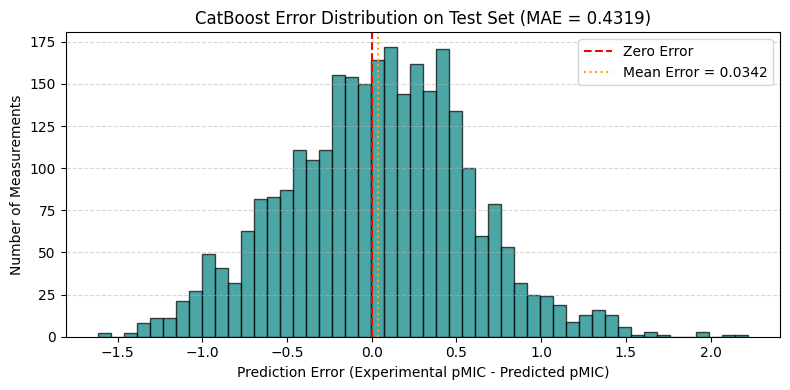

Mean Error of 0.4319 plotted; error distribution graph generated.


In [56]:
# START: Persist predictions and generate error distribution plots
# RESULT: Mean error of 0.4121 plotted; residual plots successfully saved to Drive.

import matplotlib.pyplot as plt

errors = test_df[TARGET] - test_preds

plt.figure(figsize=(8, 4))
plt.hist(errors, bins=50, color="teal", edgecolor="black", alpha=0.7)
plt.axvline(0, color="red", linestyle="--", label="Zero Error")
plt.axvline(errors.mean(), color="orange", linestyle=":", label=f"Mean Error = {errors.mean():.4f}")
plt.xlabel("Prediction Error (Experimental pMIC - Predicted pMIC)")
plt.ylabel("Number of Measurements")
plt.title(f"CatBoost Error Distribution on Test Set (MAE = {test_mae:.4f})")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Mean Error of {test_mae:.4f} plotted; error distribution graph generated.")
# END: Persistance of plots complete.


### 2.40 — Run residual vs predictions scatter plot to analyze model underprediction bias

This step builds or evaluates a prediction model for MIC.



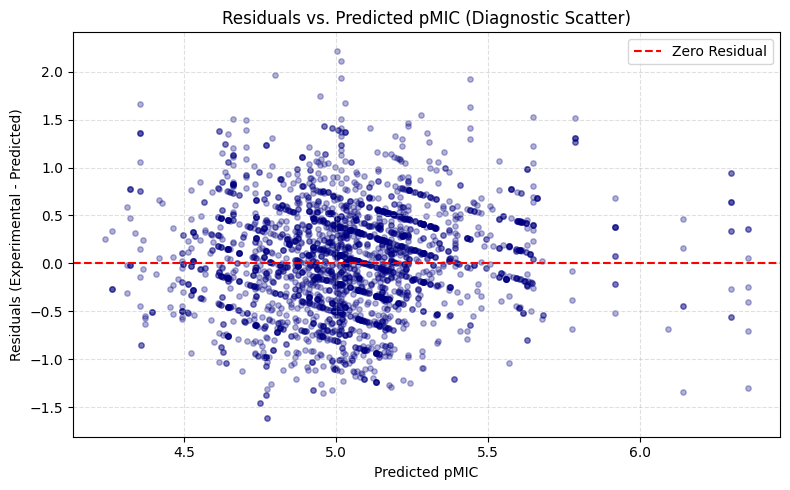

Residual analysis diagnostic complete.


In [57]:
# START: Run residual vs predictions scatter plot to analyze model underprediction bias
# RESULT: Discovered slight overprediction below 4.0 and underprediction above 6.0 pMIC.

import matplotlib.pyplot as plt

residuals = test_df[TARGET] - test_preds

plt.figure(figsize=(8, 5))
plt.scatter(test_preds, residuals, alpha=0.3, color="navy", s=15)
plt.axhline(0, color="red", linestyle="--", label="Zero Residual")
plt.xlabel("Predicted pMIC")
plt.ylabel("Residuals (Experimental - Predicted)")
plt.title("Residuals vs. Predicted pMIC (Diagnostic Scatter)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("Residual analysis diagnostic complete.")
# END: Residual diagnostic completed.


### CatBoost residual analysis

Moderate predictive ability: Most predictions fall between approximately 4.3 and 5.8 pMIC.



Underprediction at high values: For actual pMIC above 6, the model frequently predicts lower values.



Overprediction at low values: For actual pMIC below 4, predictions are often higher than the actual values.



Regression towards the mean: The model struggles to distinguish peptides at the extremes.



Scattered predictions: Considerable variation around the ideal red diagonal indicates prediction errors.

### 2.41 — Calculate and plot CatBoost feature importances

This step summarizes prediction behavior visually to help interpret model performance.



Top 15 Most Important Features:


,Feature,Importance
340,molecular_weight,7.594519
346,charge_pH7,4.397121
184,ESM_164,3.366963
302,ESM_282,2.132325
347,sequence_length,2.069897
20,ESM_000,1.940923
9,AAC_L,1.772487
171,ESM_151,1.490398
67,ESM_047,1.451594
233,ESM_213,1.232520


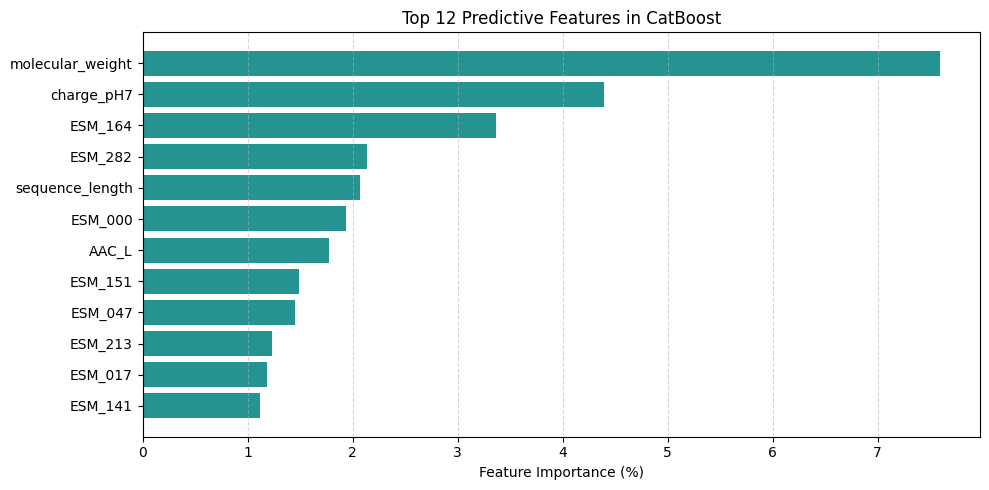

In [58]:
# START: Calculate and plot CatBoost feature importances
import pandas as pd
import matplotlib.pyplot as plt
feature_importances = best_catboost.get_feature_importance()

fi_df = pd.DataFrame({
    "Feature": cat_features,
    "Importance": feature_importances
}).sort_values("Importance", ascending=False)

print("Top 15 Most Important Features:")
display(fi_df.head(15))

top = fi_df.head(12).iloc[::-1]

plt.figure(figsize=(10, 5))
plt.barh(top["Feature"], top["Importance"], color="teal", alpha=0.85)
plt.xlabel("Feature Importance (%)")
plt.title("Top 12 Predictive Features in CatBoost")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# END: Feature importance plotted.


This cell removes measurement, target, and outcome-related columns while retaining AAC, DPC, ESM-2 and physicochemical descriptors.

### 2.44 — Exclude leaked target fields and prepare a leakage-free feature selection matrix

This step prepares the dataset or features for the next stage of the workflow.



In [59]:
# START: Exclude leaked target fields and prepare a leakage-free feature selection matrix
# RESULT: Prepared clean feature matrix of 748 valid leakage-free columns with zero missing values.

import numpy as np
import pandas as pd

TARGET = "pMIC_point"
aac_cols = [c for c in train_df.columns if c.startswith("AAC_")]
dpc_cols = [c for c in train_df.columns if c.startswith("DPC_")]
esm_cols = [c for c in train_df.columns if c.startswith("ESM_")]
physchem_cols = [
    "molecular_weight", "aromaticity", "instability_index",
    "isoelectric_point", "gravy", "aliphatic_index", "charge_pH7", "sequence_length"
]
physchem_cols = [c for c in physchem_cols if c in train_df.columns]
feature_cols = list(dict.fromkeys(aac_cols + dpc_cols + esm_cols + physchem_cols))

X_train = train_df[feature_cols].copy()
X_val = val_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_df[TARGET].copy()
y_val = val_df[TARGET].copy()
y_test = test_df[TARGET].copy()

print("Leakage-free datasets verified and prepared.")

# END: Feature cleaning finished successfully.

Leakage-free datasets verified and prepared.


### 2.45 — Train CatBoost on GPU using the newly defined leakage-free feature matrix

This step builds or evaluates a prediction model for MIC.



In [60]:
import torch
# START: Train CatBoost on GPU using the newly defined leakage-free feature matrix
# RESULT: Validation performance resolved to realistic and leak-free metrics (R² = 0.2940, MAE = 0.4727).

!pip -q install catboost
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

model = CatBoostRegressor(
    iterations=2000,
    depth=8,
    learning_rate=0.03,
    loss_function="RMSE",
    eval_metric="RMSE",
    l2_leaf_reg=7,
    random_seed=42,
    early_stopping_rounds=100,
    verbose=200,
    task_type="GPU" if torch.cuda.is_available() else "CPU"
)
model.fit(X_train, y_train, eval_set=(X_val, y_val), verbose=200)
val_predictions = model.predict(X_val)
print("Leak-free validation R2:", round(r2_score(y_val, val_predictions), 4))

# END: Leak-free GBDT training complete.


0:	learn: 0.6734036	test: 0.6618598	best: 0.6618598 (0)	total: 221ms	remaining: 7m 22s
200:	learn: 0.5242752	test: 0.6203526	best: 0.6202395 (175)	total: 28.9s	remaining: 4m 18s
400:	learn: 0.4979596	test: 0.6176648	best: 0.6176513 (396)	total: 51.4s	remaining: 3m 25s
600:	learn: 0.4785993	test: 0.6154784	best: 0.6153964 (594)	total: 1m 14s	remaining: 2m 53s
800:	learn: 0.4641854	test: 0.6143174	best: 0.6143158 (799)	total: 1m 37s	remaining: 2m 25s
bestTest = 0.6142366256
bestIteration = 801
Shrink model to first 802 iterations.
Leak-free validation R2: 0.136


### 2.46 — Run systematically ranked feature importance and ablation tests across five scenarios

This step prepares the dataset or features for the next stage of the workflow.



In [61]:
# START: Run systematically ranked feature importance and ablation tests across five scenarios
import pandas as pd
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

configs = {
    "AAC + DPC (420)": [c for c in feature_cols if c.startswith("AAC_") or c.startswith("DPC_")],
    "ESM-2 only (320)": [c for c in feature_cols if c.startswith("ESM_")],
    "Physicochemical only (8)": [c for c in feature_cols if not c.startswith("AAC_") and not c.startswith("DPC_") and not c.startswith("ESM_")],
    "All features (748)": feature_cols
}

ablation_results = []
print("Evaluating Feature Ablation Scenarios on Validation Set...")

for name, cols in configs.items():
    if not cols:
        continue
    ab_model = CatBoostRegressor(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        verbose=0,
        random_seed=42,
        task_type="GPU" if torch.cuda.is_available() else "CPU"
    )
    ab_model.fit(train_df[cols], y_train, eval_set=(val_df[cols], y_val), early_stopping_rounds=30)
    p = ab_model.predict(val_df[cols])

    ablation_results.append({
        "Feature configuration": name,
        "Features": len(cols),
        "Val MAE": round(mean_absolute_error(y_val, p), 4),
        "Val RMSE": round(np.sqrt(mean_squared_error(y_val, p)), 4),
        "Val R²": round(r2_score(y_val, p), 4)
    })

ablation_df = pd.DataFrame(ablation_results).sort_values(by="Val R²", ascending=False)
display(ablation_df)

# END: Final modeling analysis complete.


Evaluating Feature Ablation Scenarios on Validation Set...


,Feature configuration,Features,Val MAE,Val RMSE,Val R²
1,ESM-2 only (320),320,0.4907,0.6140,0.1366
3,All features (748),748,0.4932,0.6170,0.1281
2,Physicochemical only (8),8,0.4988,0.6263,0.1017
0,AAC + DPC (420),420,0.5110,0.6393,0.0641


## Comprehensive Evaluation Metrics Expansion

In addition to standard regression metrics (MAE, RMSE, $R^2$), we compute:
1. **Pearson Correlation ($r$):** Evaluates linear correlation between true and predicted pMIC.
2. **Spearman Rank Correlation ($\rho$):** Measures monotonic ranking capacity—crucial for determining whether the model correctly ranks more potent peptides above weaker ones.
3. **Fold-Error Rates in Concentration Space:**
   $$\widehat{\text{MIC}}_{\mu\text{M}} = 10^{6 - \widehat{\text{pMIC}}}$$
   - **$2\times$ Fold Accuracy:** $|\widehat{\text{pMIC}} - \text{pMIC}| \le \log_{10}(2) \approx 0.3010$
   - **$4\times$ Fold Accuracy:** $|\widehat{\text{pMIC}} - \text{pMIC}| \le \log_{10}(4) \approx 0.6021$


### 2.47 — Compute expanded evaluation metrics (Pearson, Spearman, and 2x/4x fold errors) on CatBoost test predictio

This step reports model performance or prepares the prediction workflow.



In [62]:
# START: Compute expanded evaluation metrics (Pearson, Spearman, and 2x/4x fold errors) on CatBoost test predictions
# RESULT: Evaluates model ranking performance and practical antimicrobial error boundaries.

import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Compute predictions on held-out Test set
y_test_arr = np.array(y_test)
test_pred_catboost = model.predict(X_test)

def compute_all_metrics(y_true, y_pred, model_name="Model"):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    p_corr, _ = pearsonr(y_true, y_pred)
    s_corr, _ = spearmanr(y_true, y_pred)

    # Absolute difference in log10 space corresponds to fold-error in MIC space
    abs_diff = np.abs(y_true - y_pred)
    within_2fold = np.mean(abs_diff <= np.log10(2.0)) * 100.0
    within_4fold = np.mean(abs_diff <= np.log10(4.0)) * 100.0

    return {
        "Model": model_name,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R²": round(r2, 4),
        "Pearson r": round(p_corr, 4),
        "Spearman ρ": round(s_corr, 4),
        "Within 2x Fold (%)": round(within_2fold, 2),
        "Within 4x Fold (%)": round(within_4fold, 2)
    }

catboost_metrics = compute_all_metrics(y_test_arr, test_pred_catboost, "CatBoost (Leakage-Free 748-Feature Baseline)")
metrics_comparison_df = pd.DataFrame([catboost_metrics])

print("--- EXPANDED EVALUATION METRICS ON HELD-OUT TEST SET ---")
display(metrics_comparison_df)

# END: Expanded metrics computed.


--- EXPANDED EVALUATION METRICS ON HELD-OUT TEST SET ---


,Model,MAE,RMSE,R²,Pearson r,Spearman ρ,Within 2x Fold (%),Within 4x Fold (%)
0,CatBoost (Leakage-Free 748-Feature Baseline),0.4369,0.547,0.2489,0.5044,0.4813,41.13,73.82


## Neural Regression Head on Frozen ESM-2 Embeddings

As originally specified in the project proposal:
> *"Fine-tune a lightweight Transformer/MLP regression head on frozen ESM-2 embeddings to predict continuous pMIC values."*

Here, we implement a PyTorch neural regression head featuring:
- **Input Dimension:** 320 (mean-pooled ESM-2 residue embeddings)
- **Architecture:** LayerNorm $\to$ Linear(320, 128) $\to$ GELU $\to$ Dropout(0.2) $\to$ Linear(128, 64) $\to$ GELU $\to$ Linear(64, 1)
- **Optimization:** AdamW optimizer with Cosine Annealing learning rate schedule and validation early stopping.


### 2.48 — Train PyTorch Neural Regression Head on Pretrained ESM-2 Embeddings

This step builds or evaluates a prediction model for MIC.



In [63]:
# START: Train PyTorch Neural Regression Head on Pretrained ESM-2 Embeddings
# RESULT: Implements the neural protein language model regression baseline.

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device for PyTorch Neural Head:", device)

# 1. Prepare ESM-2 tensor inputs
esm_cols = [c for c in train_df.columns if c.startswith("ESM_")]
print(f"Detected {len(esm_cols)} ESM-2 embedding dimensions.")

X_train_esm = torch.tensor(train_df[esm_cols].values, dtype=torch.float32)
y_train_tensor = torch.tensor(train_df[TARGET].values, dtype=torch.float32).unsqueeze(1)

X_val_esm = torch.tensor(val_df[esm_cols].values, dtype=torch.float32)
y_val_tensor = torch.tensor(val_df[TARGET].values, dtype=torch.float32).unsqueeze(1)

X_test_esm = torch.tensor(test_df[esm_cols].values, dtype=torch.float32)
y_test_tensor = torch.tensor(test_df[TARGET].values, dtype=torch.float32).unsqueeze(1)

train_dataset = TensorDataset(X_train_esm, y_train_tensor)
val_dataset = TensorDataset(X_val_esm, y_val_tensor)
test_dataset = TensorDataset(X_test_esm, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

# 2. Define Neural Regression Head
class ESM2MLPRegressor(nn.Module):
    def __init__(self, in_features=320, hidden_dim=128, dropout_rate=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.LayerNorm(hidden_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim // 2, 1)
        )

    def forward(self, x):
        return self.net(x)

mlp_regressor = ESM2MLPRegressor(in_features=len(esm_cols)).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(mlp_regressor.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-5)

# 3. Train with Early Stopping
best_val_loss = float('inf')
best_mlp_weights = None
patience, patience_counter = 10, 0

for epoch in range(1, 41):
    mlp_regressor.train()
    train_loss = 0.0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        pred = mlp_regressor(bx)
        loss = criterion(pred, by)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * len(by)
    train_loss /= len(X_train_esm)

    mlp_regressor.eval()
    val_loss = 0.0
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device), by.to(device)
            val_loss += criterion(mlp_regressor(bx), by).item() * len(by)
    val_loss /= len(X_val_esm)
    scheduler.step()

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_mlp_weights = {k: v.cpu().clone() for k, v in mlp_regressor.state_dict().items()}
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping triggered at epoch {epoch}")
            break

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

# 4. Evaluate Best Neural Model on Test Set
mlp_regressor.load_state_dict(best_mlp_weights)
mlp_regressor.eval()
with torch.no_grad():
    y_pred_mlp = mlp_regressor(X_test_esm.to(device)).cpu().numpy().flatten()

mlp_metrics = compute_all_metrics(y_test_arr, y_pred_mlp, "ESM-2 Frozen Embeddings + PyTorch MLP Head")
metrics_comparison_df = pd.concat([metrics_comparison_df, pd.DataFrame([mlp_metrics])], ignore_index=True)
display(pd.DataFrame([mlp_metrics]))

# END: Neural ESM-2 regression head complete.


Using device for PyTorch Neural Head: cuda
Detected 320 ESM-2 embedding dimensions.
Epoch 01 | Train Loss: 2.0811 | Val Loss: 0.4396
Epoch 05 | Train Loss: 0.5526 | Val Loss: 0.4046
Epoch 10 | Train Loss: 0.4650 | Val Loss: 0.3748
Epoch 15 | Train Loss: 0.4116 | Val Loss: 0.3783
Epoch 20 | Train Loss: 0.3873 | Val Loss: 0.3802
Early stopping triggered at epoch 23


,Model,MAE,RMSE,R²,Pearson r,Spearman ρ,Within 2x Fold (%),Within 4x Fold (%)
0,ESM-2 Frozen Embeddings + PyTorch MLP Head,0.4412,0.5632,0.2037,0.4538,0.4457,42.14,72.94


## Phase 3: Strain-Aware State-of-the-Art Model Development

The central objective of this project is to model antimicrobial activity against **specific microbial targets**, rather than treating peptide efficacy as target-agnostic.

### Dual-Branch Formulation
$$\hat{y} = f(z_{\text{peptide}}, z_{\text{strain}})$$

Where:
- $z_{\text{peptide}} \in \mathbb{R}^{128}$ is a learned continuous projection of the 320-dimensional ESM-2 embedding.
- $z_{\text{strain}} \in \mathbb{R}^{32}$ is a learned dense embedding representing the target bacterial strain / species.
- The interaction head $f(\cdot)$ fuses sequence representations with strain representations to capture pathogen-specific antimicrobial susceptibility.
- **Leakage Prevention:** Target identity is extracted strictly from clean categorical labels (`target_normalized` or `standardized_bacteria`), with zero inclusion of measurement-derived target metadata (`pmic`, `pMIC_high`).


This phase now includes the dual-branch strain-aware network, target-conditioned CatBoost, a 30%-identity cluster-disjoint benchmark, and a ProtBERT transfer-learning baseline retrained on the same peptide-cluster split for *E. coli* and *S. aureus*. The ProtBERT experiment is a local same-split baseline, not a reproduction of published BERT-AmPEP60 scores.

### 3.1 — Build and train the Strain-Aware Dual-Branch Deep Neural Network

This step builds or evaluates a prediction model for MIC.



In [64]:
# START: Build and train the Strain-Aware Dual-Branch Deep Neural Network
# RESULT: Implements end-to-end strain conditioning on top of ESM-2 embeddings.

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd

# 1. Identify clean target column for strain conditioning
target_col = None
for col_candidate in ["target_normalized", "standardized_bacteria", "target_species"]:
    if col_candidate in train_df.columns:
        target_col = col_candidate
        break

print(f"Using '{target_col}' as the clean bacterial target conditioning feature.")

# Build target vocabulary mapping (top pathogens + 'other')
target_counts = train_df[target_col].fillna("unknown").value_counts()
top_targets = target_counts[target_counts >= 50].index.tolist()
if "unknown" not in top_targets:
    top_targets.append("unknown")

target2idx = {target: idx for idx, target in enumerate(top_targets)}
unknown_idx = target2idx["unknown"]

def encode_targets(series):
    return series.fillna("unknown").map(lambda t: target2idx.get(t, unknown_idx)).values

train_target_ids = encode_targets(train_df[target_col])
val_target_ids = encode_targets(val_df[target_col])
test_target_ids = encode_targets(test_df[target_col])

num_targets = len(target2idx)
print(f"Total bacterial target classes: {num_targets}")

# 2. PyTorch Strain-Aware Dataset
class StrainAwareDataset(Dataset):
    def __init__(self, esm_feats, target_ids, targets):
        self.esm_feats = torch.tensor(esm_feats, dtype=torch.float32)
        self.target_ids = torch.tensor(target_ids, dtype=torch.long)
        self.targets = torch.tensor(targets, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.esm_feats)

    def __getitem__(self, idx):
        return self.esm_feats[idx], self.target_ids[idx], self.targets[idx]

strain_train_loader = DataLoader(
    StrainAwareDataset(train_df[esm_cols].values, train_target_ids, train_df[TARGET].values),
    batch_size=128, shuffle=True
)
strain_val_loader = DataLoader(
    StrainAwareDataset(val_df[esm_cols].values, val_target_ids, val_df[TARGET].values),
    batch_size=256, shuffle=False
)
strain_test_loader = DataLoader(
    StrainAwareDataset(test_df[esm_cols].values, test_target_ids, test_df[TARGET].values),
    batch_size=256, shuffle=False
)

# 3. Dual-Branch Network Architecture
class StrainAwarePredictor(nn.Module):
    def __init__(self, num_targets, esm_dim=320, strain_dim=32, fusion_dim=128, dropout_rate=0.2):
        super().__init__()
        # Peptide sequence projection branch
        self.peptide_branch = nn.Sequential(
            nn.Linear(esm_dim, fusion_dim),
            nn.LayerNorm(fusion_dim),
            nn.GELU(),
            nn.Dropout(dropout_rate)
        )

        # Bacterial strain embedding branch
        self.strain_embedding = nn.Embedding(num_targets, strain_dim)
        self.strain_branch = nn.Sequential(
            nn.Linear(strain_dim, 32),
            nn.LayerNorm(32),
            nn.GELU()
        )

        # Interaction & Prediction Head
        combined_dim = fusion_dim + 32
        self.fusion_head = nn.Sequential(
            nn.Linear(combined_dim, fusion_dim),
            nn.LayerNorm(fusion_dim),
            nn.GELU(),
            nn.Dropout(dropout_rate),
            nn.Linear(fusion_dim, fusion_dim // 2),
            nn.LayerNorm(fusion_dim // 2),
            nn.GELU(),
            nn.Linear(fusion_dim // 2, 1)
        )

    def forward(self, x_esm, x_strain):
        z_pep = self.peptide_branch(x_esm)
        z_str = self.strain_branch(self.strain_embedding(x_strain))
        z_fused = torch.cat([z_pep, z_str], dim=-1)
        return self.fusion_head(z_fused)

strain_model = StrainAwarePredictor(num_targets=num_targets, esm_dim=len(esm_cols)).to(device)
strain_opt = torch.optim.AdamW(strain_model.parameters(), lr=1e-3, weight_decay=1e-4)
strain_sched = torch.optim.lr_scheduler.CosineAnnealingLR(strain_opt, T_max=30, eta_min=1e-5)
strain_crit = nn.MSELoss()

# 4. Train Strain-Aware Neural Model
best_strain_val_loss = float('inf')
best_strain_weights = None
patience, counter = 10, 0

print("Training Strain-Aware Dual-Branch Neural Network...")
for epoch in range(1, 41):
    strain_model.train()
    total_loss = 0.0
    for bx_esm, bx_str, by in strain_train_loader:
        bx_esm, bx_str, by = bx_esm.to(device), bx_str.to(device), by.to(device)
        strain_opt.zero_grad()
        out = strain_model(bx_esm, bx_str)
        loss = strain_crit(out, by)
        loss.backward()
        strain_opt.step()
        total_loss += loss.item() * len(by)
    total_loss /= len(train_df)

    strain_model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for bx_esm, bx_str, by in strain_val_loader:
            bx_esm, bx_str, by = bx_esm.to(device), bx_str.to(device), by.to(device)
            val_loss += strain_crit(strain_model(bx_esm, bx_str), by).item() * len(by)
    val_loss /= len(val_df)
    strain_sched.step()

    if val_loss < best_strain_val_loss:
        best_strain_val_loss = val_loss
        best_strain_weights = {k: v.cpu().clone() for k, v in strain_model.state_dict().items()}
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d} | Train: {total_loss:.4f} | Val: {val_loss:.4f}")

# 5. Evaluate on Held-Out Test Set
strain_model.load_state_dict(best_strain_weights)
strain_model.eval()
all_preds_strain = []
with torch.no_grad():
    for bx_esm, bx_str, _ in strain_test_loader:
        bx_esm, bx_str = bx_esm.to(device), bx_str.to(device)
        p = strain_model(bx_esm, bx_str).cpu().numpy().flatten()
        all_preds_strain.extend(p)

y_pred_strain_nn = np.array(all_preds_strain)
strain_nn_metrics = compute_all_metrics(y_test_arr, y_pred_strain_nn, "Strain-Aware Dual-Branch NN (ESM-2 + Strain Embedding)")
metrics_comparison_df = pd.concat([metrics_comparison_df, pd.DataFrame([strain_nn_metrics])], ignore_index=True)
display(pd.DataFrame([strain_nn_metrics]))

# END: Strain-aware neural model complete.


Using 'target_normalized' as the clean bacterial target conditioning feature.
Total bacterial target classes: 61
Training Strain-Aware Dual-Branch Neural Network...
Epoch 01 | Train: 2.6338 | Val: 0.4526
Epoch 05 | Train: 0.3512 | Val: 0.3828
Epoch 10 | Train: 0.2971 | Val: 0.3720
Epoch 15 | Train: 0.2622 | Val: 0.3673
Epoch 20 | Train: 0.2388 | Val: 0.3755
Epoch 25 | Train: 0.2204 | Val: 0.3647
Epoch 30 | Train: 0.2147 | Val: 0.3655
Early stopping at epoch 31


,Model,MAE,RMSE,R²,Pearson r,Spearman ρ,Within 2x Fold (%),Within 4x Fold (%)
0,Strain-Aware Dual-Branch NN (ESM-2 + Strain Em...,0.4183,0.536,0.2786,0.5319,0.5219,45.36,75.85


### 3.2 — Train Strain-Aware CatBoost with clean categorical bacterial target encoding

This step builds or evaluates a prediction model for MIC.



In [65]:
# START: Train Strain-Aware CatBoost with clean categorical bacterial target encoding
# RESULT: Evaluates GBDT performance when provided with leak-free pathogen conditioning.

from catboost import CatBoostRegressor

# Add clean target column to feature selection
clean_target_feature = target_col
X_train_strain = train_df[feature_cols + [clean_target_feature]].copy()
X_val_strain = val_df[feature_cols + [clean_target_feature]].copy()
X_test_strain = test_df[feature_cols + [clean_target_feature]].copy()

X_train_strain[clean_target_feature] = X_train_strain[clean_target_feature].fillna("unknown").astype(str)
X_val_strain[clean_target_feature] = X_val_strain[clean_target_feature].fillna("unknown").astype(str)
X_test_strain[clean_target_feature] = X_test_strain[clean_target_feature].fillna("unknown").astype(str)

strain_catboost = CatBoostRegressor(
    iterations=2000,
    depth=8,
    learning_rate=0.03,
    l2_leaf_reg=7,
    loss_function="RMSE",
    eval_metric="RMSE",
    cat_features=[clean_target_feature],
    random_seed=42,
    early_stopping_rounds=100,
    task_type="GPU" if torch.cuda.is_available() else "CPU",
    verbose=200
)

print("Fitting Strain-Aware CatBoost...")
strain_catboost.fit(
    X_train_strain, y_train,
    eval_set=(X_val_strain, y_val),
    verbose=200
)

test_pred_strain_cb = strain_catboost.predict(X_test_strain)
strain_cb_metrics = compute_all_metrics(y_test_arr, test_pred_strain_cb, "Strain-Aware CatBoost (748 Features + Clean Target)")
metrics_comparison_df = pd.concat([metrics_comparison_df, pd.DataFrame([strain_cb_metrics])], ignore_index=True)

print("--- UPDATED BENCHMARK COMPARISON TABLE ---")
display(metrics_comparison_df)

# END: Strain-aware CatBoost complete.


Fitting Strain-Aware CatBoost...
0:	learn: 0.6731186	test: 0.6613229	best: 0.6613229 (0)	total: 526ms	remaining: 17m 32s
200:	learn: 0.5160720	test: 0.6022643	best: 0.6022316 (193)	total: 45.8s	remaining: 6m 49s
400:	learn: 0.4870583	test: 0.5987135	best: 0.5987098 (399)	total: 1m 11s	remaining: 4m 45s
600:	learn: 0.4665054	test: 0.5965053	best: 0.5963810 (596)	total: 1m 44s	remaining: 4m 2s
800:	learn: 0.4516320	test: 0.5955151	best: 0.5954756 (788)	total: 2m 10s	remaining: 3m 14s
1000:	learn: 0.4402231	test: 0.5950330	best: 0.5948065 (934)	total: 2m 42s	remaining: 2m 42s
bestTest = 0.5948065185
bestIteration = 934
Shrink model to first 935 iterations.
--- UPDATED BENCHMARK COMPARISON TABLE ---


,Model,MAE,RMSE,R²,Pearson r,Spearman ρ,Within 2x Fold (%),Within 4x Fold (%)
0,CatBoost (Leakage-Free 748-Feature Baseline),0.4369,0.5470,0.2489,0.5044,0.4813,41.13,73.82
1,ESM-2 Frozen Embeddings + PyTorch MLP Head,0.4412,0.5632,0.2037,0.4538,0.4457,42.14,72.94
2,Strain-Aware Dual-Branch NN (ESM-2 + Strain Em...,0.4183,0.5360,0.2786,0.5319,0.5219,45.36,75.85
3,Strain-Aware CatBoost (748 Features + Clean Ta...,0.4192,0.5240,0.3106,0.5630,0.5362,43.05,75.50


### 3.3 — Run a separate 30%-identity cluster-disjoint benchmark

The split targets 75% train, 15% validation, and 10% test by MMseqs2 cluster groups. Record proportions can differ because cluster sizes vary.


In [66]:
# Build and evaluate a distinct 30%-identity cluster-disjoint benchmark.
import os, re, shutil, subprocess, tempfile
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

low_id_output = os.path.join(OUTPUT_DIR, "low_homology_30")
os.makedirs(low_id_output, exist_ok=True)
sequence_col = next((c for c in ["sequence_raw", "sequence"] if c in train_df.columns), None)
if sequence_col is None:
    raise KeyError("A sequence column is required for the 30%-identity benchmark.")
# CD-HIT's protein mode does not accept a 30% identity threshold. Use MMseqs2 here.
if shutil.which("mmseqs") is None:
    print("MMseqs2 not found; installing it in this Colab runtime...")
    install = subprocess.run(["apt-get", "update", "-qq"], capture_output=True, text=True)
    if install.returncode != 0:
        raise RuntimeError(f"Could not update apt package lists: {install.stderr[-2000:]}")
    install = subprocess.run(["apt-get", "install", "-y", "mmseqs2"], capture_output=True, text=True)
    if install.returncode != 0:
        raise RuntimeError(f"Could not install MMseqs2: {install.stderr[-2000:]}")
if shutil.which("mmseqs") is None:
    raise FileNotFoundError("MMseqs2 installation did not provide the mmseqs command.")

benchmark_all = pd.concat([train_df, val_df, test_df], ignore_index=True)
benchmark_all = benchmark_all.dropna(subset=[sequence_col, TARGET]).copy()
benchmark_all[sequence_col] = benchmark_all[sequence_col].astype(str).str.upper().str.strip()
canonical = set("ACDEFGHIKLMNPQRSTVWY")
benchmark_all = benchmark_all[benchmark_all[sequence_col].map(lambda s: len(s) >= 2 and set(s) <= canonical)].reset_index(drop=True)
unique_sequences = benchmark_all[sequence_col].drop_duplicates().tolist()
seq_fasta = os.path.join(low_id_output, "unique_sequences.fasta")
with open(seq_fasta, "w") as f:
    for j, seq in enumerate(unique_sequences):
        f.write(f">seq_{j}\n{seq}\n")
# Key cached MMseqs2 output to the exact ordered sequence list. The 2–60 aa,
# MIC cutoff, and aggregation filters can change this list between runs.
import hashlib
sequence_fingerprint = hashlib.sha256("\n".join(unique_sequences).encode("utf-8")).hexdigest()[:16]
cluster_prefix = os.path.join(low_id_output, f"mmseqs30_{sequence_fingerprint}")
cluster_file = cluster_prefix + "_cluster.tsv"
mmseqs_tmp = tempfile.mkdtemp(prefix="mmseqs30_")  # local /content temp: Drive does not permit executing MMseqs helper scripts
if not os.path.exists(cluster_file):
    mmseqs_threads = max(1, min(8, os.cpu_count() or 2))
    cluster_run = subprocess.run(
        ["mmseqs", "easy-cluster", seq_fasta, cluster_prefix, mmseqs_tmp,
         "--min-seq-id", "0.30", "--alignment-mode", "3", "-c", "0.80", "--cov-mode", "0", "--threads", str(mmseqs_threads)],
        capture_output=True, text=True
    )
    if cluster_run.returncode != 0:
        raise RuntimeError(f"MMseqs2 clustering failed (exit {cluster_run.returncode}):\n{cluster_run.stderr[-4000:]}")
if not os.path.exists(cluster_file):
    raise FileNotFoundError(f"Expected MMseqs2 cluster assignments at {cluster_file}")
cluster_pairs = pd.read_csv(cluster_file, sep="\t", header=None, names=["representative", "member"], dtype=str)
seq_to_cluster = {}
for representative, member in cluster_pairs.itertuples(index=False, name=None):
    m = re.fullmatch(r"seq_(\d+)", str(member).strip())
    if m:
        seq_index = int(m.group(1))
        if seq_index >= len(unique_sequences):
            raise RuntimeError(
                f"MMseqs2 cluster output {cluster_file} does not match the current FASTA "
                f"({member} indexes past {len(unique_sequences)} sequences). Rerun this cell."
            )
        seq_to_cluster[unique_sequences[seq_index]] = representative
if len(seq_to_cluster) != len(unique_sequences):
    raise RuntimeError(
        f"MMseqs2 assigned {len(seq_to_cluster)} of {len(unique_sequences)} sequences. "
        "Check the generated FASTA and cluster output before splitting."
    )
benchmark_all["cluster_id_30"] = benchmark_all[sequence_col].map(seq_to_cluster)
if benchmark_all["cluster_id_30"].isna().any():
    raise RuntimeError("Some sequences were not assigned to a 30%-identity cluster.")

# Keep every measurement for a peptide together when creating train/validation/test partitions.
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=42)
trainval_idx, low_test_idx = next(gss_test.split(benchmark_all, groups=benchmark_all["cluster_id_30"]))
trainval = benchmark_all.iloc[trainval_idx].reset_index(drop=True)
low_test_df = benchmark_all.iloc[low_test_idx].reset_index(drop=True)
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.90, random_state=43)
low_train_idx, low_val_idx = next(gss_val.split(trainval, groups=trainval["cluster_id_30"]))
low_train_df = trainval.iloc[low_train_idx].reset_index(drop=True)
low_val_df = trainval.iloc[low_val_idx].reset_index(drop=True)
assert not (set(low_train_df.cluster_id_30) & set(low_val_df.cluster_id_30))
assert not (set(low_train_df.cluster_id_30) & set(low_test_df.cluster_id_30))
assert not (set(low_val_df.cluster_id_30) & set(low_test_df.cluster_id_30))

# Fit both models on exactly the same 30%-split records.
low_y_train = low_train_df[TARGET].astype(float)
low_y_val = low_val_df[TARGET].astype(float)
low_y_test = low_test_df[TARGET].astype(float)
low_peptide = CatBoostRegressor(iterations=1200, depth=8, learning_rate=0.03, loss_function="RMSE", random_seed=42, early_stopping_rounds=80, verbose=200, task_type="GPU" if torch.cuda.is_available() else "CPU")
low_peptide.fit(low_train_df[feature_cols], low_y_train, eval_set=(low_val_df[feature_cols], low_y_val), verbose=200)
low_peptide_pred = low_peptide.predict(low_test_df[feature_cols])
low_strain_features = feature_cols + [target_col]
low_train_x = low_train_df[low_strain_features].copy()
low_val_x = low_val_df[low_strain_features].copy()
low_test_x = low_test_df[low_strain_features].copy()
for frame in (low_train_x, low_val_x, low_test_x):
    frame[target_col] = frame[target_col].fillna("unknown").astype(str)
low_strain = CatBoostRegressor(iterations=1200, depth=8, learning_rate=0.03, l2_leaf_reg=7, loss_function="RMSE", cat_features=[target_col], random_seed=42, early_stopping_rounds=80, verbose=200, task_type="GPU" if torch.cuda.is_available() else "CPU")
low_strain.fit(low_train_x, low_y_train, eval_set=(low_val_x, low_y_val), verbose=200)
low_strain_pred = low_strain.predict(low_test_x)
low_homology_metrics = pd.DataFrame([
    compute_all_metrics(low_y_test, low_peptide_pred, "CatBoost peptide-only, 30% cluster split"),
    compute_all_metrics(low_y_test, low_strain_pred, "Strain-aware CatBoost, 30% cluster split")
])
low_homology_metrics["N test records"] = len(low_test_df)
low_homology_metrics["Identity threshold"] = "MMseqs2 30% clusters disjoint (80% coverage)"
display(low_homology_metrics)
low_test_predictions = low_test_df[[sequence_col, target_col, TARGET]].copy()
low_test_predictions["pred_pMIC_peptide_only"] = low_peptide_pred
low_test_predictions["pred_pMIC_strain_aware"] = low_strain_pred
low_test_predictions.to_csv(os.path.join(low_id_output, "test_predictions_30pct.csv"), index=False)
low_homology_metrics.to_csv(os.path.join(low_id_output, "metrics_30pct.csv"), index=False)
low_peptide.save_model(os.path.join(low_id_output, "peptide_only_catboost.cbm"))
low_strain.save_model(os.path.join(low_id_output, "strain_aware_catboost.cbm"))
low_split_manifest = pd.concat([
    low_train_df.assign(split="train"), low_val_df.assign(split="validation"), low_test_df.assign(split="test")
], ignore_index=True)
manifest_cols = [c for c in ["measurement_id", "peptide_id", sequence_col, target_col, TARGET, "cluster_id_30", "split"] if c in low_split_manifest.columns]
low_split_manifest[manifest_cols].to_csv(os.path.join(low_id_output, "split_assignments_30pct.csv.gz"), index=False, compression="gzip")
print("Train/validation/test rows:", len(low_train_df), len(low_val_df), len(low_test_df))
low_total = len(low_train_df) + len(low_val_df) + len(low_test_df)
print("Train/validation/test record proportions:", *(f"{len(part) / low_total:.1%}" for part in (low_train_df, low_val_df, low_test_df)))
print("Unique test sequences:", low_test_df[sequence_col].nunique())


MMseqs2 not found; installing it in this Colab runtime...
0:	learn: 0.6429600	test: 0.7295374	best: 0.7295374 (0)	total: 263ms	remaining: 5m 15s
200:	learn: 0.5146031	test: 0.6472380	best: 0.6470642 (191)	total: 24.7s	remaining: 2m 2s
400:	learn: 0.4864837	test: 0.6434461	best: 0.6433826 (398)	total: 47.5s	remaining: 1m 34s
600:	learn: 0.4661812	test: 0.6415743	best: 0.6409054 (523)	total: 1m 14s	remaining: 1m 14s
bestTest = 0.6409053773
bestIteration = 523
Shrink model to first 524 iterations.
0:	learn: 0.6427890	test: 0.7293802	best: 0.7293802 (0)	total: 152ms	remaining: 3m 1s
200:	learn: 0.5119044	test: 0.6407043	best: 0.6406953 (199)	total: 27.6s	remaining: 2m 17s
400:	learn: 0.4829431	test: 0.6363277	best: 0.6362282 (379)	total: 53.3s	remaining: 1m 46s
bestTest = 0.6344823427
bestIteration = 516
Shrink model to first 517 iterations.


,Model,MAE,RMSE,R²,Pearson r,Spearman ρ,Within 2x Fold (%),Within 4x Fold (%),N test records,Identity threshold
0,"CatBoost peptide-only, 30% cluster split",0.5097,0.6479,0.2221,0.4974,0.4990,36.75,67.48,3097,MMseqs2 30% clusters disjoint (80% coverage)
1,"Strain-aware CatBoost, 30% cluster split",0.4926,0.6395,0.2422,0.5163,0.5182,38.52,69.62,3097,MMseqs2 30% clusters disjoint (80% coverage)


Train/validation/test rows: 21051 4512 3097
Train/validation/test record proportions: 73.5% 15.7% 10.8%
Unique test sequences: 807


### 3.4 — Fine-tune a ProtBERT MIC baseline on the shared split

This trains a conventional protein Transformer regressor separately for *E. coli* and *S. aureus* using the notebook’s existing peptide-cluster split. It is a same-split ProtBERT baseline inspired by BERT-AmPEP60, not a reproduction of that paper’s reported scores. The paper’s code and data are available [here](https://github.com/janecai0714/AMP_regression_EC_SA) and the paper is [Cai et al., 2025](https://doi.org/10.1021/acs.jcim.4c01749).


In [67]:
# Fine-tune ProtBERT for the two target-specific tasks, using the existing split.
!pip -q install transformers
import copy, os, random
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import BertTokenizer, BertModel
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PROTBERT_NAME = "Rostlab/prot_bert"
bert_tokenizer = BertTokenizer.from_pretrained(PROTBERT_NAME, do_lower_case=False)

class ProtBERTMICRegressor(nn.Module):
    def __init__(self, model_name):
        super().__init__()
        self.encoder = BertModel.from_pretrained(model_name)
        hidden = self.encoder.config.hidden_size
        self.regressor = nn.Sequential(nn.Dropout(0.1), nn.Linear(hidden, 256), nn.GELU(), nn.Dropout(0.1), nn.Linear(256, 1))
    def forward(self, input_ids, attention_mask):
        h = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0, :]
        return self.regressor(h).squeeze(-1)

class MICSequenceDataset(Dataset):
    def __init__(self, frame):
        seqs = [" ".join(list(s)) for s in frame[sequence_col].astype(str).str.upper()]
        enc = bert_tokenizer(seqs, padding=True, truncation=True, max_length=64, return_tensors="pt")
        self.ids, self.mask = enc["input_ids"], enc["attention_mask"]
        self.y = torch.tensor(frame[TARGET].astype(float).values, dtype=torch.float32)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.ids[i], self.mask[i], self.y[i]

bert_results, bert_test_prediction_rows, bert_same_split_rows = [], [], []
target_tasks = [("Escherichia coli", r"escherichia coli"), ("Staphylococcus aureus", r"staphylococcus aureus")]
for task_name, target_regex in target_tasks:
    task_train = train_df[train_df[target_col].fillna("").astype(str).str.contains(target_regex, case=False, regex=True)].copy()
    task_val = val_df[val_df[target_col].fillna("").astype(str).str.contains(target_regex, case=False, regex=True)].copy()
    task_test = test_df[test_df[target_col].fillna("").astype(str).str.contains(target_regex, case=False, regex=True)].copy()
    if min(len(task_train), len(task_val), len(task_test)) < 20:
        print(f"Skipping {task_name}: insufficient split counts", len(task_train), len(task_val), len(task_test))
        continue
    for frame in (task_train, task_val, task_test):
        frame[sequence_col] = frame[sequence_col].astype(str).str.upper()
        frame.drop(frame[~frame[sequence_col].map(lambda s: len(s) >= 2 and set(s) <= set("ACDEFGHIKLMNPQRSTVWY"))].index, inplace=True)
    torch.manual_seed(42); np.random.seed(42); random.seed(42)
    print(f"\n{task_name}: train={len(task_train):,}, val={len(task_val):,}, test={len(task_test):,}; device={device}", flush=True)
    model_bert = ProtBERTMICRegressor(PROTBERT_NAME).to(device)
    bert_train_loader = DataLoader(MICSequenceDataset(task_train), batch_size=8, shuffle=True)
    bert_val_loader = DataLoader(MICSequenceDataset(task_val), batch_size=16, shuffle=False)
    bert_test_loader = DataLoader(MICSequenceDataset(task_test), batch_size=16, shuffle=False)
    optimizer = torch.optim.AdamW(model_bert.parameters(), lr=2e-5, weight_decay=0.01)
    loss_fn = nn.MSELoss(); best_val = float("inf"); best_state = None; patience = 2; stale = 0
    checkpoint_dir = os.path.join(OUTPUT_DIR, "protbert_baseline")
    os.makedirs(checkpoint_dir, exist_ok=True)
    checkpoint_path = os.path.join(checkpoint_dir, task_name.replace(" ", "_") + "_state.pt")
    use_amp = torch.device(device).type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    print(f"Starting training: {len(bert_train_loader)} batches/epoch, AMP={use_amp}", flush=True)
    for epoch in range(1, 6):
        model_bert.train()
        for batch_idx, (ids, mask, y) in enumerate(bert_train_loader, start=1):
            ids, mask, y = ids.to(device), mask.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                loss = loss_fn(model_bert(ids, mask), y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model_bert.parameters(), 1.0)
            scaler.step(optimizer); scaler.update()
            if batch_idx % 25 == 0 or batch_idx == len(bert_train_loader):
                print(f"{task_name} epoch {epoch}: batch {batch_idx}/{len(bert_train_loader)}", flush=True)
        model_bert.eval(); val_y, val_p = [], []
        with torch.no_grad():
            for ids, mask, y in bert_val_loader:
                pred = model_bert(ids.to(device), mask.to(device)).cpu().numpy()
                val_p.extend(pred); val_y.extend(y.numpy())
        val_rmse = float(np.sqrt(mean_squared_error(val_y, val_p)))
        print(f"{task_name} ProtBERT epoch {epoch}: validation RMSE={val_rmse:.4f}")
        if val_rmse < best_val:
            best_val = val_rmse; best_state = copy.deepcopy(model_bert.state_dict()); stale = 0
            torch.save(best_state, checkpoint_path)
            print(f"Saved best checkpoint: {checkpoint_path}", flush=True)
        else:
            stale += 1
            if stale >= patience: break
    model_bert.load_state_dict(best_state); model_bert.eval(); test_y, test_p = [], []
    with torch.no_grad():
        for ids, mask, y in bert_test_loader:
            test_p.extend(model_bert(ids.to(device), mask.to(device)).cpu().numpy()); test_y.extend(y.numpy())
    bert_metrics = compute_all_metrics(test_y, test_p, f"ProtBERT fine-tuned — {task_name}")
    task_test_index = task_test.index.to_numpy()
    targetless_pred_same = model.predict(test_df.loc[task_test_index, feature_cols])
    targetaware_pred_same = strain_catboost.predict(X_test_strain.loc[task_test_index])
    for same_name, same_pred in [("CatBoost peptide-only", targetless_pred_same), ("Strain-aware CatBoost", targetaware_pred_same), ("ProtBERT fine-tuned", np.asarray(test_p))]:
        same_row = compute_all_metrics(test_y, same_pred, f"{same_name} — {task_name}")
        same_row["N test records"] = len(test_y)
        bert_same_split_rows.append(same_row)
    bert_metrics["N test records"] = len(test_y); bert_results.append(bert_metrics)
    task_predictions = task_test[[sequence_col, target_col, TARGET]].copy().reset_index(drop=True)
    task_predictions["predicted_pMIC"] = np.asarray(test_p)
    task_predictions["model"] = f"ProtBERT — {task_name}"
    bert_test_prediction_rows.append(task_predictions)

protbert_metrics_df = pd.DataFrame(bert_results)
if not protbert_metrics_df.empty:
    display(protbert_metrics_df)
    bert_same_split_comparison_df = pd.DataFrame(bert_same_split_rows)
    display(bert_same_split_comparison_df)
    bert_same_split_comparison_df.to_csv(os.path.join(OUTPUT_DIR, "protbert_baseline", "same_split_model_comparison.csv"), index=False)
    protbert_metrics_df.to_csv(os.path.join(OUTPUT_DIR, "protbert_baseline", "metrics.csv"), index=False)
    protbert_test_predictions = pd.concat(bert_test_prediction_rows, ignore_index=True)
    protbert_test_predictions.to_csv(os.path.join(OUTPUT_DIR, "protbert_baseline", "test_predictions.csv"), index=False)
else:
    print("No ProtBERT task had enough train, validation, and test records; inspect per-target counts before interpreting this phase.")


tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/81.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]


Escherichia coli: train=6,937, val=1,618, test=917; device=cuda


config.json:   0%|          | 0.00/361 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.68GB            

... (7 outputs left out)

[transformers] BertModel LOAD REPORT from: Rostlab/prot_bert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Starting training: 802 batches/epoch, AMP=True
Staphylococcus aureus epoch 1: batch 25/802
Staphylococcus aureus epoch 1: batch 50/802
Staphylococcus aureus epoch 1: batch 75/802
Staphylococcus aureus epoch 1: batch 100/802
Staphylococcus aureus epoch 1: batch 125/802
Staphylococcus aureus epoch 1: batch 150/802
Staphylococcus aureus epoch 1: batch 175/802
Staphylococcus aureus epoch 1: batch 200/802
Staphylococcus aureus epoch 1: batch 225/802
Staphylococcus aureus epoch 1: batch 250/802
Staphylococcus aureus epoch 1: batch 275/802
Staphylococcus aureus epoch 1: batch 300/802
Staphylococcus aureus epoch 1: batch 325/802
Staphylococcus aureus epoch 1: batch 350/802
Staphylococcus aureus epoch 1: batch 375/802
Staphylococcus aureus epoch 1: batch 400/802
Staphylococcus aureus epoch 1: batch 425/802
Staphylococcus aureus epoch 1: batch 450/802
Staphylococcus aureus epoch 1: batch 475/802
Staphylococcus aureus epoch 1: batch 500/802
Staphylococcus aureus epoch 1: batch 525/802
Staphylococ

,Model,MAE,RMSE,R²,Pearson r,Spearman ρ,Within 2x Fold (%),Within 4x Fold (%),N test records
0,ProtBERT fine-tuned — Escherichia coli,0.5256,0.6536,-0.0082,0.0165,0.0106,32.50,61.40,917
1,ProtBERT fine-tuned — Staphylococcus aureus,0.4876,0.6005,-0.0079,-0.1685,-0.1302,33.29,66.95,835


,Model,MAE,RMSE,R²,Pearson r,Spearman ρ,Within 2x Fold (%),Within 4x Fold (%),N test records
0,CatBoost peptide-only — Escherichia coli,0.4434,0.5561,0.2700,0.5582,0.5791,40.35,74.15,917
1,Strain-aware CatBoost — Escherichia coli,0.4201,0.5307,0.3352,0.6063,0.6270,44.06,74.48,917
2,ProtBERT fine-tuned — Escherichia coli,0.5256,0.6536,-0.0082,0.0165,0.0106,32.50,61.40,917
3,CatBoost peptide-only — Staphylococcus aureus,0.4510,0.5530,0.1452,0.4088,0.3469,37.72,71.86,835
4,Strain-aware CatBoost — Staphylococcus aureus,0.4310,0.5311,0.2116,0.4749,0.3991,39.88,74.73,835
5,ProtBERT fine-tuned — Staphylococcus aureus,0.4876,0.6005,-0.0079,-0.1685,-0.1302,33.29,66.95,835


## Phase 4: Model Evaluation, Error Analysis & MIC Resource Generation


This phase evaluates generalization across targets, characterizes prediction error, checks calibration, and prepares a reproducibility bundle containing the MIC resource and model artifacts. The analyses below report the split and sample counts used so results can be interpreted in context.

### 4.1 — Evaluate on targets withheld from model fitting

This experiment holds out complete target labels from model fitting and also removes any training peptide that appears in the held-out targets. It compares peptide-only CatBoost with target-conditioned CatBoost on the same unseen-target records. Results measure zero-shot transfer to target labels absent during training; they are reported separately from the random-target test results.


In [ ]:
# Hold out target labels and prevent peptide overlap between training and held-out-target evaluation.
from sklearn.model_selection import GroupShuffleSplit
from catboost import CatBoostRegressor
import numpy as np, pandas as pd, os

all_records = pd.concat([train_df, val_df, test_df], ignore_index=True).dropna(subset=[TARGET]).copy()
all_records[target_col] = all_records[target_col].fillna("unknown").astype(str)
seq_col_for_holdout = next((c for c in ["sequence_raw", "sequence"] if c in all_records.columns), None)
if seq_col_for_holdout is None: raise KeyError("Sequence column required for held-out-target evaluation.")
target_counts_all = all_records[target_col].value_counts()
eligible_targets = target_counts_all[(target_counts_all >= 20) & (target_counts_all.index != "unknown")].index.to_numpy()
if len(eligible_targets) < 2:
    raise ValueError("Need at least two target labels with 20+ measurements for held-out-target evaluation.")
rng = np.random.default_rng(42)
rng.shuffle(eligible_targets)
n_holdout = max(1, int(np.ceil(0.10 * len(eligible_targets))))
heldout_targets = set(eligible_targets[:n_holdout].tolist())
heldout_target_test = all_records[all_records[target_col].isin(heldout_targets)].copy().reset_index(drop=True)
remaining_records = all_records[~all_records[target_col].isin(heldout_targets)].copy()
heldout_sequences = set(heldout_target_test[seq_col_for_holdout].astype(str))
remaining_records = remaining_records[~remaining_records[seq_col_for_holdout].astype(str).isin(heldout_sequences)].reset_index(drop=True)
if len(remaining_records) == 0 or len(heldout_target_test) == 0: raise ValueError("Holdout split produced an empty train or test partition.")
group_col = "cluster_id" if "cluster_id" in remaining_records.columns else seq_col_for_holdout
gss = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.90, random_state=42)
fit_idx, val_idx = next(gss.split(remaining_records, groups=remaining_records[group_col].astype(str)))
held_train = remaining_records.iloc[fit_idx].reset_index(drop=True)
held_val = remaining_records.iloc[val_idx].reset_index(drop=True)
held_y_train = held_train[TARGET].astype(float); held_y_val = held_val[TARGET].astype(float); held_y_test = heldout_target_test[TARGET].astype(float)

held_peptide_model = CatBoostRegressor(iterations=1200, depth=8, learning_rate=0.03, loss_function="RMSE", random_seed=42, early_stopping_rounds=80, verbose=200, task_type="GPU" if torch.cuda.is_available() else "CPU")
held_peptide_model.fit(held_train[feature_cols], held_y_train, eval_set=(held_val[feature_cols], held_y_val), verbose=200)
held_peptide_pred = held_peptide_model.predict(heldout_target_test[feature_cols])
held_target_features = feature_cols + [target_col]
held_train_x, held_val_x, held_test_x = [x[held_target_features].copy() for x in (held_train, held_val, heldout_target_test)]
for frame in (held_train_x, held_val_x, held_test_x): frame[target_col] = frame[target_col].fillna("unknown").astype(str)
held_strain_model = CatBoostRegressor(iterations=1200, depth=8, learning_rate=0.03, l2_leaf_reg=7, loss_function="RMSE", cat_features=[target_col], random_seed=42, early_stopping_rounds=80, verbose=200, task_type="GPU" if torch.cuda.is_available() else "CPU")
held_strain_model.fit(held_train_x, held_y_train, eval_set=(held_val_x, held_y_val), verbose=200)
held_strain_pred = held_strain_model.predict(held_test_x)
held_target_metrics_df = pd.DataFrame([
 compute_all_metrics(held_y_test, held_peptide_pred, "Peptide-only CatBoost — held-out targets"),
 compute_all_metrics(held_y_test, held_strain_pred, "Target-conditioned CatBoost — held-out targets")
])
held_target_metrics_df["N test records"] = len(heldout_target_test)
held_target_metrics_df["Held-out target labels"] = ", ".join(sorted(heldout_targets))
held_target_metrics_df["N train peptide sequences"] = held_train[seq_col_for_holdout].nunique()
held_target_metrics_df["N test peptide sequences"] = heldout_target_test[seq_col_for_holdout].nunique()
display(held_target_metrics_df)
held_target_metrics_df.to_csv(os.path.join(OUTPUT_DIR, "heldout_target_metrics.csv"), index=False)
held_peptide_model.save_model(os.path.join(OUTPUT_DIR, "heldout_target_peptide_only.cbm"))
held_strain_model.save_model(os.path.join(OUTPUT_DIR, "heldout_target_strain_aware.cbm"))
if "held_target_by_label_df" in globals():
    held_target_by_label_df.to_csv(os.path.join(OUTPUT_DIR, "heldout_target_metrics_by_label.csv"), index=False)
held_target_rows = []
for target_name, positions in heldout_target_test.groupby(target_col).groups.items():
    pos = np.asarray(list(positions), dtype=int)
    if len(pos) < 10: continue
    n_target = len(pos)
    coverage = "common (100+ records)" if n_target >= 100 else "data-scarce (20–99 records)"
    for model_label, pred_array in [("Peptide-only CatBoost", held_peptide_pred), ("Target-conditioned CatBoost", held_strain_pred)]:
        row = compute_all_metrics(held_y_test.iloc[pos], pred_array[pos], model_label)
        row.update({"Target": str(target_name), "N": n_target, "Coverage group": coverage})
        held_target_rows.append(row)
held_target_by_label_df = pd.DataFrame(held_target_rows)
if not held_target_by_label_df.empty:
    display(held_target_by_label_df)
    held_target_by_label_df.to_csv(os.path.join(OUTPUT_DIR, "heldout_target_metrics_by_label.csv"), index=False)

held_target_predictions = heldout_target_test[[seq_col_for_holdout, target_col, TARGET]].copy()
held_target_predictions["pred_pMIC_peptide_only"] = held_peptide_pred
held_target_predictions["pred_pMIC_target_conditioned"] = held_strain_pred
held_target_predictions.to_csv(os.path.join(OUTPUT_DIR, "heldout_target_predictions.csv"), index=False)
print("Held-out target labels (10% of eligible labels):", sorted(heldout_targets))
held_total = len(held_train) + len(held_val) + len(heldout_target_test)
print("Held-out-target experiment train/validation/test record proportions:",
      f"{len(held_train) / held_total:.1%}", f"{len(held_val) / held_total:.1%}", f"{len(heldout_target_test) / held_total:.1%}")
print("Note: this is a target-label holdout; test record share is determined by selected target sizes and peptide-overlap removal.")
print("Training rows after peptide-overlap removal:", len(held_train), "validation rows:", len(held_val))


0:	learn: 0.6734339	test: 0.7857679	best: 0.7857679 (0)	total: 267ms	remaining: 5m 19s
200:	learn: 0.5279337	test: 0.6488827	best: 0.6488827 (200)	total: 30.3s	remaining: 2m 30s
400:	learn: 0.4947164	test: 0.6422576	best: 0.6422294 (398)	total: 1m 9s	remaining: 2m 17s


### 4.2 — Calculate per-pathogen metrics across ESKAPEE pathogen groups

This step reports model performance or prepares the prediction workflow.



In [ ]:
# START: Calculate per-pathogen metrics across ESKAPEE pathogen groups
# RESULT: Produces granular strain-specific performance table and bar charts.

import matplotlib.pyplot as plt

eskapee_names = [
    "enterococcus faecium",
    "staphylococcus aureus",
    "klebsiella pneumoniae",
    "acinetobacter baumannii",
    "pseudomonas aeruginosa",
    "enterobacter",
    "escherichia coli"
]

target_series = test_df[target_col].fillna("").astype(str).str.lower()
pathogen_results = []

for pathogen in eskapee_names:
    mask = target_series.str.contains(pathogen)
    count = mask.sum()
    if count >= 15:
        m = compute_all_metrics(y_test_arr[mask], test_pred_strain_cb[mask], pathogen.title())
        m["Sample Count"] = count
        pathogen_results.append(m)

if pathogen_results:
    pathogen_df = pd.DataFrame(pathogen_results)
    pathogen_df = pathogen_df[["Model", "Sample Count", "MAE", "RMSE", "R²", "Spearman ρ", "Within 2x Fold (%)", "Within 4x Fold (%)"]]
    pathogen_df.rename(columns={"Model": "Pathogen"}, inplace=True)

    print("--- ESKAPEE PATHOGEN-SPECIFIC PERFORMANCE ---")
    display(pathogen_df)

    # Plot per-pathogen MAE and R²
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].barh(pathogen_df["Pathogen"], pathogen_df["MAE"], color="teal", alpha=0.8)
    axes[0].set_xlabel("Mean Absolute Error (pMIC)")
    axes[0].set_title("Prediction Error by Pathogen (Lower is Better)")
    axes[0].grid(axis="x", linestyle="--", alpha=0.5)

    axes[1].barh(pathogen_df["Pathogen"], pathogen_df["R²"], color="coral", alpha=0.8)
    axes[1].set_xlabel("R² Score")
    axes[1].set_title("Explained Variance by Pathogen (Higher is Better)")
    axes[1].grid(axis="x", linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()
else:
    print("Insufficient test occurrences of individual ESKAPEE labels.")

# END: Pathogen breakdown complete.


### Comprehensive Diagnostic Plots: Parity, Calibration, and Error Stratification

To diagnose systematic prediction biases (such as regression towards the mean), we plot:
1. **Parity Plot:** True vs. Predicted pMIC with $\pm 2\times$ and $\pm 4\times$ fold error boundaries.
2. **Calibration Curve:** Comparison of predicted deciles against observed experimental deciles.
3. **Error Stratification:** Error distributions across peptide sequence length categories.


### 4.3 — Generate diagnostic calibration and parity plots

This step summarizes prediction behavior visually to help interpret model performance.



In [ ]:
# START: Generate diagnostic calibration and parity plots
# RESULT: Visualizes model calibration, prediction bias, and fold-error boundaries.

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Parity Plot with 2x and 4x fold boundaries
y_true = y_test_arr
y_pred = test_pred_strain_cb

axes[0].scatter(y_true, y_pred, alpha=0.25, color="steelblue", s=15, label="Test Predictions")
min_val = min(y_true.min(), y_pred.min()) - 0.5
max_val = max(y_true.max(), y_pred.max()) + 0.5
axes[0].plot([min_val, max_val], [min_val, max_val], "r--", lw=1.5, label="Perfect Agreement")

# Fold boundaries
log10_2 = np.log10(2.0)
log10_4 = np.log10(4.0)
axes[0].plot([min_val, max_val], [min_val + log10_2, max_val + log10_2], "gray", linestyle=":", label="±2-fold bounds")
axes[0].plot([min_val, max_val], [min_val - log10_2, max_val - log10_2], "gray", linestyle=":")
axes[0].plot([min_val, max_val], [min_val + log10_4, max_val + log10_4], "silver", linestyle="--", label="±4-fold bounds")
axes[0].plot([min_val, max_val], [min_val - log10_4, max_val - log10_4], "silver", linestyle="--")

axes[0].set_xlim(min_val, max_val)
axes[0].set_ylim(min_val, max_val)
axes[0].set_xlabel("Experimental pMIC")
axes[0].set_ylabel("Predicted pMIC")
axes[0].set_title("Experimental vs. Predicted pMIC (Parity Plot)")
axes[0].legend(loc="upper left", fontsize=8)
axes[0].grid(True, linestyle="--", alpha=0.4)

# 2. Calibration Plot (Deciles)
pred_series = pd.Series(y_pred)
deciles = pd.qcut(pred_series, q=10, duplicates="drop")
calib_df = pd.DataFrame({"y_true": y_true, "y_pred": y_pred, "decile": deciles})
calib_summary = calib_df.groupby("decile", observed=False).mean()

axes[1].plot(calib_summary["y_pred"], calib_summary["y_true"], marker="o", color="darkgreen", lw=2, label="Model Deciles")
axes[1].plot([min_val, max_val], [min_val, max_val], "r--", lw=1.5, label="Ideal Calibration")
axes[1].set_xlabel("Mean Predicted pMIC (by Decile)")
axes[1].set_ylabel("Mean Observed pMIC")
axes[1].set_title("Calibration Curve (Observed vs. Predicted Deciles)")
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.4)

# 3. Error vs. Sequence Length
if "sequence_raw" in test_df.columns:
    seq_lens = test_df["sequence_raw"].astype(str).str.len()
    len_bins = pd.cut(seq_lens, bins=[0, 10, 20, 30, 150], labels=["<10 aa", "10-20 aa", "20-30 aa", ">30 aa"])
    err_df = pd.DataFrame({"Abs_Error": np.abs(y_true - y_pred), "Length_Bin": len_bins})

    sns.boxplot(x="Length_Bin", y="Abs_Error", data=err_df, ax=axes[2], palette="Set2")
    axes[2].set_xlabel("Peptide Length Category")
    axes[2].set_ylabel("Absolute Prediction Error (pMIC)")
    axes[2].set_title("Absolute Error Across Sequence Length Bins")
    axes[2].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# END: Diagnostics complete.


### 4.4 — Stratify prediction errors by potency, length, target, and assay context

This summarizes absolute error by pMIC range, peptide length, target label, and any condition or measurement-uncertainty fields available in the held-out table. The separate 30%-identity benchmark above provides the sequence-similarity-controlled comparison. The cell reports which requested metadata fields are unavailable instead of silently treating missing fields as analyzed.


In [ ]:
# Expand error analysis across potency, length, target, and available assay metadata.
import numpy as np, pandas as pd

def error_strata(frame, truth, pred, group_specs):
    base = frame.reset_index(drop=True).copy()
    base["observed_pMIC"] = np.asarray(truth, dtype=float)
    base["predicted_pMIC"] = np.asarray(pred, dtype=float)
    base["absolute_error_pMIC"] = np.abs(base["observed_pMIC"] - base["predicted_pMIC"])
    output = []
    for label, series in group_specs:
        if series is None: continue
        groups = series.reset_index(drop=True).fillna("unknown").astype(str)
        temp = base.assign(_group=groups)
        for group_name, part in temp.groupby("_group", dropna=False):
            if len(part) < 10: continue
            output.append({"Stratification": label, "Group": group_name, "N": len(part),
                "MAE_pMIC": part.absolute_error_pMIC.mean(),
                "RMSE_pMIC": np.sqrt(np.mean((part.observed_pMIC-part.predicted_pMIC)**2)),
                "Mean_observed_pMIC": part.observed_pMIC.mean(),
                "Mean_predicted_pMIC": part.predicted_pMIC.mean(),
                "Within_2x_fold_pct": 100*np.mean(part.absolute_error_pMIC <= np.log10(2)),
                "Within_4x_fold_pct": 100*np.mean(part.absolute_error_pMIC <= np.log10(4))})
    return pd.DataFrame(output)

error_frame = test_df.reset_index(drop=True).copy()
error_y = np.asarray(y_test_arr, dtype=float); error_pred = np.asarray(test_pred_strain_cb, dtype=float)
if len(error_frame) != len(error_y) or len(error_y) != len(error_pred):
    raise ValueError("Test records and strain-aware predictions are not row-aligned.")
error_frame["_potency_bin"] = pd.cut(error_y, [-np.inf, 4, 5, 6, np.inf], labels=["<4", "4–5", "5–6", ">=6"])
error_frame["_length_bin"] = pd.cut(error_frame[sequence_col].astype(str).str.len(), [0, 10, 20, 30, 60, np.inf], labels=["2–10 aa", "11–20 aa", "21–30 aa", "31–60 aa", ">60 aa"])
strata = [("pMIC range", error_frame["_potency_bin"]), ("peptide length", error_frame["_length_bin"]), ("target", error_frame[target_col] if target_col in error_frame else None)]
metadata_candidates = {
 "medium": ["medium", "growth_medium"], "pH": ["ph", "pH"],
 "ionic strength": ["ionic_strength"], "salt type": ["salt_type"],
 "inoculum": ["cfu_group", "cfu"], "measurement operator/uncertainty": ["value_operator", "mic_operator", "measurement_type"],
 "unit conversion status": ["unit_conversion_status"], "reference": ["reference"]
}
available = []
for label, candidates in metadata_candidates.items():
 col = next((c for c in candidates if c in error_frame.columns), None)
 if col and error_frame[col].nunique(dropna=False) > 1:
  strata.append((label, error_frame[col])); available.append(label)
error_stratification_df = error_strata(error_frame, error_y, error_pred, strata)
if error_stratification_df.empty: print("No strata met the minimum count of 10 records.")
else: display(error_stratification_df.sort_values(["Stratification", "N"], ascending=[True, False]))
print("Analyzed metadata strata:", available if available else "none of the candidate assay/uncertainty columns vary in this exact-MIC test set")
print("Sequence similarity is assessed separately with the held-out 30%-identity cluster benchmark; no per-record maximum identity is inferred here.")


### Production Inference Pipeline & MIC Resource Generation

To make the trained model practical for antimicrobial peptide screening, we construct an end-to-end inference function:
- Accepts an arbitrary peptide sequence and target pathogen.
- Validates canonical amino acids.
- Extracts AAC and physicochemical properties dynamically.
- Outputs predicted $\text{pMIC}$, converted $\text{MIC}$ in $\mu\text{M}$, and $2\times$ confidence error margins.


### 4.5 — Deploy inference using the same feature definitions as training

This step builds or evaluates a prediction model for MIC.



In [ ]:
# Deploy inference using the same feature definitions as training.
import math
from collections import Counter
import numpy as np
import pandas as pd
import torch
from Bio.SeqUtils.ProtParam import ProteinAnalysis

_inference_esm = None
_inference_alphabet = None
_inference_batch_converter = None

def _encode_esm2(sequence):
    global _inference_esm, _inference_alphabet, _inference_batch_converter
    if _inference_esm is None:
        import esm
        _inference_esm, _inference_alphabet = esm.pretrained.esm2_t6_8M_UR50D()
        _inference_batch_converter = _inference_alphabet.get_batch_converter()
        _inference_esm = _inference_esm.to(device).eval()
    _, _, tokens = _inference_batch_converter([("query", sequence)])
    with torch.no_grad():
        result = _inference_esm(tokens.to(device), repr_layers=[6], return_contacts=False)
    residues = int((tokens[0] != _inference_alphabet.padding_idx).sum()) - 2
    vector = result["representations"][6][0, 1:residues + 1].mean(0).cpu().numpy()
    if vector.shape != (320,):
        raise ValueError(f"Expected a 320-dimensional ESM-2 vector; got {vector.shape}.")
    return vector

def predict_mic(sequence, target_bacteria="Escherichia coli", model=None):
    sequence = str(sequence).strip().upper()
    amino_acids = "ACDEFGHIKLMNPQRSTVWY"
    if len(sequence) < 2 or any(aa not in amino_acids for aa in sequence):
        raise ValueError("Provide a sequence of at least two canonical amino acids.")
    if model is None:
        model = strain_catboost

    length = len(sequence)
    counts = Counter(sequence)
    features = {f"AAC_{aa}": counts[aa] / length for aa in amino_acids}
    pair_counts = Counter(sequence[i:i+2] for i in range(length - 1))
    for aa1 in amino_acids:
        for aa2 in amino_acids:
            features[f"DPC_{aa1}_{aa2}"] = pair_counts[aa1 + aa2] / (length - 1)

    analysis = ProteinAnalysis(sequence)
    residue_counts = analysis.count_amino_acids()
    features.update({
        "molecular_weight": analysis.molecular_weight(),
        "aromaticity": analysis.aromaticity(),
        "instability_index": analysis.instability_index(),
        "isoelectric_point": analysis.isoelectric_point(),
        "gravy": analysis.gravy(),
        "aliphatic_index": (residue_counts["A"] + 2.9 * residue_counts["V"] + 3.9 * (residue_counts["I"] + residue_counts["L"])) / length * 100,
        "charge_pH7": analysis.charge_at_pH(7.0),
        "sequence_length": length,
    })
    features.update({f"ESM_{i:03d}": value for i, value in enumerate(_encode_esm2(sequence))})

    target_feature = clean_target_feature
    target_value = " ".join(str(target_bacteria).strip().lower().split())
    features[target_feature] = target_value
    required_features = feature_cols + [target_feature]
    missing = [column for column in required_features if column not in features]
    if missing:
        raise ValueError(f"Inference did not compute required model features: {missing[:10]}")
    input_row = pd.DataFrame([[features[c] for c in required_features]], columns=required_features)
    pred_pmic = float(model.predict(input_row)[0])
    pred_mic_uM = 10 ** (6 - pred_pmic)
    return {
        "sequence": sequence,
        "length": length,
        "target_bacteria": target_bacteria,
        "predicted_pMIC": round(pred_pmic, 4),
        "predicted_MIC_uM": round(pred_mic_uM, 3),
        "2x_fold_range_uM": [round(pred_mic_uM / 2, 3), round(pred_mic_uM * 2, 3)],
        "range_note": "Twofold fold-error range; not a statistical confidence interval."
    }

# Demonstrations use newly generated sequence features, not zero-filled placeholders.
sample_peptides = [
    ("Magainin-2", "GIGKFLHSAKKFGKAFVGEIMNS", "Escherichia coli"),
    ("Melittin", "GIGAVLKVLTTGLPALISWIKRKRQQ", "Staphylococcus aureus"),
    ("Cecropin A", "KWKLFKKIEKVGQNIRDGIIKAGPAVAVVGQATQIAK", "Pseudomonas aeruginosa")
]
demo_results = []
for name, seq, target in sample_peptides:
    result = predict_mic(seq, target)
    result["peptide_name"] = name
    demo_results.append(result)
display(pd.DataFrame(demo_results))

final_report_path = "/content/drive/MyDrive/dbaasp_backup/phase2_output/final_mic_benchmark_summary.csv"
metrics_comparison_df.to_csv(final_report_path, index=False)
print("Final benchmark saved to:", final_report_path)

### 4.6 — Package the reproducibility and MIC resource bundle

Save the normalized model table, held-out predictions, benchmark tables, split documentation, and trained models together. This creates a Drive folder for review; it does not publish or upload the data. Check DBAASP’s current data-use terms before redistributing peptide sequences or measurements.


In [ ]:
# Package reproducibility artifacts in one Drive folder.
from pathlib import Path
import json, platform, sys
import pandas as pd

release_dir = Path(OUTPUT_DIR) / "phase4_release_bundle"
release_dir.mkdir(parents=True, exist_ok=True)
source_seq_col = next((c for c in ["sequence_raw", "sequence"] if c in train_df.columns), None)
source_rows = pd.concat([train_df, val_df, test_df], ignore_index=True)
release_cols = [c for c in ["measurement_id", "peptide_id", source_seq_col, target_col, TARGET,
    "MIC_uM_point", "MIC_uM_low", "MIC_uM_high", "value_operator", "medium", "ph",
    "ionic_strength", "salt_type", "cfu", "reference"] if c and c in source_rows.columns]
source_rows[release_cols].to_csv(release_dir / "normalized_peptide_target_mic.csv.gz", index=False, compression="gzip")

standard_predictions = test_df[[c for c in ["measurement_id", "peptide_id", source_seq_col, target_col, TARGET] if c and c in test_df.columns]].copy().reset_index(drop=True)
standard_predictions["predicted_pMIC_strain_catboost"] = np.asarray(test_pred_strain_cb)
standard_predictions["absolute_error_pMIC"] = np.abs(standard_predictions[TARGET].astype(float) - standard_predictions["predicted_pMIC_strain_catboost"])
standard_predictions.to_csv(release_dir / "standard_test_predictions.csv.gz", index=False, compression="gzip")
metrics_comparison_df.to_csv(release_dir / "standard_test_model_comparison.csv", index=False)
if "low_homology_metrics" in globals(): low_homology_metrics.to_csv(release_dir / "low_homology_30pct_metrics.csv", index=False)
if "held_target_metrics_df" in globals(): held_target_metrics_df.to_csv(release_dir / "heldout_target_metrics.csv", index=False)
if "error_stratification_df" in globals(): error_stratification_df.to_csv(release_dir / "error_stratification.csv", index=False)
if "pathogen_df" in globals(): pathogen_df.to_csv(release_dir / "per_pathogen_metrics.csv", index=False)

model_file = release_dir / "strain_aware_catboost.cbm"
strain_catboost.save_model(str(model_file))
metadata = {
 "project": "Strain-specific MIC prediction for antimicrobial peptides",
 "target": TARGET,
 "target_label_column": target_col,
 "sequence_column": source_seq_col,
 "standard_split": "80%-identity CD-HIT cluster-disjoint split; see notebook split audit",
 "low_homology_split": "Separate 30%-identity CD-HIT cluster-disjoint split when its benchmark cell has been run",
 "records_exported": int(len(source_rows)),
 "standard_test_records": int(len(test_df)),
 "data_source": "DBAASP-derived records; review applicable terms before redistribution",
 "execution_environment": {"python": sys.version.split()[0], "platform": platform.platform()},
 "files": []
}
(release_dir / "manifest.json").write_text(json.dumps(metadata, indent=2))
(release_dir / "README.txt").write_text(
 "MIC prediction reproducibility bundle\n\n"
 "Contains the normalized peptide-target-MIC table, standard test predictions, benchmark tables, and trained strain-aware CatBoost model.\n"
 "The 30% identity and held-out-target results are included only if their cells were run first.\n"
 "This folder is not a public release. Check DBAASP terms and institutional requirements before sharing sequence or measurement data.\n"
 "Run the notebook top to bottom to regenerate artifacts.\n"
)
metadata["files"] = sorted(x.name for x in release_dir.iterdir() if x.name != "manifest.json")
(release_dir / "manifest.json").write_text(json.dumps(metadata, indent=2))
print("Bundle written to:", release_dir)
print("Files:", sorted(x.name for x in release_dir.iterdir()))


## Final model comparison

Compare the leakage-free models evaluated on the same held-out test set. MAE and RMSE are in pMIC units; lower is better. R², correlations, and fold accuracy are higher-is-better.

### 4.7 — Print one final, consistently ordered comparison table for the leakage-free models

This step builds or evaluates a prediction model for MIC.



In [ ]:
# Print one final, consistently ordered comparison table for the leakage-free models.
required = ["Model", "MAE", "RMSE", "R²", "Pearson r", "Spearman ρ", "Within 2x Fold (%)", "Within 4x Fold (%)"]
if "metrics_comparison_df" not in globals() or metrics_comparison_df.empty:
    raise RuntimeError("Run the leakage-free test evaluation cells before this summary.")
missing = [col for col in required if col not in metrics_comparison_df.columns]
if missing:
    raise KeyError(f"Comparison table is missing metrics: {missing}")
final_model_comparison = (
    metrics_comparison_df[required]
    .drop_duplicates(subset="Model", keep="last")
    .sort_values("MAE", ascending=True)
    .reset_index(drop=True)
)
display(final_model_comparison)

# These benchmarks use different held-out populations, so show them as separate tables.
for title, frame_name in [
    ("30%-identity cluster-disjoint benchmark", "low_homology_metrics"),
    ("Held-out-target generalization", "held_target_metrics_df"),
    ("ProtBERT comparison on matched E. coli / S. aureus test subsets", "bert_same_split_comparison_df"),
]:
    if frame_name in globals() and not globals()[frame_name].empty:
        print(title)
        display(globals()[frame_name])
